# TFG · Clustering, Rating y Recomendador para Scouting de Fútbol

**Datos:** FBref, temporada 2022/23, 7 grandes ligas europeas. Del total de 3 996 jugadores se filtran los que superan 900 minutos (2 173 filas); tras agregar en un único registro a los jugadores transferidos a mitad de temporada, el análisis trabaja con **2 153 jugadores**. Entre ellos, 7 casos de homonimia (jugadores distintos que comparten exactamente el mismo nombre) se detectan automáticamente y se tratan como jugadores independientes en lugar de fusionarse.

## Estructura
1. **Setup** · Carga de datos, agregación de transferidos y construcción de features.
2. **Fase 1 · Clustering** · Segmentación de jugadores por rol táctico, ejecutada en paralelo con dos configuraciones de variables (volumen y ratios).
3. **Fase 2 · Rating** · Valoración de jugadores con cinco enfoques (SHAP ingenuo, SHAP direccional, experto, híbrido y jerárquico).
4. **Fase 3 · Recomendador** de fichajes (modos: global, por rol y por rol con filtrado direccional).
5. **Validación externa** con valores de mercado de Transfermarkt.
6. **Caso de estudio**: validación predictiva con los fichajes del mercado de invierno.
7. **Exportación** de resultados.
8. **Conclusiones**.

## Aportaciones metodológicas
- **Análisis de estabilidad por bootstrap (ARI)** para justificar empíricamente la elección del número de clusters K.
- **Doble pipeline volumen vs ratios** para comparar la sensibilidad de la segmentación al estilo de juego del equipo.
- **Filtrado direccional de SHAP** (`mean_signed_shap > 0`): el rating no premia las variables que caracterizan un rol por su ausencia, solo las que lo definen por presencia.
- **Recomendador direccional**: la similitud entre jugadores se calcula usando solo las variables que definen positivamente el rol del jugador objetivo.
- **Validación externa y predictiva**: contraste del rating con el valor de mercado y con los movimientos reales del mercado de fichajes de invierno.

---

## 1. Setup

### 1.1 Instalación

In [1]:
import sys, subprocess

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    # En local las dependencias se instalan con `uv sync` (ver README)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    'shap', 'adjustText', 'umap-learn'], check=True)

### 1.2 Datos

En local, los ficheros se leen de la carpeta `data/` del repositorio (ver `data/README.md`).
En Colab, súbelos al panel de archivos o monta Google Drive.

In [2]:
from pathlib import Path

# Carpeta de datos: data/ del repositorio en local, directorio actual en Colab
DATA_DIR = next((p for p in [Path('../data'), Path('data'), Path('.')]
                 if (p / 'FBREF_players_2223.csv').exists()), Path('.'))
RESULTS_DIR = Path('../results') if Path('../results').exists() else Path('.')

if IN_COLAB and not (DATA_DIR / 'FBREF_players_2223.csv').exists():
    from google.colab import files
    files.upload()

print(f'Datos en: {DATA_DIR}')

Datos en: ../data


### 1.3 Imports

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)
from scipy.stats import rankdata, spearmanr

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10
})
sns.set_style('whitegrid')
COLORS = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
print('Imports OK')

Imports OK


### 1.4 Carga y filtrado

In [4]:
df = pd.read_csv(DATA_DIR / 'FBREF_players_2223.csv', sep=';')
print(f'Total jugadores: {df.shape[0]}')
df_filtrado_raw = df[df['Min'] >= 900].copy()
print(f'Tras filtro >=900 min: {df_filtrado_raw.shape[0]} filas')

# NOTA: df_filtrado_raw conserva los duplicados (jugadores transferidos a
# mitad de temporada que superan 900 min en ambos clubes). Lo guardamos
# porque se usara en el caso de estudio de fichajes de invierno (Seccion 6).
# El pipeline principal trabaja con la version agregada df_filtrado.

Total jugadores: 3996
Tras filtro >=900 min: 2173 filas


### 1.4b Agregación de jugadores transferidos a mitad de temporada

El dataset de FBref incluye una fila por cada club en el que un jugador ha militado durante la temporada. Los jugadores transferidos en el mercado de invierno que superan el umbral de 900 minutos **en ambos clubes** aparecen por tanto con varias filas. Procesarlos por separado sería metodológicamente incorrecto, ya que se trataría a un mismo jugador como dos entidades distintas en el clustering, el rating y el recomendador.

Para evitarlo, agregamos cada jugador en un único registro que representa su **temporada completa**:

- **Métricas absolutas** (goles, tiros, xG...): suma directa.
- **Métricas por 90 minutos**: se reconstruye el valor absoluto de cada periodo ($\text{valor}/90 \times \text{Min}/90$), se suman, y se divide por los minutos totales. Esto da un per-90 correctamente ponderado por el tiempo jugado en cada club.
- **Porcentaje de pase**: reconstruido de forma exacta a partir de pases completados e intentados.
- **Otros porcentajes y cocientes**: promedio ponderado por minutos.

**Detección de homónimos**: no todos los nombres repetidos corresponden a un jugador transferido. El dataset contiene casos de **homónimos** —jugadores distintos que comparten exactamente el mismo nombre, como un portero y un centrocampista llamados igual—. Fusionarlos crearía un jugador ficticio sin sentido físico. Para evitarlo, antes de agregar se comprueba si las filas que comparten nombre son realmente la misma persona: se consideran jugadores distintos si difieren en nacionalidad, si su edad difiere en 3 o más años, o si la suma de sus minutos supera los de una temporada completa (más de 3 400 minutos, imposible para un solo futbolista). Los 7 casos de homonimia detectados **no se fusionan**, sino que se conservan como jugadores independientes, distinguiéndolos por el club en el nombre (p. ej. *Danilo (Juventus)* y *Danilo (Nott'ham Forest)*). Así no se pierde ningún jugador real del conjunto.

Los datos sin agregar se conservan aparte (`df_filtrado_raw`) para el caso de estudio de la Sección 6, donde se aprovechan los fichajes de invierno para una validación predictiva del modelo.

In [5]:
def detectar_homonimos(grupo):
    """
    Determina si las filas que comparten un mismo nombre corresponden en
    realidad a jugadores DISTINTOS (homonimos) y no a un unico jugador
    transferido. Un jugador real transferido a mitad de temporada mantiene
    nacionalidad y edad, y sus minutos totales no superan los de una temporada.
    Se considera que son personas distintas si se cumple cualquiera de:
      - nacionalidades distintas entre filas,
      - diferencia de edad >= 3 anos,
      - minutos totales > 3400 (imposibles en una sola temporada).
    """
    nations = grupo['Nation'].tolist()
    ages = grupo['Age'].tolist()
    min_total = grupo['Min'].sum()
    if len(set(nations)) > 1:
        return True
    if max(ages) - min(ages) >= 3:
        return True
    if min_total > 3400:
        return True
    return False


def agregar_jugadores_duplicados(df, verbose=True):
    """
    Agrega en un unico registro los jugadores que aparecen en varias filas
    (transferidos a mitad de temporada), reconstruyendo correctamente las
    metricas per-90 y porcentajes a partir de los minutos de cada periodo.

    Los registros que comparten nombre pero corresponden a jugadores distintos
    (homonimos) se detectan automaticamente y se EXCLUYEN del analisis, ya que
    fusionarlos crearia un jugador ficticio sin sentido fisico.
    """
    cols = df.columns.tolist()
    absolutas = ['MP','Gls','G-PK','Ast','xG','xAG','Sh','A-xAG','xGA','OG',
                 'PSxG','PSxG+/-','GA','G-xG','xGD']
    absolutas = [c for c in absolutas if c in cols]
    per90       = [c for c in cols if c.endswith('/90')]
    porcentajes = [c for c in cols if c.endswith('%')]
    cocientes   = [c for c in ['PSxG/SoT','SoTA/GA','SoT/G'] if c in cols]

    conteo = df['Player'].value_counts()
    unicos     = df[df['Player'].isin(conteo[conteo == 1].index)].copy()
    duplicados = df[df['Player'].isin(conteo[conteo > 1].index)].copy()

    filas_agregadas = []
    filas_homonimos = []   # filas de homonimos, conservadas por separado
    homonimos_detectados = []
    for player, grupo in duplicados.groupby('Player'):
        # Detectar homonimos (personas distintas con el mismo nombre)
        if detectar_homonimos(grupo):
            # No se fusionan: se conservan como jugadores independientes,
            # distinguiendolos por el club en el nombre.
            homonimos_detectados.append(player)
            for _, fr in grupo.iterrows():
                fila_h = fr.copy()
                fila_h['Player'] = f"{player} ({fr['Squad']})"
                filas_homonimos.append(fila_h)
            continue

        fila = {'Player': player}
        min_total = grupo['Min'].sum()
        g_ord = grupo.sort_values('Min', ascending=False)

        fila['Squad']  = ' + '.join(g_ord['Squad'].astype(str))
        fila['Nation'] = grupo.iloc[0]['Nation']
        fila['Pos']    = g_ord.iloc[0]['Pos']
        fila['Age']    = grupo['Age'].max()
        if 'Competition' in cols:
            fila['Competition'] = ' + '.join(grupo['Competition'].astype(str).unique())
        if 'MP_Squad' in cols:
            fila['MP_Squad'] = grupo['MP_Squad'].sum()
        fila['Min'] = min_total

        # Absolutas: suma directa
        for c in absolutas:
            fila[c] = grupo[c].sum()

        # Per-90: reconstruir absoluto, sumar, dividir por min total
        for c in per90:
            abs_recon = (grupo[c] * grupo['Min'] / 90).sum()
            fila[c] = abs_recon / (min_total / 90) if min_total > 0 else 0

        # Passes%: reconstruccion exacta
        if all(x in cols for x in ['Passes%','PassesCompleted/90','PassesAttempted/90']):
            comp = (grupo['PassesCompleted/90'] * grupo['Min'] / 90).sum()
            att  = (grupo['PassesAttempted/90']  * grupo['Min'] / 90).sum()
            fila['Passes%'] = comp / att * 100 if att > 0 else 0

        # Resto de porcentajes y cocientes: promedio ponderado por minutos
        for c in porcentajes:
            if c == 'Passes%': continue
            fila[c] = np.average(grupo[c].fillna(0), weights=grupo['Min'])
        for c in cocientes:
            fila[c] = np.average(grupo[c].fillna(0), weights=grupo['Min'])

        filas_agregadas.append(fila)

    df_agg = pd.DataFrame(filas_agregadas)
    df_agg = df_agg[[c for c in cols if c in df_agg.columns]]
    df_homon = pd.DataFrame(filas_homonimos)
    if len(df_homon) > 0:
        df_homon = df_homon[[c for c in cols if c in df_homon.columns]]
    resultado = pd.concat([unicos, df_agg, df_homon], ignore_index=True)

    if verbose:
        n_transferidos = len(filas_agregadas)
        print(f'Jugadores con una sola ficha:       {len(unicos)}')
        print(f'Jugadores transferidos (agregados): {n_transferidos}')
        print(f'Homonimos separados como jugadores independientes: '
              f'{len(homonimos_detectados)} nombres -> {len(filas_homonimos)} fichas')
        if homonimos_detectados:
            print(f'   -> {homonimos_detectados}')
        print(f'Total de jugadores en el analisis:  {len(resultado)}')
    return resultado


# Aplicar la agregacion: este es el dataframe que usa todo el pipeline principal
df_filtrado = agregar_jugadores_duplicados(df_filtrado_raw)

Jugadores con una sola ficha:       2119
Jugadores transferidos (agregados): 20
Homonimos separados como jugadores independientes: 7 nombres -> 14 fichas
   -> ['André Silva', 'Antony', 'Danilo', 'Fernando', 'Neto', 'Nicolás González', 'Vitinha']
Total de jugadores en el analisis:  2153


### 1.5 Construcción de features (volumen y ratios)

Trabajaremos en paralelo con dos configuraciones para comparar:

- **Volumen** (42 features): métricas `/90` y `%` originales
- **Ratios** (43 features): sustituye los volúmenes más sesgados por estilo de equipo por ratios de eficiencia y tendencia

| Ratio | Fórmula | Significado |
|-------|---------|-------------|
| `PrgPass_ratio` | `PrgPass/90 / PassesAttempted/90` | % pases progresivos |
| `F3_ratio` | `FinalThirdPasses/90 / PassesAttempted/90` | % pases al último tercio |
| `KP_ratio` | `KP/90 / PassesAttempted/90` | % pases que son pase clave |
| `SoT_ratio` | `SoT/90 / Sh/90` | precisión de tiros |
| `xG_per_shot` | `xG/90 / Sh/90` | calidad media del tiro |
| `SCA_per_touch` | `SCA/90 / Touches/90` | acciones creadoras por toque |
| `Drib_per_touch` | `Dribbles/90 / Touches/90` | tendencia a regatear |

In [6]:
def construir_features_ratios(df):
    df = df.copy()
    eps = 1e-6
    df['PrgPass_ratio']     = df['PassesProgressive/90']  / (df['PassesAttempted/90'] + eps)
    df['F3_ratio']          = df['FinalThirdPasses/90']   / (df['PassesAttempted/90'] + eps)
    df['KP_ratio']          = df['KP/90']                  / (df['PassesAttempted/90'] + eps)
    df['LongPass_ratio']    = df['LongPassesCompleted/90']/ (df['PassesAttempted/90'] + eps)
    df['SoT_ratio']         = df['SoT/90']                 / (df['Sh/90'] + eps)
    df['xG_per_shot']       = df['xG/90']                  / (df['Sh/90'] + eps)
    df['Def_per_touch']     = df['Tkl+Int/90']             / (df['Touches/90'] + eps)
    df['PrgPass_per_touch'] = df['PassesProgressive/90']  / (df['Touches/90'] + eps)
    df['SCA_per_touch']     = df['SCA/90']                 / (df['Touches/90'] + eps)
    df['Drib_per_touch']    = df['Dribbles/90']            / (df['Touches/90'] + eps)
    return df

df_r = construir_features_ratios(df_filtrado)

exclude_cols = ['Save%', 'CS%', 'SoTA/90', 'SoTA/GA', 'SoT/G', 'Points/90', 'PSxG/SoT']
features_vol = [c for c in df_filtrado.columns
                if ('/90' in c or '%' in c) and c not in exclude_cols]

ratios_nuevos = ['PrgPass_ratio', 'F3_ratio', 'KP_ratio', 'LongPass_ratio',
                 'SoT_ratio', 'xG_per_shot', 'Def_per_touch',
                 'PrgPass_per_touch', 'SCA_per_touch', 'Drib_per_touch']
vol_quitar = ['Touches/90', 'PassesAttempted/90', 'PassesCompleted/90',
              'TotDistPasses/90', 'PrgDistPasses/90',
              'ShortPassesCompleted/90', 'MediumPassesCompleted/90',
              'LongPassesCompleted/90', 'PassesProgressive/90']
features_rat = [c for c in features_vol if c not in vol_quitar] + ratios_nuevos

# Diccionario maestro de configuraciones
FEATURE_SETS = {
    'volumen': features_vol,
    'ratios':  features_rat,
}
print(f'Volumen: {len(features_vol)} features')
print(f'Ratios : {len(features_rat)} features')

Volumen: 42 features
Ratios : 43 features


---
## 2. Fase 1 · Clustering

Aplicamos K-Means a **cada línea con cada configuración** (volumen y ratios). El resultado es un diccionario `clusterings[línea][tipo]` que contiene 6 análisis paralelos.

In [7]:
# Configuracion de las tres lineas: codigo posicional, nombre y K elegido
lineas_config = [('MF', 'Centrocampistas', 4),
                 ('DF', 'Defensas',        4),
                 ('FW', 'Delanteros',      4)]  # ver justificacion en 2.2

### 2.0 Índices de validación interna

Antes de justificar K con el análisis de estabilidad, calculamos los índices de validación interna estándar:

**Índices clásicos (basados en cohesión + separación):**
- **Silhouette** (Rousseeuw, 1987) — maximizar
- **Calinski–Harabasz** (1974) — maximizar
- **Davies–Bouldin** (1979) — minimizar

**Índice CRB-NCE:**
Pertenece a una familia reciente de métodos *cohesion rule-based*. A diferencia de los anteriores, no devuelve un valor por cada K, sino que **estima directamente el K óptimo** aplicando un sistema de reglas sobre las *tail ratios* de la secuencia de SSE. Aplicamos su forma básica con el **Default Estimator (DE)**:

$$\hat{K}_{DE} = \arg\max_k \, TR^{\Delta^1}_k + 1$$

donde la *first-order tail ratio* se define como:

$$TR^{\Delta^1}_k = \frac{\Delta^1_k}{\max_{h>k} \Delta^1_h}, \qquad \Delta^1_k = SSE_k - SSE_{k+1}$$

El método introduce dos mejoras respecto al *Curvature method* (CV) clásico: (1) compara cada diferencia con el **máximo de su cola** en lugar de con la siguiente, lo que aporta robustez frente a fluctuaciones aleatorias; (2) puede activar un *Alternative Estimator* (AE) basado en un umbral $\delta_2$ previamente optimizado ($\delta_2 = 2{,}557$ para SSE). El propio paper indica en su Sec. 5.4 que **datos con clusters fuertemente solapados** —como el rendimiento futbolístico— pueden requerir relajar este umbral para activar el AE.

In [8]:
from sklearn.metrics import (silhouette_score,
                              calinski_harabasz_score,
                              davies_bouldin_score)

def crb_nce_de(sse_secuencia):
    """
    CRB-NCE Default Estimator (paper original).

    Aplicado sobre una secuencia de SSE para K = 1, 2, ..., k_max,
    devuelve K_estimado y las tail ratios calculadas.

    Implementacion fiel al paper:
      1. Delta_1[k] = SSE[k] - SSE[k+1]    (signo cambiado por SSE decreciente)
      2. TR_Delta_1[k] = Delta_1[k] / max(Delta_1[h] for h>k)
      3. K_estimado = argmax(TR_Delta_1) + 1   (DE)
    """
    sse = np.array(sse_secuencia)
    K_min = 1  # asumimos que la secuencia empieza en K=1

    # Diferencias de primer orden (con signo cambiado: SSE decrece)
    delta1 = sse[:-1] - sse[1:]
    K_delta1 = list(range(K_min, K_min + len(delta1)))

    # Tail ratios: solo se pueden calcular hasta el penultimo valor
    tr_delta1, K_tr = [], []
    for i in range(len(delta1) - 1):
        cola = delta1[i+1:]
        if cola.max() > 0:
            tr_delta1.append(delta1[i] / cola.max())
            K_tr.append(K_delta1[i])
    tr_delta1 = np.array(tr_delta1)

    # Default Estimator: K* = argmax(TR_Delta_1) + 1
    K_estimado = K_tr[int(np.argmax(tr_delta1))] + 1
    return K_estimado, K_tr, tr_delta1


def calcular_indices_clasicos(X_scaled, rango_k=range(2, 9)):
    """Silhouette, CH y DB para cada K."""
    resultados = []
    for k in rango_k:
        labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
        resultados.append({
            'K':         k,
            'Silhouette': silhouette_score(X_scaled, labels),
            'CH':         calinski_harabasz_score(X_scaled, labels),
            'DB':         davies_bouldin_score(X_scaled, labels),
        })
    return pd.DataFrame(resultados)


def secuencia_sse(X_scaled, k_max=10):
    """Devuelve la lista de SSE (inertia) para K = 1, 2, ..., k_max."""
    sse = []
    for k in range(1, k_max + 1):
        km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
        sse.append(km.inertia_)
    return sse

In [9]:
# Calcular indices para cada linea y configuracion
indices_clasicos = {}
crb_resultados   = {}

for pos, nombre, k_elegido in lineas_config:
    df_l = df_r[df_r['Pos'].str.contains(pos, na=False)].copy()
    for tipo, feats in FEATURE_SETS.items():
        Xs = StandardScaler().fit_transform(df_l[feats].fillna(0).values)

        # Indices clasicos para K = 2..8
        df_idx = calcular_indices_clasicos(Xs, rango_k=range(2, 9))
        indices_clasicos[(nombre, tipo)] = df_idx

        # CRB-NCE: necesita la secuencia de SSE desde K=1
        sse_seq = secuencia_sse(Xs, k_max=10)
        K_crb, K_tr, tr_delta1 = crb_nce_de(sse_seq)
        crb_resultados[(nombre, tipo)] = {
            'sse': sse_seq, 'K_tr': K_tr, 'tr_delta1': tr_delta1,
            'K_DE': K_crb
        }

# Tabla resumen
print(f'{'Linea':18s} {'Tipo':8s} {'Sil':>5} {'CH':>5} {'DB':>5} {'CRB-DE':>8}')
print('-' * 55)
for pos, nombre, k_elegido in lineas_config:
    for tipo in ['volumen', 'ratios']:
        df_idx = indices_clasicos[(nombre, tipo)]
        k_sil = int(df_idx.loc[df_idx['Silhouette'].idxmax(), 'K'])
        k_ch  = int(df_idx.loc[df_idx['CH'].idxmax(),         'K'])
        k_db  = int(df_idx.loc[df_idx['DB'].idxmin(),         'K'])
        k_crb = crb_resultados[(nombre, tipo)]['K_DE']
        print(f'{nombre:18s} {tipo:8s} {k_sil:>5} {k_ch:>5} {k_db:>5} {k_crb:>8}')

print(f"\nK elegido en el TFG: MF=4, DF=4, FW=4")
print("Los indices clasicos senalan K=2 como optimo global (macro-estructura).")
print("El CRB-NCE-DE confirma esa misma macro-estructura sin activar el AE.")
print("Para datos con clusters solapados (como el rendimiento futbolistico)")
print("el paper sugiere relajar los umbrales; el analisis de estabilidad")
print("por bootstrap (Sec. 2.1) revela la subestructura K=4.")

Linea              Tipo       Sil    CH    DB   CRB-DE
-------------------------------------------------------
Centrocampistas    volumen      2     2     2        2
Centrocampistas    ratios       2     2     2        2
Defensas           volumen      2     2     6        2
Defensas           ratios       2     2     2        2
Delanteros         volumen      2     2     2        2
Delanteros         ratios       2     2     3        3

K elegido en el TFG: MF=4, DF=4, FW=4
Los indices clasicos senalan K=2 como optimo global (macro-estructura).
El CRB-NCE-DE confirma esa misma macro-estructura sin activar el AE.
Para datos con clusters solapados (como el rendimiento futbolistico)
el paper sugiere relajar los umbrales; el analisis de estabilidad
por bootstrap (Sec. 2.1) revela la subestructura K=4.


In [10]:
# Tabla detallada: valores de cada indice para todos los K
# Permite ver maximos locales que la simple tabla de optimos no muestra
for pos, nombre, k_elegido in lineas_config:
    for tipo in ['volumen', 'ratios']:
        df_idx = indices_clasicos[(nombre, tipo)]
        crb    = crb_resultados[(nombre, tipo)]
        K_tr   = crb['K_tr']
        tr_d1  = crb['tr_delta1']
        # Mapear: cada K_tr corresponde a evaluar el K_DE = K_tr + 1
        tr_por_K = {k+1: tr for k, tr in zip(K_tr, tr_d1)}

        print(f'\n=== {nombre} ({tipo}) ===')
        print(f'{"K":>3} {"Silhouette":>12} {"CH":>10} {"DB":>8}'
              f' {"TR_Delta1":>10}')
        print('-' * 50)
        for _, r in df_idx.iterrows():
            K = int(r['K'])
            tr_val = f'{tr_por_K.get(K, np.nan):>10.4f}' if K in tr_por_K else f'{"--":>10}'
            marca_k = ' <-- K elegido' if K == k_elegido else ''
            marca_de = ' [DE]' if K == crb['K_DE'] else ''
            print(f'{K:>3} {r["Silhouette"]:>12.4f} {r["CH"]:>10.2f}'
                  f' {r["DB"]:>8.4f} {tr_val}{marca_k}{marca_de}')
        print(f'CRB-NCE-DE: K_estimado = {crb["K_DE"]}, '
              f'TR_max = {max(tr_d1):.4f}, '
              f'umbral delta_2 (SSE) = 2.557')


=== Centrocampistas (volumen) ===
  K   Silhouette         CH       DB  TR_Delta1
--------------------------------------------------
  2       0.2185     314.03   1.6579     2.7879 [DE]
  3       0.1642     241.75   1.7495     1.4168
  4       0.1538     211.01   1.7954     2.0113 <-- K elegido
  5       0.1096     179.80   1.9540     1.1322
  6       0.1137     160.68   1.9376     1.2801
  7       0.1149     145.86   1.8380     1.1554
  8       0.1154     134.57   1.8927     1.1604
CRB-NCE-DE: K_estimado = 2, TR_max = 2.7879, umbral delta_2 (SSE) = 2.557

=== Centrocampistas (ratios) ===
  K   Silhouette         CH       DB  TR_Delta1
--------------------------------------------------
  2       0.1932     271.47   1.8102     3.3625 [DE]
  3       0.1596     192.24   2.0889     1.4182
  4       0.1162     159.13   2.1515     1.5427 <-- K elegido
  5       0.1001     136.15   2.2472     1.3297
  6       0.0997     119.86   2.1656     1.1943
  7       0.0871     108.02   2.3907     1.23

**Observación clave**: aunque el `argmax` de las tail ratios apunta a K=2 en casi todas las líneas, conviene fijarse en los **máximos locales**. Si existe un máximo local en K=4 con TR_Δ¹ alto (próximo o por encima del umbral δ₂ = 2.557), eso indica que K=4 es una **partición secundaria reproducible**, lo que refuerza la elección final hecha con el análisis de estabilidad. El paper original del CRB-NCE describe en su Sec. 5.4 que para datos con clusters solapados (como los deportivos) puede ser razonable relajar el umbral δ₂ para activar el Alternative Estimator y capturar la subestructura.

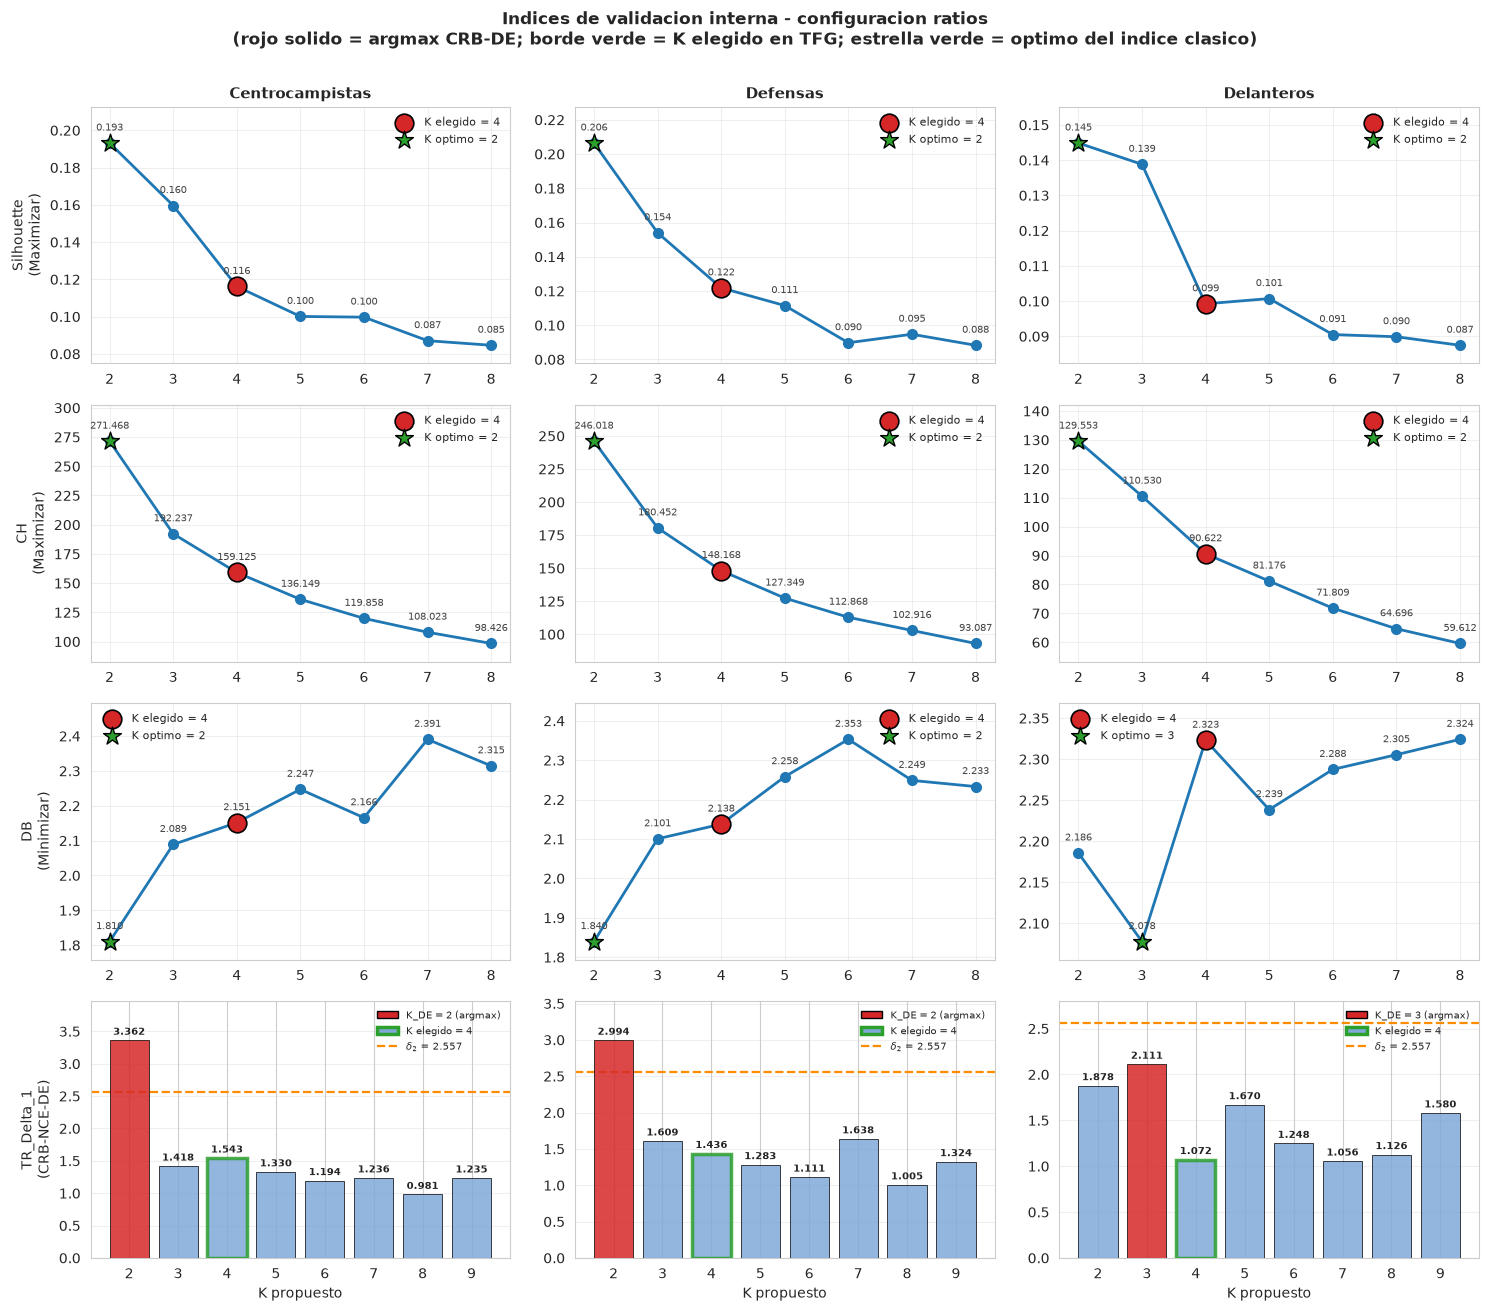

In [11]:
# Grafico mejorado: 4 filas (Sil, CH, DB, TR_Delta_1) x 3 columnas (lineas)
# Configuracion: ratios (cambiar a 'volumen' si se quiere ver la otra)
TIPO_GRAFICO = 'ratios'

fig, axes = plt.subplots(4, 3, figsize=(15, 13))
indices_info = [
    ('Silhouette', True,  'Maximizar'),
    ('CH',         True,  'Maximizar'),
    ('DB',         False, 'Minimizar'),
]

for col, (pos, nombre, k_elegido) in enumerate(lineas_config):
    df_idx = indices_clasicos[(nombre, TIPO_GRAFICO)]
    ks_clas = df_idx['K'].values

    # ---- Filas 0-2: indices clasicos ----
    for row, (indice, maximizar, criterio) in enumerate(indices_info):
        ax = axes[row, col]
        vals = df_idx[indice].values

        # Linea con puntos
        ax.plot(ks_clas, vals, marker='o', color='#1f77b4',
                linewidth=2, markersize=7, zorder=3)

        # Marcar K elegido (rojo)
        idx_k = list(ks_clas).index(k_elegido)
        ax.scatter([k_elegido], [vals[idx_k]], s=180, color='#d62728',
                   zorder=5, edgecolors='black', linewidth=1.2,
                   label=f'K elegido = {k_elegido}')

        # Marcar K optimo (estrella verde)
        k_opt = ks_clas[vals.argmax()] if maximizar else ks_clas[vals.argmin()]
        idx_opt = list(ks_clas).index(k_opt)
        if k_opt != k_elegido:
            ax.scatter([k_opt], [vals[idx_opt]], s=180, marker='*',
                       color='#2ca02c', zorder=5, edgecolors='black',
                       linewidth=1.0, label=f'K optimo = {k_opt}')

        # Anotar valores numericos sobre cada punto
        for k, v in zip(ks_clas, vals):
            ax.annotate(f'{v:.3f}', (k, v),
                        xytext=(0, 9), textcoords='offset points',
                        ha='center', fontsize=7, color='#444')

        if col == 0: ax.set_ylabel(f'{indice}\n({criterio})', fontsize=10)
        if row == 0: ax.set_title(nombre, fontweight='bold', fontsize=11)
        ax.set_xticks(ks_clas)
        ax.legend(fontsize=8, frameon=False, loc='best')
        ax.grid(True, alpha=0.3)
        # Margen vertical extra para que las anotaciones no se corten
        y_min, y_max = vals.min(), vals.max()
        margen = (y_max - y_min) * 0.18
        ax.set_ylim(y_min - margen*0.5, y_max + margen)

    # ---- Fila 3: tail ratios CRB-NCE ----
    ax = axes[3, col]
    crb = crb_resultados[(nombre, TIPO_GRAFICO)]
    K_tr  = np.array(crb['K_tr'])
    tr_d1 = np.array(crb['tr_delta1'])
    K_DE  = crb['K_DE']

    # IMPORTANTE: el eje X muestra K_estimado = K_tr + 1
    # asi el lector ve directamente el K que cada barra propone
    K_propuesto = K_tr + 1

    # Color por barra: roja la del DE, gris las demas
    colores = ['#d62728' if k == K_DE else '#7fa9d9' for k in K_propuesto]
    bars = ax.bar(K_propuesto, tr_d1, color=colores, edgecolor='black',
                  linewidth=0.6, alpha=0.85, zorder=3)

    # Anotar valores sobre cada barra
    for k, v in zip(K_propuesto, tr_d1):
        ax.annotate(f'{v:.3f}', (k, v),
                    xytext=(0, 4), textcoords='offset points',
                    ha='center', fontsize=7.5, fontweight='bold',
                    color='#222')

    # Resaltar K elegido en el TFG con borde grueso si no coincide con K_DE
    if k_elegido in K_propuesto:
        idx_e = list(K_propuesto).index(k_elegido)
        if k_elegido != K_DE:
            bars[idx_e].set_edgecolor('#2ca02c')
            bars[idx_e].set_linewidth(2.5)

    # Linea horizontal: umbral delta_2 del paper para SSE
    ax.axhline(2.557, color='#ff8c00', linestyle='--', linewidth=1.6,
               label=r'$\delta_2$ = 2.557 (umbral AE, paper)')

    # Leyenda manual
    from matplotlib.patches import Patch
    handles = [
        Patch(facecolor='#d62728', edgecolor='black', label=f'K_DE = {K_DE} (argmax)'),
    ]
    if k_elegido != K_DE:
        handles.append(
            Patch(facecolor='#7fa9d9', edgecolor='#2ca02c',
                  linewidth=2.5, label=f'K elegido = {k_elegido}')
        )
    handles.append(
        plt.Line2D([], [], color='#ff8c00', linestyle='--', linewidth=1.6,
                   label=r'$\delta_2$ = 2.557')
    )
    ax.legend(handles=handles, fontsize=7.5, frameon=False, loc='best')

    if col == 0: ax.set_ylabel('TR_Delta_1\n(CRB-NCE-DE)', fontsize=10)
    ax.set_xlabel('K propuesto')
    ax.set_xticks(K_propuesto)
    ax.grid(True, alpha=0.3, axis='y')
    # Margen vertical superior para anotaciones
    ax.set_ylim(0, max(tr_d1.max() * 1.18, 2.8))

fig.suptitle(f'Indices de validacion interna - configuracion {TIPO_GRAFICO}\n'
             '(rojo solido = argmax CRB-DE; borde verde = K elegido en TFG; '
             'estrella verde = optimo del indice clasico)',
             fontsize=12, fontweight='bold', y=1.005)
plt.tight_layout()
plt.show()

### 2.1 Estabilidad por bootstrap (justificación de K)

In [12]:
def estabilidad_bootstrap(X_scaled, rango_k=range(2, 9), n_bootstrap=15,
                           sample_frac=0.8, random_state=42):
    rng = np.random.RandomState(random_state)
    n = X_scaled.shape[0]
    sample_size = int(n * sample_frac)
    resultados = []
    for k in rango_k:
        particiones, idxs = [], []
        for b in range(n_bootstrap):
            idx = rng.choice(n, size=sample_size, replace=False)
            km = KMeans(n_clusters=k, random_state=b, n_init=10)
            particiones.append(km.fit_predict(X_scaled[idx]))
            idxs.append(idx)
        ari = []
        for i in range(n_bootstrap):
            for j in range(i+1, n_bootstrap):
                comunes = np.intersect1d(idxs[i], idxs[j])
                if len(comunes) < 10: continue
                m_i = dict(zip(idxs[i], particiones[i]))
                m_j = dict(zip(idxs[j], particiones[j]))
                ari.append(adjusted_rand_score(
                    [m_i[c] for c in comunes], [m_j[c] for c in comunes]))
        resultados.append({'K': k,
                           'ARI_mean': np.mean(ari),
                           'ARI_std': np.std(ari)})
    return pd.DataFrame(resultados)

In [13]:
# Guardamos los resultados de estabilidad por (linea, tipo)
resultados_estab = {}
for pos, nombre, k in lineas_config:
    print(f'\n{nombre} ({pos})...')
    df_l = df_r[df_r['Pos'].str.contains(pos, na=False)].copy()
    for tipo, feats in FEATURE_SETS.items():
        Xs = StandardScaler().fit_transform(df_l[feats].fillna(0).values)
        df_est = estabilidad_bootstrap(Xs, range(2, 8), n_bootstrap=15)
        resultados_estab[(nombre, tipo)] = df_est
        ari_str = ' | '.join([f'K={int(r.K)}: {r.ARI_mean:.2f}' for _, r in df_est.iterrows()])
        print(f'  {tipo:8s}  {ari_str}')


Centrocampistas (MF)...


  volumen   K=2: 0.96 | K=3: 0.72 | K=4: 0.84 | K=5: 0.60 | K=6: 0.65 | K=7: 0.59


  ratios    K=2: 0.90 | K=3: 0.93 | K=4: 0.84 | K=5: 0.67 | K=6: 0.62 | K=7: 0.57

Defensas (DF)...


  volumen   K=2: 0.94 | K=3: 0.70 | K=4: 0.66 | K=5: 0.75 | K=6: 0.65 | K=7: 0.57


  ratios    K=2: 0.95 | K=3: 0.91 | K=4: 0.90 | K=5: 0.88 | K=6: 0.74 | K=7: 0.79

Delanteros (FW)...


  volumen   K=2: 0.88 | K=3: 0.80 | K=4: 0.85 | K=5: 0.63 | K=6: 0.66 | K=7: 0.58


  ratios    K=2: 0.94 | K=3: 0.92 | K=4: 0.66 | K=5: 0.79 | K=6: 0.63 | K=7: 0.56


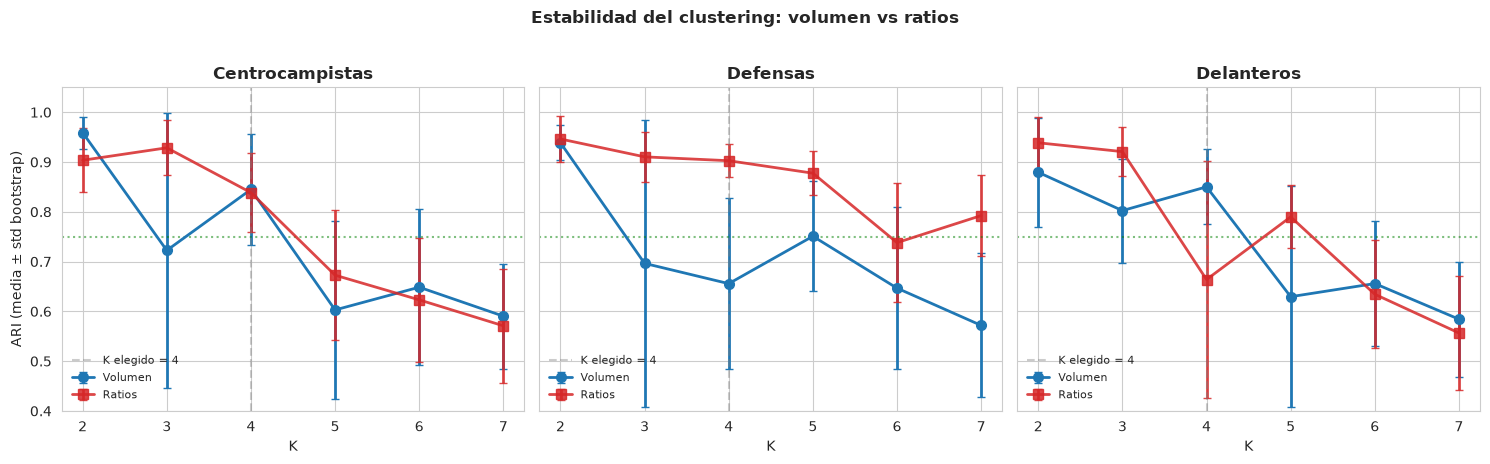

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (pos, nombre, k) in zip(axes, lineas_config):
    est_v = resultados_estab[(nombre, 'volumen')]
    est_r = resultados_estab[(nombre, 'ratios')]
    ax.errorbar(est_v['K'], est_v['ARI_mean'], yerr=est_v['ARI_std'],
                marker='o', capsize=3, color='#1f77b4', linewidth=2,
                label='Volumen', markersize=7)
    ax.errorbar(est_r['K'], est_r['ARI_mean'], yerr=est_r['ARI_std'],
                marker='s', capsize=3, color='#d62728', linewidth=2,
                label='Ratios', markersize=7, alpha=0.85)
    ax.axhline(0.75, color='green', linestyle=':', alpha=0.5)
    ax.axvline(k, color='gray', linestyle='--', alpha=0.4,
               label=f'K elegido = {k}')
    ax.set_title(nombre, fontweight='bold')
    ax.set_xlabel('K')
    ax.set_ylim(0.4, 1.05)
    ax.legend(loc='lower left', frameon=False, fontsize=8)
axes[0].set_ylabel('ARI (media ± std bootstrap)')
fig.suptitle('Estabilidad del clustering: volumen vs ratios',
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Interpretación**:
- Todas las líneas presentan el ARI más alto en K=2, lo que refleja la macro-estructura básica (ofensivo/defensivo) que también detectan los índices clásicos.
- Más allá de K=2, la estabilidad se mantiene en valores altos (ARI > 0,66 en todas las configuraciones), sin caídas bruscas que descarten ninguna de las particiones consideradas.
- Con la configuración de ratios, los clusters de defensas son especialmente reproducibles (ARI elevado), lo que indica que el filtrado del sesgo de estilo de equipo deja una estructura de roles nítida.
- En delanteros con ratios, K=3 supera en estabilidad a K=4: **estadísticamente** K=3 es más reproducible, por lo que conviene comprobar si el cuarto cluster aporta granularidad táctica útil (se analiza a continuación). Los valores numéricos exactos de ARI figuran en la salida de la celda de bootstrap y en la celda de resumen de valores de referencia.

### 2.1b ¿K=3 o K=4 en delanteros? Justificación semántica

El bootstrap favorece K=3 (más estable), pero queremos evaluar si K=4 aporta una **granularidad táctica útil** — un cluster extra que represente un rol diferenciado, no un subgrupo artificial.

Comparamos los jugadores que emergen en cada cluster con K=3 y con K=4, en ambas configuraciones de features:

In [15]:
def comparar_K_fw(tipo='ratios'):
    feats = FEATURE_SETS[tipo]
    df_fw_tmp = df_r[df_r['Pos'].str.contains('FW', na=False)].copy().reset_index(drop=True)
    Xs = StandardScaler().fit_transform(df_fw_tmp[feats].fillna(0).values)

    for K in [3, 4]:
        print(f'\n{"="*72}\n  DELANTEROS — {tipo.upper()} — K = {K}\n{"="*72}')
        km = KMeans(n_clusters=K, random_state=42, n_init=10)
        lab = km.fit_predict(Xs)
        for c in range(K):
            mask = lab == c
            sub = df_fw_tmp[mask]
            z = Xs[mask].mean(axis=0)
            top_idx = np.argsort(z)[::-1][:5]
            top_feats = ', '.join([f'{feats[i]}({z[i]:+.1f})' for i in top_idx])
            print(f'\n  C{c} ({len(sub)} jug.): {", ".join(sub["Player"].head(8).tolist())}')
            print(f'  Top z+: {top_feats}')

comparar_K_fw('volumen')
comparar_K_fw('ratios')


  DELANTEROS — VOLUMEN — K = 3

  C0 (271 jug.): Borja Iglesias, Juanmi, Cyle Larin, Sergio León, Youssef En-Nesyri, Rafa Mir, Raúl García, Gorka Guruzeta
  Top z+: xG/90(+0.6), AerialW/90(+0.6), G-PK/90(+0.4), SoT/90(+0.4), Gls/90(+0.4)

  C1 (129 jug.): Jesús Navas, Óliver Torres, Iker Muniain, Iago Aspas, Marco Asensio, Karim Benzema, Vinicius Júnior, Rodrygo
  Top z+: TotDistPasses/90(+1.5), PassesAttempted/90(+1.5), PassesCompleted/90(+1.5), Touches/90(+1.4), PassesProgressive/90(+1.4)

  C2 (271 jug.): Luiz Henrique, Ayoze Pérez, Rodrigo, Aitor Ruibal, Óscar Plano, Gonzalo Plata, Iván Sánchez, Bryan
  Top z+: Tkl+Int/90(+0.5), Recov/90(+0.4), Int/90(+0.4), TklW/90(+0.4), ShortPasses%(+0.4)

  DELANTEROS — VOLUMEN — K = 4

  C0 (244 jug.): Borja Iglesias, Juanmi, Cyle Larin, Sergio León, Youssef En-Nesyri, Rafa Mir, Raúl García, Gorka Guruzeta
  Top z+: xG/90(+0.7), AerialW/90(+0.6), G-PK/90(+0.5), xGD/90(+0.5), SoT/90(+0.5)

  C1 (73 jug.): Aitor Ruibal, Jesús Navas, Óliver Torr

**Análisis y decisión**:

- En **ratios** con K=3, el cluster de perfiles no finalizadores (C2: Luiz Henrique, Ayoze, Ocampos) agrupa dos tipos de extremo muy distintos bajo una misma etiqueta: los que destacan por trabajo defensivo (Tkl+Int, Recov altos) y los que destacan por regate y creación por banda.
- Al subir a **K=4 ratios**, ese macro-cluster se parte en dos grupos semánticamente **distintos**:
  - **Extremos trabajadores** (Luiz Henrique, Ayoze, Jesús Navas): perfil de contención, con Tkl+Int, Int y Recov muy altos (z ≈ +1,3).
  - **Extremos de desequilibrio** (Nico Williams, Ocampos, Papu Gómez): perfil de regate y creación por toque (SCA_per_touch, Drib_per_touch).
- Esta separación es **tácticamente relevante para scouting** — no querrás fichar a un extremo de contención si buscas un desequilibrante puro, aunque ambos aparezcan juntos con K=3.
- Los clusters de *9 de área* (En-Nesyri, Borja Iglesias) y *creadores puros* (Benzema, Vinicius, Dembélé) se mantienen bien definidos en ambas resoluciones.

**Conclusión**: aunque K=3 sea estadísticamente algo más estable, **K=4 aporta granularidad semántica** que justifica su uso para scouting, al distinguir dos perfiles de extremo que el mercado y los entrenadores tratan de forma muy diferente. Aceptamos una leve pérdida de estabilidad (los valores de ARI exactos figuran en la salida del bootstrap) a cambio de una partición más útil para el objetivo del TFG. Esta es una decisión defendible: los índices de validación interna no miden utilidad práctica.

**Fijamos K=4 para delanteros** en el resto del notebook.

### 2.2 K-Means + GMM + Fuzzy en ambas configuraciones

Aplicamos los tres métodos a cada (línea, tipo). El diccionario `clusterings` queda como:

```
clusterings['Centrocampistas']['volumen'] = {df, Xs, k, res, ...}
clusterings['Centrocampistas']['ratios']  = {df, Xs, k, res, ...}
clusterings['Defensas']['volumen']        = ...
...
```

In [16]:
def fuzzy_cmeans(X, c, m=2.0, max_iter=150, tol=1e-5, random_state=42):
    """Fuzzy C-Means vectorizado."""
    rng = np.random.RandomState(random_state)
    n, d = X.shape
    U = rng.rand(n, c)
    U = U / U.sum(axis=1, keepdims=True)
    exp = 2.0 / (m - 1.0)
    for _ in range(max_iter):
        Um = U ** m
        centros = (Um.T @ X) / Um.sum(axis=0)[:, None]
        dist = np.sqrt(((X[:, None, :] - centros[None, :, :]) ** 2).sum(axis=2))
        dist = np.maximum(dist, 1e-10)
        ratios = (dist[:, :, None] / dist[:, None, :]) ** exp
        U_new = 1.0 / ratios.sum(axis=2)
        if np.abs(U_new - U).max() < tol:
            break
        U = U_new
    return centros, U, U.argmax(axis=1)


def alinear_etiquetas(labels_ref, labels_otros, proba_otros=None, U_otros=None, k=None):
    """
    Alinea las etiquetas de un clustering con las de KMeans como referencia
    usando el algoritmo hungaro (linear_sum_assignment).

    Construye una matriz de confusion entre labels_ref y labels_otros,
    y encuentra la permutacion de etiquetas que maximiza la coincidencia.
    Reordena tambien las columnas de proba y U si se proporcionan.
    """
    from scipy.optimize import linear_sum_assignment
    if k is None:
        k = len(np.unique(labels_ref))
    # Matriz de confusion: confusion[i,j] = nº jugadores con ref=i y otros=j
    confusion = np.zeros((k, k), dtype=int)
    for r, o in zip(labels_ref, labels_otros):
        confusion[r, o] += 1
    # Algoritmo hungaro: maximizar la diagonal (negamos para minimizar)
    _, col_ind = linear_sum_assignment(-confusion)
    # col_ind[i] = etiqueta en 'otros' que corresponde a la etiqueta i de 'ref'
    # Construir mapa inverso: etiqueta_otros -> etiqueta_ref
    mapa = np.zeros(k, dtype=int)
    for ref_c, otros_c in enumerate(col_ind):
        mapa[otros_c] = ref_c
    # Reasignar etiquetas
    labels_alineados = np.array([mapa[l] for l in labels_otros])
    # Reordenar columnas de proba y U si se proporcionan
    proba_alineada = None
    U_alineada = None
    if proba_otros is not None:
        # La columna c de proba correspondia al cluster c de 'otros'
        # Ahora hay que reordenarla segun el mapa
        orden_cols = np.argsort(mapa)  # col_ind hace: ref_c <- otros_col_ind[ref_c]
        proba_alineada = proba_otros[:, col_ind]
    if U_otros is not None:
        U_alineada = U_otros[:, col_ind]
    return labels_alineados, proba_alineada, U_alineada


def aplicar_3_metodos(X_scaled, k):
    """Aplica K-Means, GMM y Fuzzy C-Means y alinea sus etiquetas con KMeans."""
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lab_km = km.fit_predict(X_scaled)
    gmm = GaussianMixture(n_components=k, random_state=42,
                          covariance_type='full', n_init=3)
    gmm.fit(X_scaled)
    lab_gmm_raw = gmm.predict(X_scaled)
    proba_raw   = gmm.predict_proba(X_scaled)
    _, U_fuzzy_raw, lab_fuzzy_raw = fuzzy_cmeans(X_scaled, c=k)
    # Alinear etiquetas de GMM y Fuzzy con KMeans como referencia
    lab_gmm, proba, _ = alinear_etiquetas(
        lab_km, lab_gmm_raw, proba_otros=proba_raw, k=k)
    lab_fuzzy, _, U_fuzzy = alinear_etiquetas(
        lab_km, lab_fuzzy_raw, U_otros=U_fuzzy_raw, k=k)
    return {'km': lab_km, 'gmm': lab_gmm, 'proba': proba,
            'fuzzy': lab_fuzzy, 'U_fuzzy': U_fuzzy}


In [17]:
# Doble pipeline: cada línea con cada configuración
clusterings = {nombre: {} for _, nombre, _ in lineas_config}

for pos, nombre, k in lineas_config:
    print(f'\n--- {nombre} ---')
    df_l_base = (df_r[df_r['Pos'].str.contains(pos, na=False)]
                  .copy().reset_index(drop=True))
    for tipo, feats in FEATURE_SETS.items():
        Xs = StandardScaler().fit_transform(df_l_base[feats].fillna(0).values)
        res = aplicar_3_metodos(Xs, k)

        # Crear copia del df y añadir columnas de clustering
        df_l = df_l_base.copy()
        df_l['km']    = res['km']
        df_l['gmm']   = res['gmm']
        df_l['fuzzy'] = res['fuzzy']
        df_l['gmm_max_p']    = res['proba'].max(axis=1)
        df_l['gmm_second_p'] = np.sort(res['proba'], axis=1)[:, -2]
        df_l['gmm_ambig']    = df_l['gmm_second_p'] / df_l['gmm_max_p']

        clusterings[nombre][tipo] = {
            'df': df_l, 'Xs': Xs, 'res': res, 'k': k,
            'features': feats
        }

        ari_km_gmm = adjusted_rand_score(res['km'], res['gmm'])
        ari_km_fz  = adjusted_rand_score(res['km'], res['fuzzy'])
        print(f'  {tipo:8s}: KM-GMM={ari_km_gmm:.3f}  KM-Fuzzy={ari_km_fz:.3f}')

    # Concordancia entre las dos configuraciones
    lab_v = clusterings[nombre]['volumen']['res']['km']
    lab_r = clusterings[nombre]['ratios']['res']['km']
    print(f'  ARI volumen vs ratios: {adjusted_rand_score(lab_v, lab_r):.3f}')


--- Centrocampistas ---


  volumen : KM-GMM=0.504  KM-Fuzzy=0.452


  ratios  : KM-GMM=0.585  KM-Fuzzy=0.460
  ARI volumen vs ratios: 0.365

--- Defensas ---


  volumen : KM-GMM=0.551  KM-Fuzzy=0.324


  ratios  : KM-GMM=0.404  KM-Fuzzy=0.478
  ARI volumen vs ratios: 0.280

--- Delanteros ---


  volumen : KM-GMM=0.751  KM-Fuzzy=0.545


  ratios  : KM-GMM=0.752  KM-Fuzzy=0.309
  ARI volumen vs ratios: 0.541


In [18]:
# === RESUMEN DE VALORES DE REFERENCIA DEL CLUSTERING ===
# Recopila en un solo lugar los valores numericos clave del clustering
# (tamano de muestra, ARI por K, jugadores por linea), que sirven de
# referencia para la discusion de resultados.
print('='*60)
print('VALORES DE REFERENCIA DEL CLUSTERING')
print('='*60)

print(f'\nMuestra: {len(df_filtrado_raw)} filas tras filtro >900 min, '
      f'{len(df_filtrado)} jugadores tras agregar transferidos.\n')

print('ARI de estabilidad por linea/tipo (K elegido vs alternativas):')
for (nombre, tipo), df_est in resultados_estab.items():
    fila_k = {int(r.K): r.ARI_mean for _, r in df_est.iterrows()}
    k2 = fila_k.get(2, float('nan'))
    k3 = fila_k.get(3, float('nan'))
    k4 = fila_k.get(4, float('nan'))
    print(f'  {nombre:16s} {tipo:8s}  K2={k2:.2f}  K3={k3:.2f}  K4={k4:.2f}')

print('\nNumero de jugadores por linea (config ratios):')
for nombre in ['Centrocampistas', 'Defensas', 'Delanteros']:
    n = len(clusterings[nombre]['ratios']['df'])
    print(f'  {nombre:16s}: {n} jugadores')

print('\nARI volumen vs ratios por linea:')
from sklearn.metrics import adjusted_rand_score
for nombre in ['Centrocampistas', 'Defensas', 'Delanteros']:
    lab_v = clusterings[nombre]['volumen']['res']['km']
    lab_r = clusterings[nombre]['ratios']['res']['km']
    print(f'  {nombre:16s}: {adjusted_rand_score(lab_v, lab_r):.3f}')

VALORES DE REFERENCIA DEL CLUSTERING

Muestra: 2173 filas tras filtro >900 min, 2153 jugadores tras agregar transferidos.

ARI de estabilidad por linea/tipo (K elegido vs alternativas):
  Centrocampistas  volumen   K2=0.96  K3=0.72  K4=0.84
  Centrocampistas  ratios    K2=0.90  K3=0.93  K4=0.84
  Defensas         volumen   K2=0.94  K3=0.70  K4=0.66
  Defensas         ratios    K2=0.95  K3=0.91  K4=0.90
  Delanteros       volumen   K2=0.88  K3=0.80  K4=0.85
  Delanteros       ratios    K2=0.94  K3=0.92  K4=0.66

Numero de jugadores por linea (config ratios):
  Centrocampistas : 953 jugadores
  Defensas        : 898 jugadores
  Delanteros      : 671 jugadores

ARI volumen vs ratios por linea:
  Centrocampistas : 0.365
  Defensas        : 0.280
  Delanteros      : 0.541


### 2.3 Inspección de clusters en cada configuración

**Importante**: la numeración 0/1/2/3 de los clusters NO coincide entre volumen y ratios. Hay que asignar etiquetas tácticas separadas para cada configuración.

In [19]:
def mostrar_clusters(nombre, tipo, n_jugadores=8, n_features=5):
    data = clusterings[nombre][tipo]
    df_l, Xs, k, feats = data['df'], data['Xs'], data['k'], data['features']
    labels = df_l['km'].values

    print(f'\n{"="*72}')
    print(f'  {nombre.upper()} — configuración: {tipo.upper()}')
    print(f'{"="*72}')

    for c in range(k):
        sub = df_l[labels == c]
        z = Xs[labels == c].mean(axis=0)
        top_idx = np.argsort(z)[::-1][:n_features]
        bot_idx = np.argsort(z)[:n_features]

        # Distribución posicional (DF, MF, FW)
        pos_str = ', '.join([f'{p}:{c_}' for p, c_ in
                              sub['Pos'].value_counts().head(3).items()])

        print(f'\n  CLUSTER {c} ({len(sub)} jugadores) — Pos: {pos_str}')
        print(f'  Ejemplos: {", ".join(sub["Player"].head(n_jugadores).tolist())}')
        print(f'  Top features (z+):  ' + ', '.join(
            [f"{feats[i]} ({z[i]:+.1f})" for i in top_idx]))
        print(f'  Bottom features:    ' + ', '.join(
            [f"{feats[i]} ({z[i]:+.1f})" for i in bot_idx]))

for nombre in ['Centrocampistas', 'Defensas', 'Delanteros']:
    for tipo in ['volumen', 'ratios']:
        mostrar_clusters(nombre, tipo)


  CENTROCAMPISTAS — configuración: VOLUMEN

  CLUSTER 0 (166 jugadores) — Pos: MF:138, DF,MF:15, MF,DF:7
  Ejemplos: William Carvalho, Guido Rodríguez, Joan Jordán, Mikel Vesga, Fran Beltrán, Dani Ceballos, Toni Kroos, Aurélien Tchouaméni
  Top features (z+):  TotDistPasses/90 (+1.6), MediumPassesCompleted/90 (+1.6), PassesCompleted/90 (+1.6), PassesAttempted/90 (+1.6), Touches/90 (+1.6)
  Bottom features:    SoT/90 (-0.5), Sh/90 (-0.5), xG/90 (-0.5), xGD/90 (-0.5), G-PK/90 (-0.5)

  CLUSTER 1 (310 jugadores) — Pos: MF:222, DF,MF:49, MF,DF:21
  Ejemplos: Andrés Guardado, Álvaro Aguado, Martin Hongla, Roque Mesa, Monchu, Kike Pérez, Nemanja Gudelj, Pape Gueye
  Top features (z+):  Clr/90 (+0.6), Int/90 (+0.4), Tkl+Int/90 (+0.4), MediumPasses% (+0.4), Aerial% (+0.4)
  Bottom features:    Sh/90 (-0.7), SoT/90 (-0.7), SCA/90 (-0.7), xG/90 (-0.7), xAG/90 (-0.6)

  CLUSTER 2 (325 jugadores) — Pos: FW,MF:160, MF,FW:82, MF:60
  Ejemplos: Ayoze Pérez, Rodrigo, Óscar Plano, Iván Sánchez, Papu G

### 2.4 Asignación de etiquetas tácticas

A cada cluster se le asigna una etiqueta táctica interpretable a partir de sus features dominantes (las de mayor z-score medio) y de los jugadores más representativos. La estructura del diccionario es `ETIQUETAS_ROLES[línea][tipo][cluster_id] = nombre`.

Las etiquetas se asignan por **número de cluster**, pero conviene recordar que K-Means puede reordenar los clusters si cambian los datos de entrada; por eso, en los pasos posteriores (pesos expertos, rating, recomendador) las etiquetas se resuelven a través de este diccionario y no se codifican números de cluster fijos. La celda siguiente permite verificar que cada etiqueta corresponde a las features dominantes de su cluster.

In [20]:
ETIQUETAS_ROLES = {
    'Centrocampistas': {
        # VOLUMEN K=4
        # C0: TotDist, MediumPasses, Touches -> organizadores | C1: Clr, Int, Tkl+Int -> defensivos
        # C2: Sh, SoT, xG -> atacantes | C3: xAG, xA, KP, PPA, SCA -> creadores
        'volumen': {
            0: 'Organizadores de posesión',
            1: 'Mediocentros defensivos',
            2: 'Atacantes / extremos',
            3: 'Creadores / mediapuntas'
        },
        # RATIOS K=4
        # C0: Int, Clr, Tkl+Int -> defensivos | C1: PrgPass, F3_ratio -> organizadores
        # C2: xAG, xA, SCA, GCA, KP muy altos -> creadores élite | C3: SCA_per_touch, SoT, Sh, xG -> atacantes
        'ratios': {
            0: 'Mediocentros defensivos',
            1: 'Organizadores de posesión',
            2: 'Creadores élite',
            3: 'Atacantes / extremos'
        }
    },
    'Defensas': {
        # VOLUMEN K=4
        # C0: Clr, xGA, Int, AerialW -> centrales contundentes | C1: SCA, Sh, xAG -> laterales ofensivos
        # C2: PPA, xA, KP, CrsPA -> laterales creadores | C3: MediumPasses, TotDist -> centrales con salida
        'volumen': {
            0: 'Centrales contundentes',
            1: 'Laterales generalistas',
            2: 'Laterales creadores',
            3: 'Centrales con salida'
        },
        # RATIOS K=4
        # C0: SCA_per_touch, xAG, KP, SCA, GCA -> laterales creadores | C1: Clr, AerialW -> centrales contundentes
        # C2: FinalThird, F3_ratio, Passes%, LongPasses% -> centrales con salida | C3: CrsPA, TklW, PPA, Dribbles -> laterales generalistas
        'ratios': {
            0: 'Laterales creadores',
            1: 'Centrales contundentes',
            2: 'Centrales con salida',
            3: 'Laterales generalistas'
        }
    },
    'Delanteros': {
        # VOLUMEN K=4
        # C0: xG, AerialW, Gls -> 9 de área | C1: MediumPasses, PrgDist, Recov -> creadores de posesión
        # C2: SCA, PPA, xA, KP -> extremos de élite | C3: Tkl+Int, TklW, Recov -> extremos trabajadores
        'volumen': {
            0: '9 de área',
            1: 'Creadores de posesión',
            2: 'Extremos de élite',
            3: 'Extremos trabajadores'
        },
        # RATIOS K=4
        # C0: SCA_per_touch, Drib_per_touch -> extremos de desequilibrio | C1: AerialW, xG, xG_per_shot, Gls -> 9 de área
        # C2: SCA, xA, xAG, KP muy altos -> creadores puros | C3: Tkl+Int, Int, Recov -> extremos trabajadores
        'ratios': {
            0: 'Extremos de desequilibrio',
            1: '9 de área',
            2: 'Creadores puros',
            3: 'Extremos trabajadores'
        }
    }
}
print('Etiquetas tácticas asignadas a cada cluster.')

Etiquetas tácticas asignadas a cada cluster.


In [21]:
# Verificacion de las etiquetas tacticas: para cada cluster se imprimen las
# features que mas lo definen (mayor z-score medio) junto con los jugadores
# mas cercanos al centroide. Las features son el criterio objetivo para
# interpretar el rol; los nombres son orientativos. Esto permite comprobar
# que la etiqueta asignada en ETIQUETAS_ROLES se corresponde con el perfil
# estadistico real de cada cluster.
from scipy.spatial.distance import cdist

TIPO_VER = 'ratios'  # cambia a 'volumen' para verificar la otra config

for nombre in ['Centrocampistas', 'Defensas', 'Delanteros']:
    data = clusterings[nombre][TIPO_VER]
    df_l, Xs, k = data['df'].reset_index(drop=True), data['Xs'], data['k']
    feats = data['features']
    labels = data['res']['km']
    print(f'\n{"="*64}')
    print(f'{nombre} ({TIPO_VER})')
    print("="*64)
    for c in range(k):
        mask = labels == c
        centro = Xs[mask].mean(axis=0)
        # Features que mas definen el cluster (mayor z medio)
        z_medio = Xs[mask].mean(axis=0)
        top_feat_idx = np.argsort(z_medio)[::-1][:5]
        top_feats = ', '.join([f'{feats[j]}({z_medio[j]:+.1f})' for j in top_feat_idx])
        # Jugadores mas cercanos al centroide
        dist = cdist(Xs[mask], [centro])[:, 0]
        idx_cluster = np.where(mask)[0]
        top_idx = idx_cluster[np.argsort(dist)[:5]]
        nombres = df_l.iloc[top_idx]['Player'].tolist()
        etiq_actual = ETIQUETAS_ROLES[nombre][TIPO_VER].get(c, '?')
        print(f'\n  C{c} (n={mask.sum()}) [{etiq_actual}]')
        print(f'     Top features: {top_feats}')
        print(f'     Jugadores:    {", ".join(nombres)}')


Centrocampistas (ratios)

  C0 (n=308) [Mediocentros defensivos]
     Top features: Int/90(+0.9), Clr/90(+0.9), Tkl+Int/90(+0.9), TklW/90(+0.8), Recov/90(+0.8)
     Jugadores:    Jerdy Schouten, Adrien Tameze, Marten de Roon, Raphael Guzzo, Fabinho

  C1 (n=288) [Organizadores de posesión]
     Top features: PrgPass_per_touch(+0.6), F3_ratio(+0.5), PrgPass_ratio(+0.5), ShortPasses%(+0.4), MediumPasses%(+0.4)
     Jugadores:    Morlaye Sylla, Óliver Torres, Aaron Ramsey, Mason Mount, Ivan Rakitić

  C2 (n=104) [Creadores élite]
     Top features: xAG/90(+1.9), xA/90(+1.8), SCA/90(+1.8), GCA/90(+1.7), KP/90(+1.7)
     Jugadores:    Leandro Trossard, Cengiz Ünder, Pedro Gonçalves, Vincenzo Grifo, Julian Brandt

  C3 (n=253) [Atacantes / extremos]
     Top features: SCA_per_touch(+0.8), SoT/90(+0.8), Sh/90(+0.7), xG/90(+0.7), KP_ratio(+0.7)
     Jugadores:    Dejan Ljubicic, Michael Breij, Lazaros Lamprou, Léo Baptistão, Mouhamadou Diarra

Defensas (ratios)

  C0 (n=141) [Laterales creado

### 2.5 Visualización: PCA + GMM (configuración a elegir)

In [22]:
# adjustText y umap-learn se instalan en la sección 1.1


>>> Centrocampistas - VOLUMEN <<<


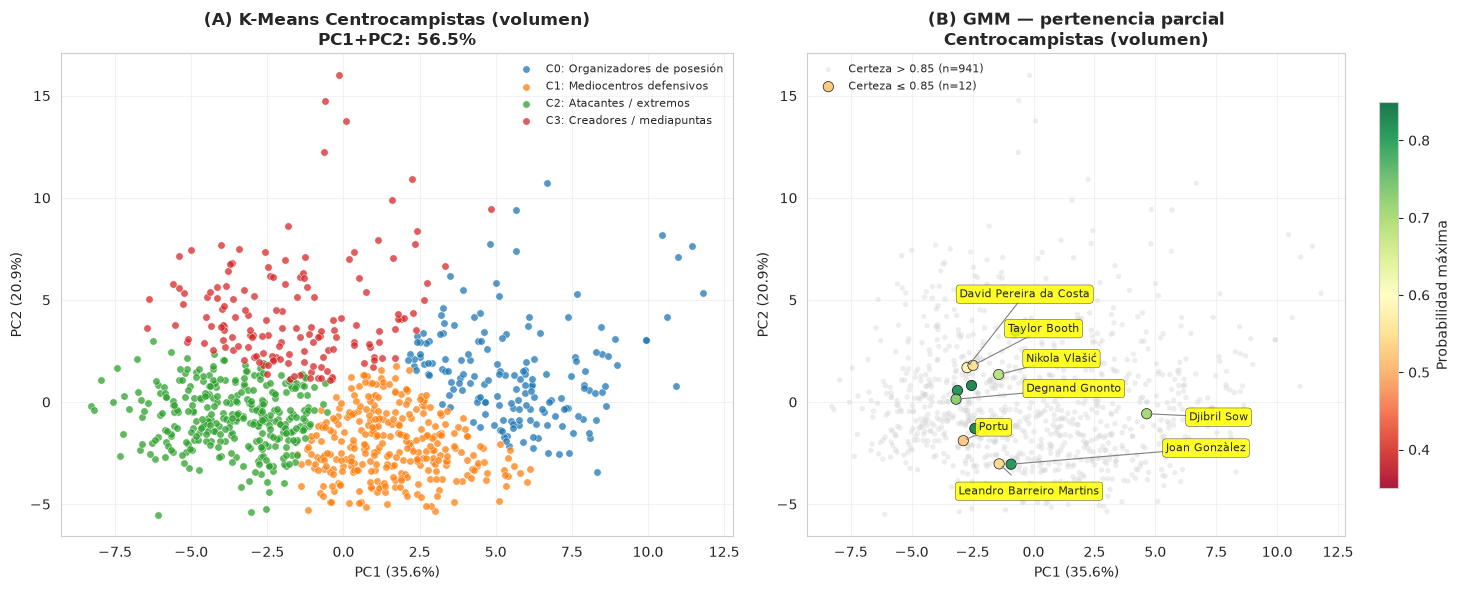


>>> Centrocampistas - RATIOS <<<


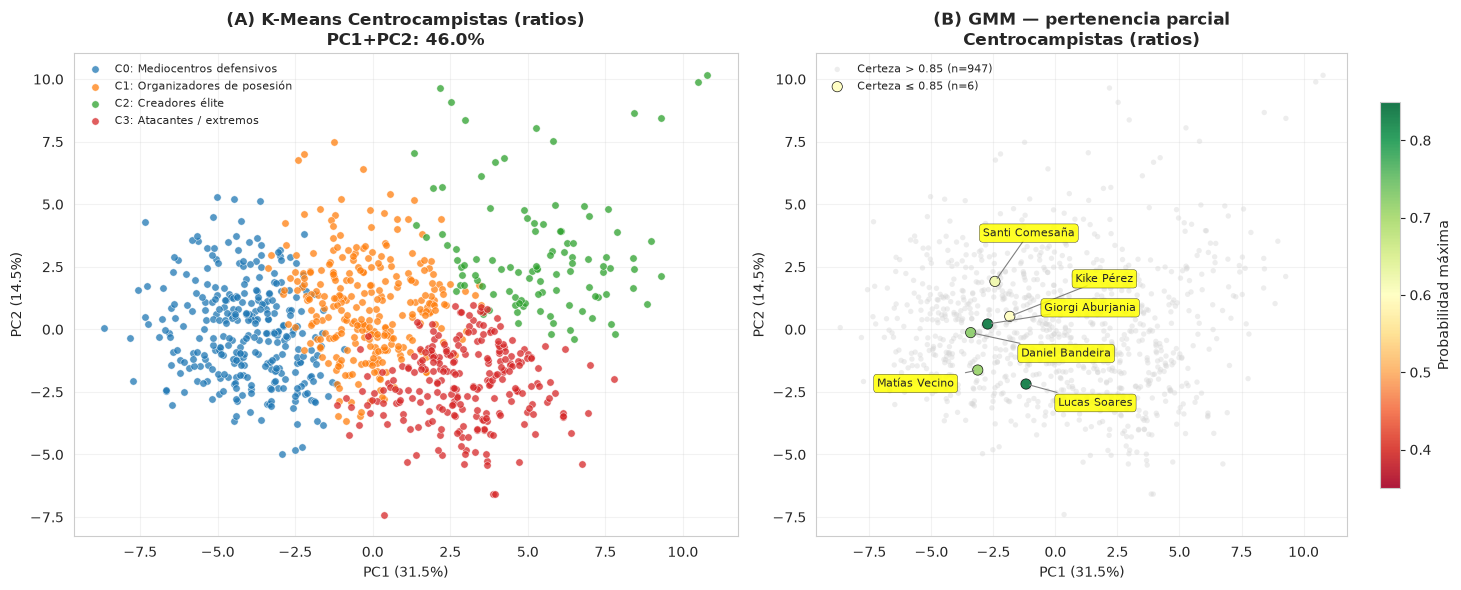


>>> Defensas - VOLUMEN <<<


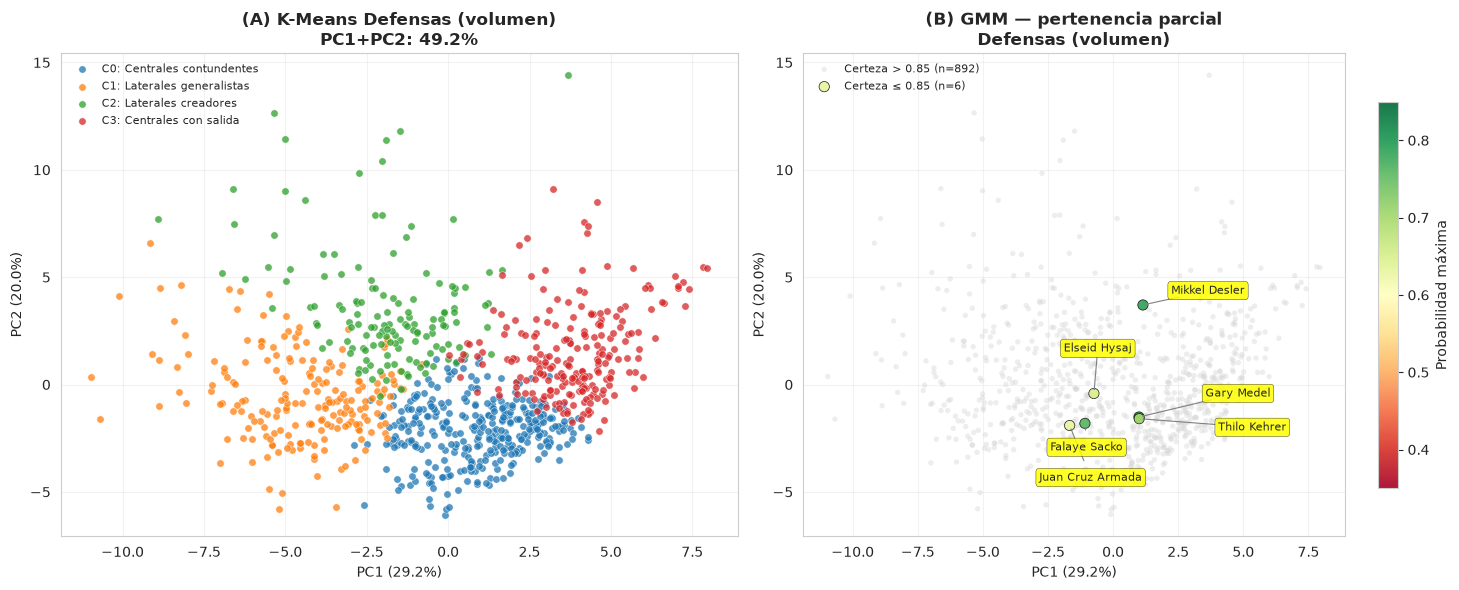


>>> Defensas - RATIOS <<<


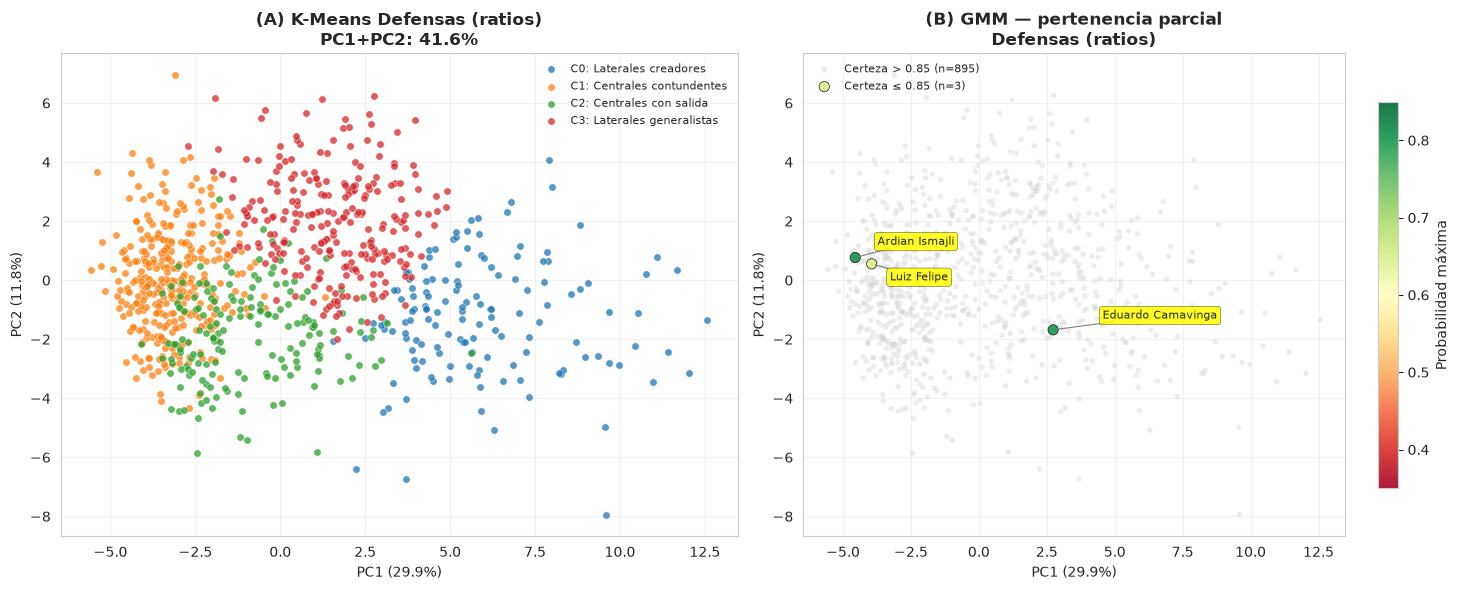


>>> Delanteros - VOLUMEN <<<


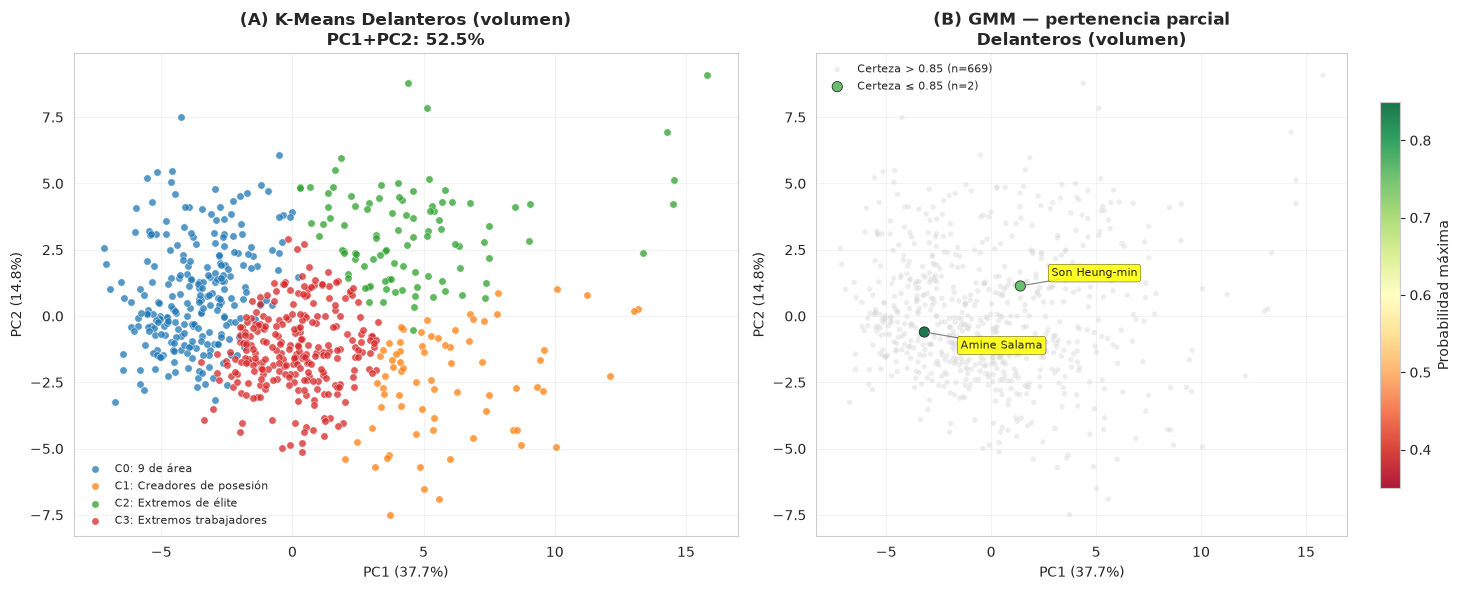


>>> Delanteros - RATIOS <<<


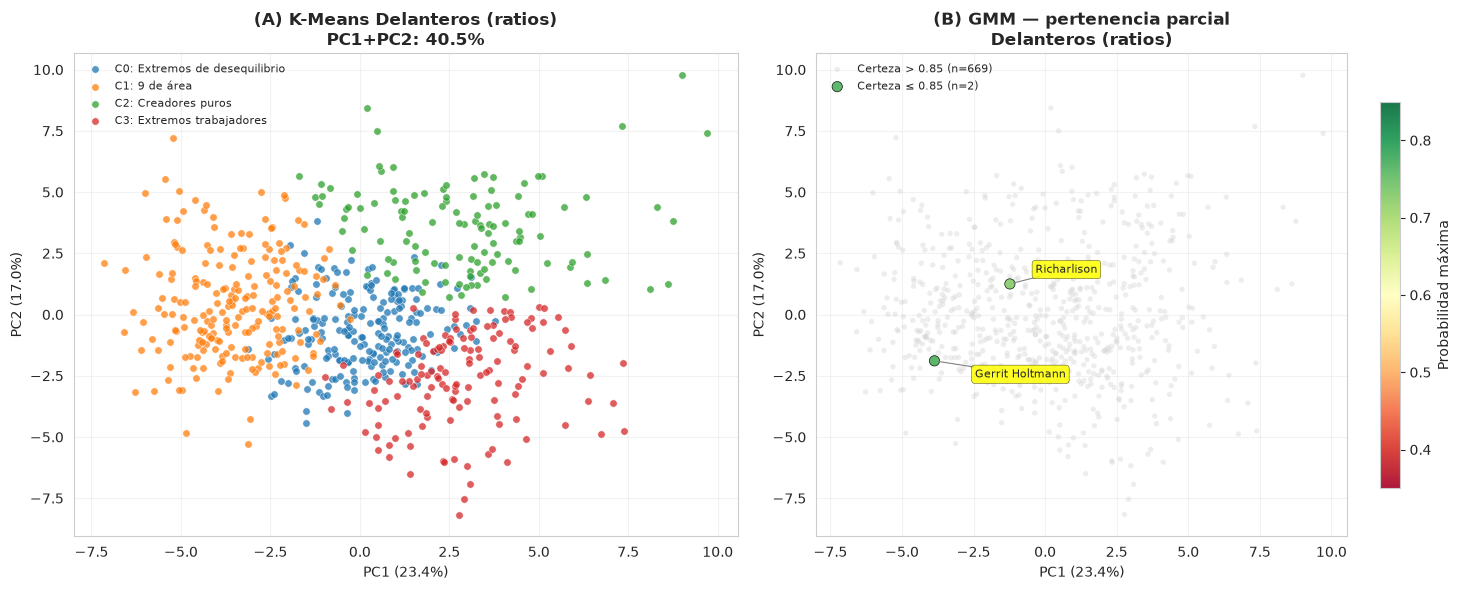

In [23]:
from adjustText import adjust_text

def plot_pca_clusters(nombre_linea, tipo='ratios'):
    data = clusterings[nombre_linea][tipo]
    df_l, Xs, res, k = data['df'], data['Xs'], data['res'], data['k']
    etiquetas = ETIQUETAS_ROLES[nombre_linea][tipo]

    pca = PCA(n_components=2, random_state=42)
    Xp = pca.fit_transform(Xs)

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    # ----- Panel A: K-Means -----
    ax = axes[0]
    for c in range(k):
        m = res['km'] == c
        ax.scatter(Xp[m, 0], Xp[m, 1], c=COLORS[c], s=28, alpha=0.75,
                   edgecolors='white', linewidth=0.4,
                   label=f'C{c}: {etiquetas.get(c, "?")}')
    ax.set_title(f'(A) K-Means {nombre_linea} ({tipo})\n'
                 f'PC1+PC2: {pca.explained_variance_ratio_.sum()*100:.1f}%',
                 fontweight='bold')
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
    ax.legend(frameon=False, loc='best', fontsize=8)
    ax.grid(True, alpha=0.25)

    # ----- Panel B: GMM — pertenencia parcial -----
    ax = axes[1]
    max_p = res['proba'].max(axis=1)
    mask_seguros = max_p > 0.85
    mask_ambig   = ~mask_seguros

    # Jugadores con alta certeza: fondo gris difuminado
    ax.scatter(Xp[mask_seguros, 0], Xp[mask_seguros, 1],
               c='lightgray', s=15, alpha=0.4, edgecolors='none',
               label=f'Certeza > 0.85 (n={mask_seguros.sum()})')

    # Jugadores ambiguos: coloreados por grado de certeza
    if mask_ambig.sum() > 0:
        sc = ax.scatter(Xp[mask_ambig, 0], Xp[mask_ambig, 1],
                        c=max_p[mask_ambig], cmap='RdYlGn',
                        s=55, alpha=0.9, edgecolors='black', linewidth=0.5,
                        vmin=0.35, vmax=0.85,
                        label=f'Certeza ≤ 0.85 (n={mask_ambig.sum()})')
        plt.colorbar(sc, ax=ax, shrink=0.8, label='Probabilidad máxima')

        # Calcular ambigüedad y seleccionar los 8 más ambiguos
        ambig   = np.sort(res['proba'], axis=1)[:, -2] / max_p
        df_temp = df_l.copy()
        df_temp['x'] = Xp[:, 0]
        df_temp['y'] = Xp[:, 1]
        df_temp['a'] = ambig
        top_ambig = df_temp[mask_ambig].nlargest(8, 'a')

        # Crear textos y dejar que adjust_text los recoloque sin solapamiento
        textos = []
        for _, row in top_ambig.iterrows():
            t = ax.text(
                row['x'], row['y'],
                row['Player'],
                fontsize=8,
                bbox=dict(boxstyle='round,pad=0.3', fc='yellow',
                          alpha=0.85, ec='black', linewidth=0.3)
            )
            textos.append(t)

        adjust_text(
            textos,
            ax=ax,
            arrowprops=dict(arrowstyle='->', color='gray', lw=0.8),
            expand=(1.8, 2.2),
            force_text=(0.8, 1.2)
        )

    ax.set_title(f'(B) GMM — pertenencia parcial\n{nombre_linea} ({tipo})',
                 fontweight='bold')
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
    ax.legend(frameon=False, loc='upper left', fontsize=8)
    ax.grid(True, alpha=0.25)

    plt.tight_layout()
    plt.show()


# Visualizamos cada línea con cada configuración
for nombre in ['Centrocampistas', 'Defensas', 'Delanteros']:
    for tipo in ['volumen', 'ratios']:
        print(f'\n>>> {nombre} - {tipo.upper()} <<<')
        plot_pca_clusters(nombre, tipo)

### 2.5b Visualización no lineal: t-SNE y UMAP

PCA proyecta linealmente sobre los ejes de máxima varianza, lo que tiene la ventaja de la **interpretabilidad** —los ejes son combinaciones lineales explícitas de las features— pero también una limitación: cuando los clusters están separados según direcciones de baja varianza, en el plot 2D quedan visualmente solapados aunque estén lejos en el espacio original. Con PC1+PC2 capturando ~40-50 % de la varianza total, casi la mitad de la estructura discriminante queda fuera del plot.

Complementamos PCA con dos métodos de **reducción de dimensionalidad no lineal** que preservan especialmente bien la estructura local:

- **t-SNE** (van der Maaten y Hinton, 2008) modela las distancias mediante distribuciones de probabilidad (gaussiana en el espacio original, t de Student en el espacio 2D) y minimiza la divergencia KL entre ambas. Excelente para visualizar separaciones locales.
- **UMAP** (McInnes et al., 2018) construye un grafo k-NN ponderado y lo embebe preservando las relaciones topológicas. Es más rápido que t-SNE y conserva mejor la estructura global.

**Aviso metodológico importante**: en t-SNE y UMAP, **las distancias absolutas no son interpretables**. Que un cluster aparezca más compacto o más alejado de otro no significa nada en términos de similitud real. Solo se puede afirmar que dos puntos son **vecinos** o no. Por esa razón usamos estos métodos como complemento visual, nunca como métrica cuantitativa.

Si los clusters de K-Means se ven igualmente bien separados en t-SNE/UMAP que en PCA, eso es **evidencia adicional** de que existe estructura real en los datos, no solo varianza global capturada por las primeras componentes principales.


>>> Centrocampistas - VOLUMEN <<<


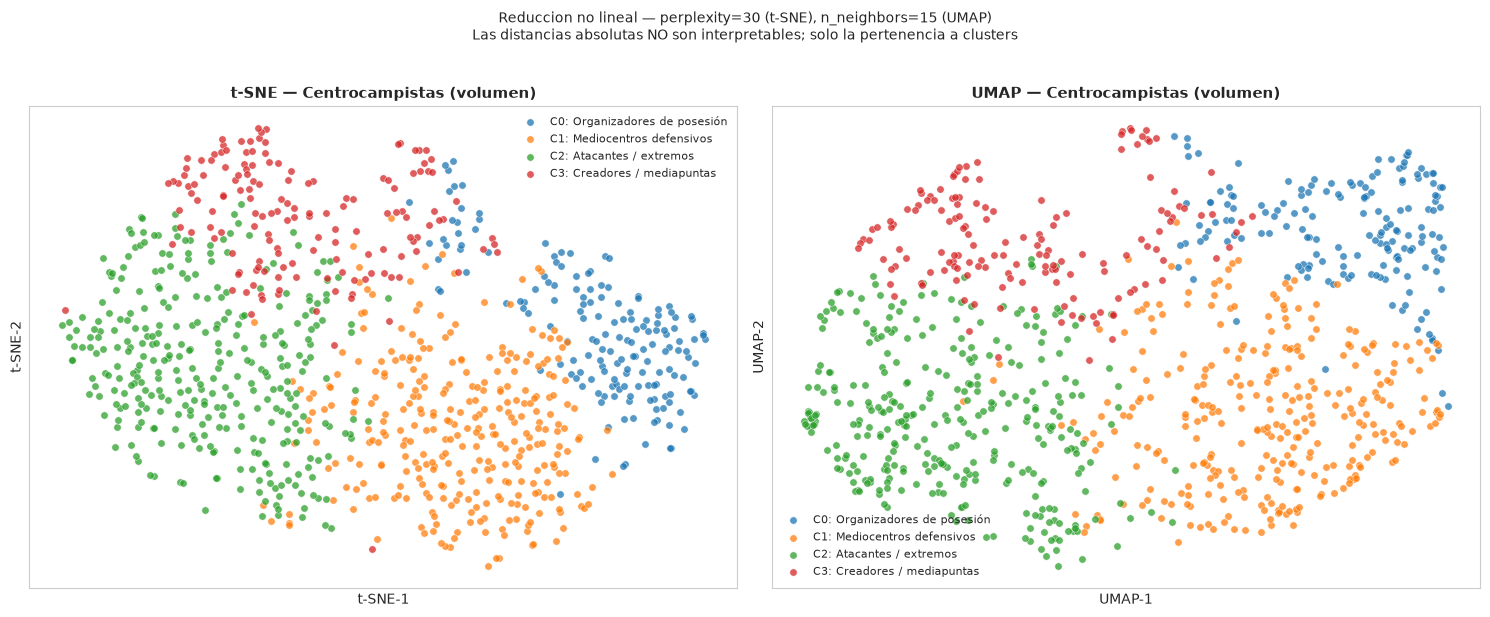


>>> Centrocampistas - RATIOS <<<


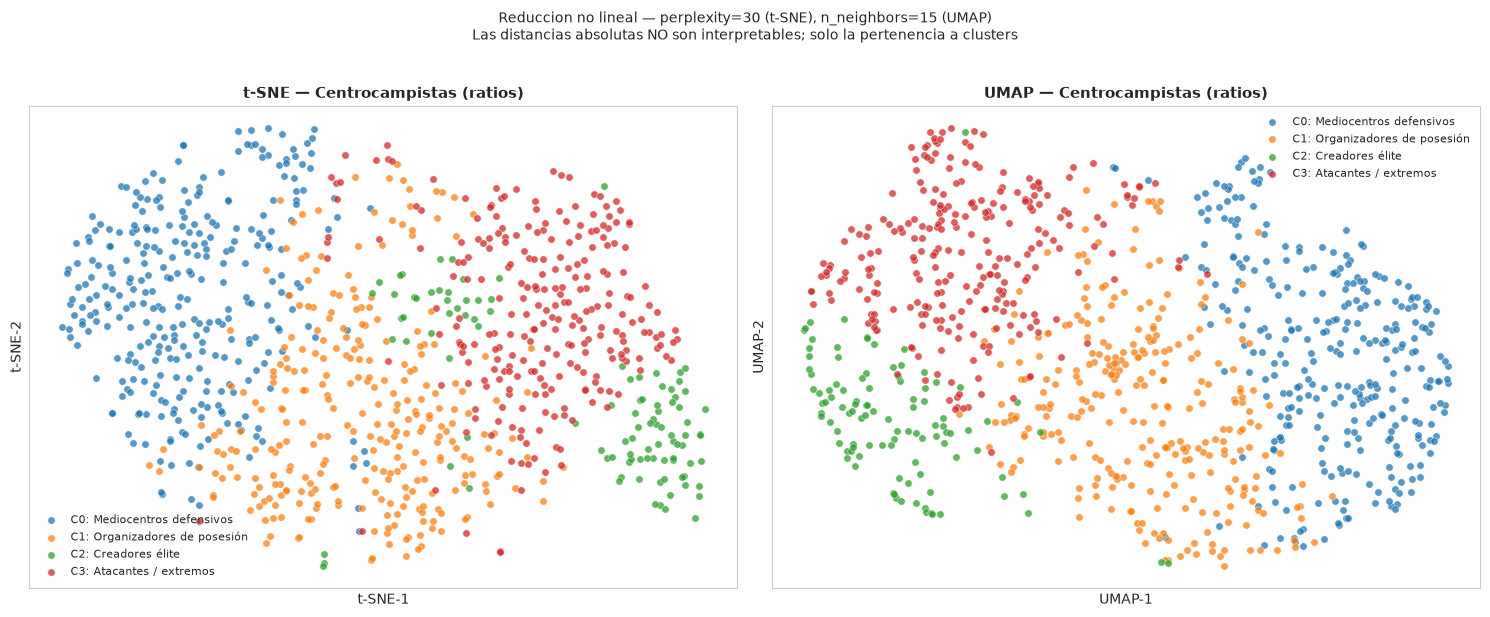


>>> Defensas - VOLUMEN <<<


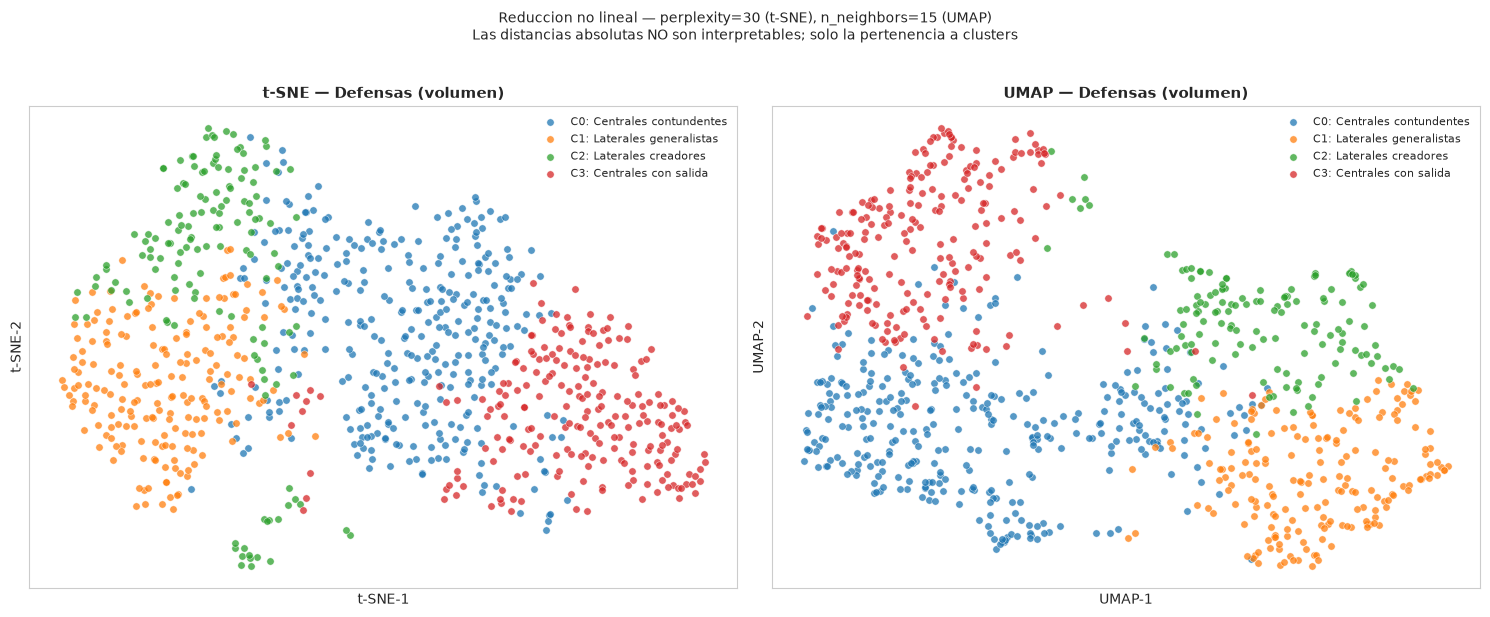


>>> Defensas - RATIOS <<<


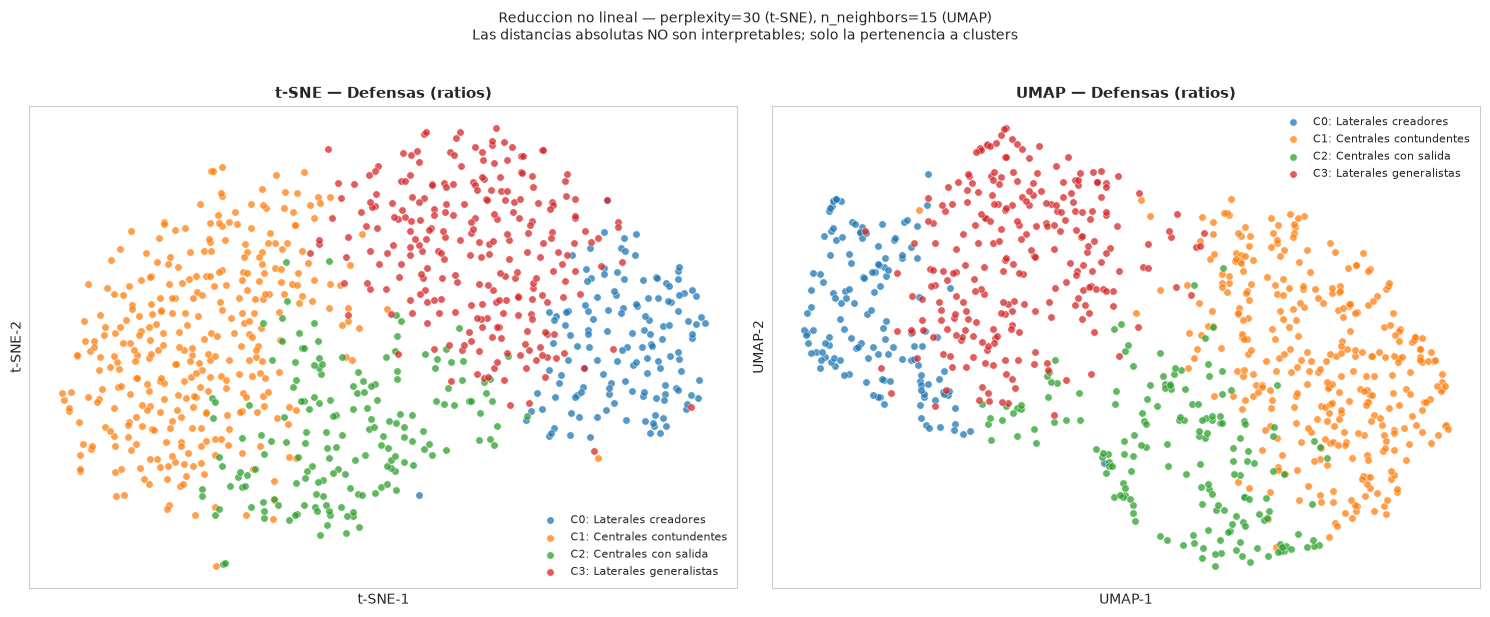


>>> Delanteros - VOLUMEN <<<


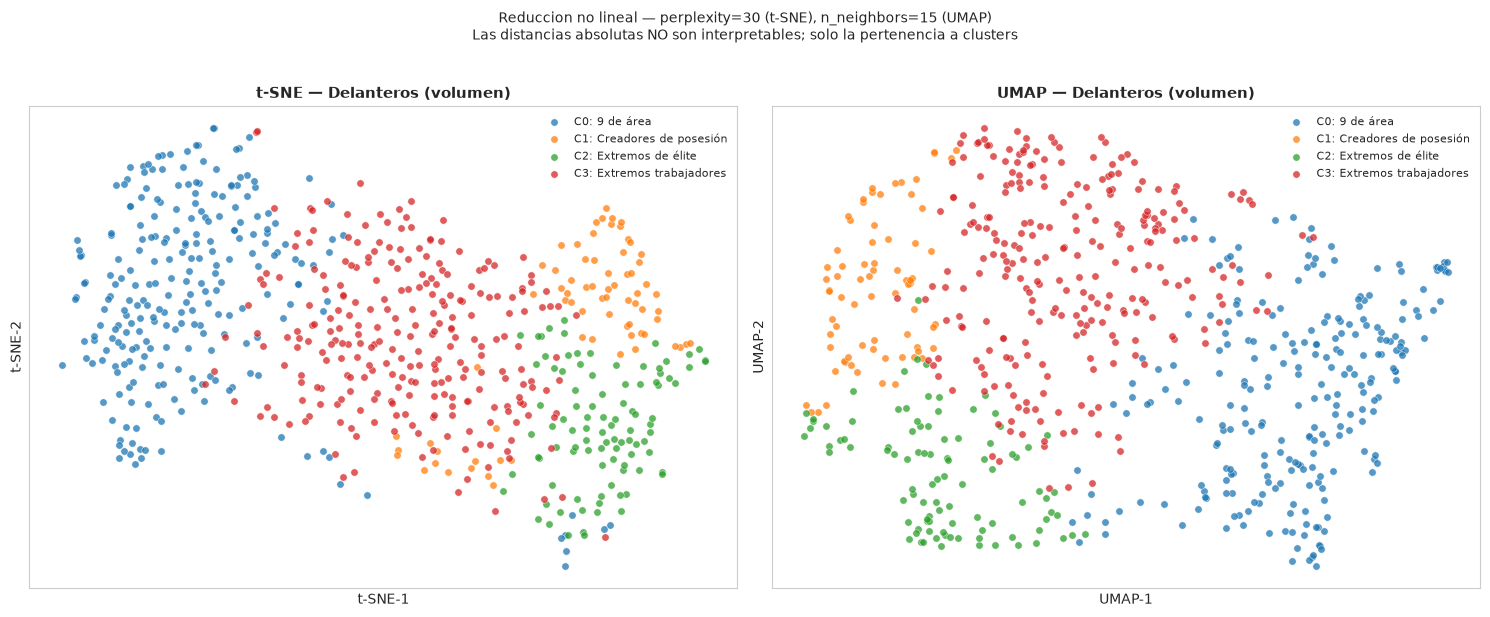


>>> Delanteros - RATIOS <<<


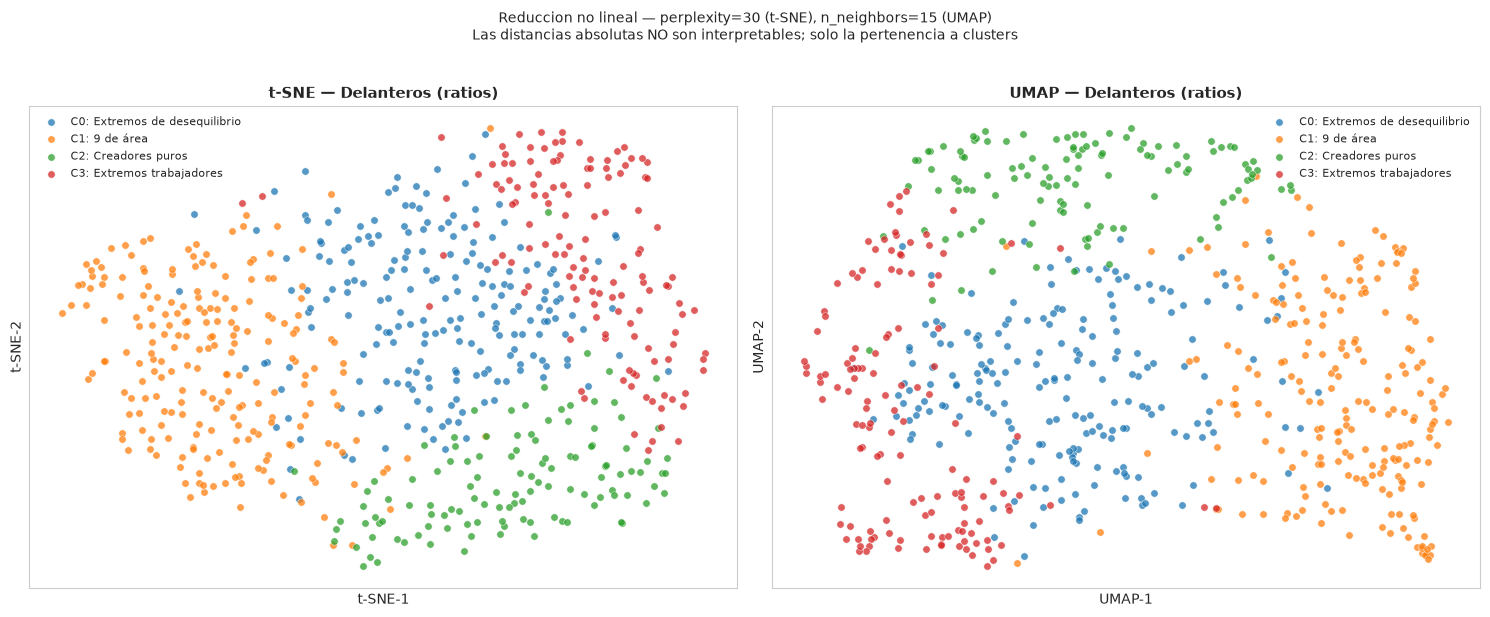

In [24]:
from sklearn.manifold import TSNE
import umap

def plot_tsne_umap_clusters(nombre_linea, tipo='ratios',
                              perplexity=30, n_neighbors=15,
                              random_state=42):
    """
    Genera dos paneles complementarios al PCA: t-SNE y UMAP.
    Ambos usan las mismas etiquetas K-Means que ya teniamos calculadas.

    perplexity (t-SNE):  controla cuantos vecinos efectivos considera. Tipico: 5-50.
    n_neighbors (UMAP):  similar pero para UMAP. Tipico: 10-50.

    Las distancias en estos plots NO son interpretables; solo la pertenencia
    a regiones (clusters) y la nocion de vecindad local.
    """
    data = clusterings[nombre_linea][tipo]
    df_l, Xs, res, k = data['df'], data['Xs'], data['res'], data['k']
    etiquetas = ETIQUETAS_ROLES[nombre_linea][tipo]

    # Calcular embeddings
    tsne = TSNE(n_components=2, perplexity=perplexity,
                random_state=random_state, init='pca', learning_rate='auto')
    X_tsne = tsne.fit_transform(Xs)

    reducer = umap.UMAP(n_components=2, n_neighbors=n_neighbors,
                        min_dist=0.1, random_state=random_state)
    X_umap = reducer.fit_transform(Xs)

    # Plot lado a lado
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    for ax, X_emb, titulo in [(axes[0], X_tsne, 't-SNE'),
                                 (axes[1], X_umap, 'UMAP')]:
        for c in range(k):
            m = res['km'] == c
            ax.scatter(X_emb[m, 0], X_emb[m, 1], c=COLORS[c], s=28, alpha=0.75,
                       edgecolors='white', linewidth=0.4,
                       label=f'C{c}: {etiquetas.get(c, "?")}')
        ax.set_title(f'{titulo} \u2014 {nombre_linea} ({tipo})',
                     fontweight='bold', fontsize=11)
        ax.set_xlabel(f'{titulo}-1')
        ax.set_ylabel(f'{titulo}-2')
        ax.legend(frameon=False, loc='best', fontsize=8)
        ax.grid(True, alpha=0.25)
        ax.set_xticks([]); ax.set_yticks([])  # ejes sin valores: no son interpretables

    plt.suptitle(f'Reduccion no lineal \u2014 perplexity={perplexity} (t-SNE), '
                 f'n_neighbors={n_neighbors} (UMAP)\n'
                 f'Las distancias absolutas NO son interpretables; solo la pertenencia a clusters',
                 fontsize=10, y=1.02)
    plt.tight_layout()
    plt.show()


# Visualizamos cada linea con cada configuracion
# Aviso: t-SNE y UMAP son mas lentos que PCA. En el peor caso (FW con 680
# jugadores) la celda completa puede tardar 30-60 segundos.
for nombre in ['Centrocampistas', 'Defensas', 'Delanteros']:
    for tipo in ['volumen', 'ratios']:
        print(f'\n>>> {nombre} - {tipo.upper()} <<<')
        plot_tsne_umap_clusters(nombre, tipo)

**Cómo leer estos plots junto al PCA anterior**:

- Si los clusters se separan **claramente** tanto en PCA como en t-SNE/UMAP → la estructura es robusta y la elección de K es muy razonable.
- Si los clusters se solapan en PCA pero **se separan bien** en t-SNE/UMAP → la separación existe pero ocurre en direcciones de baja varianza global. PCA no la captura por su limitación lineal.
- Si los clusters se solapan en **los tres métodos** → posible indicio de estructura continua o gradiente, donde la asignación dura de K-Means es más cuestionable.

**Estabilidad**: t-SNE y UMAP son estocásticos; con `random_state=42` los resultados son reproducibles. La estructura cualitativa se mantiene al variar la semilla o los parámetros `perplexity` / `n_neighbors`, aunque cambie la geometría exacta de la proyección.

#### Observaciones empíricas sobre los seis casos

Tras ejecutar t-SNE y UMAP para las tres líneas en ambas configuraciones, los patrones visuales aportan tres argumentos analíticos que conviene destacar para la discusión de resultados:

**1. Confirmación de la macro-estructura**

En **defensas con ratios** los cuatro clusters se separan con una claridad muy superior a la del PCA: aparecen dos macro-bloques (centrales contundentes a un lado y laterales al otro) con los clusters intermedios —centrales con salida y laterales generalistas— ocupando posiciones de transición coherentes. Lo mismo se observa en **delanteros**, donde el cluster *9 de área* se aísla limpiamente del resto en ambas configuraciones. Esto valida visualmente la macro-estructura dual que ya señalaban los índices clásicos (Silhouette y CRB-NCE eligiendo K=2) y confirma que K=4 actúa como **refinamiento sobre una macro-estructura real**, no como una partición artificial.

**2. Estructura discreta vs. estructura continua**

Las dos configuraciones de variables ofrecen lecturas distintas. Tanto con **volumen** como con **ratios** se aprecia estructura, pero el grado de separación varía según la línea. Algunos casos —especialmente centrocampistas— presentan un patrón **gradual** en lugar de bloques discretos. En centrocampistas con ratios, por ejemplo, los clusters se ordenan en un eje continuo que va de los mediocentros defensivos, pasando por los organizadores de posesión, hasta los atacantes y creadores, sin fronteras nítidas entre ellos. Este resultado refuerza dos elementos del pipeline:

- El uso de **GMM y Fuzzy C-Means** está plenamente justificado: si la estructura es continua en parte de las líneas, una asignación dura como K-Means es una simplificación, y la cuantificación de la ambigüedad mediante probabilidades GMM y grados Fuzzy aporta información que K-Means no puede capturar.
- Conecta directamente con la **sección 2.6** sobre análisis de casos ambiguos: los jugadores en zonas de transición visual de t-SNE coinciden mayoritariamente con los detectados como `gmm_ambig > 0.40`.

**3. Coherencia entre métodos no lineales**

Los patrones cualitativos coinciden entre t-SNE y UMAP en las seis combinaciones (la geometría exacta cambia pero las relaciones de vecindad y los bloques se preservan). Si la estructura solo apareciera en uno de los dos podríamos sospechar de un artefacto del método, pero su consistencia es **evidencia de que la estructura es real en los datos**, no una proyección casual. Junto con el análisis de estabilidad por bootstrap (Sec. 2.1), estos resultados forman el conjunto de argumentos empíricos que sostienen la elección de K=4 frente al K=2 que sugieren los índices clásicos.

En síntesis, dos visualizaciones representativas ilustran los dos extremos del análisis:
- **Defensas con ratios** como ejemplo de *estructura discreta*: los cuatro clusters están geométricamente bien definidos.
- **Centrocampistas con ratios** como ejemplo de *estructura continua*: el gradiente justifica el uso del análisis fuzzy y la atención a los casos ambiguos.

La escasez de jugadores con pertenencia parcial significativa en el modelo GMM (en torno al 1% de la muestra o menos en cada línea) sugiere que la estructura en K=4 clusters presenta fronteras suficientemente definidas en el espacio de features. Esto da respaldo empírico al uso de K-Means como método de asignación dura: dado que el modelo más flexible converge casi siempre a asignaciones de certeza elevada, la restricción de asignación binaria de K-Means no introduce distorsiones relevantes en la mayoría de los casos. El recuento exacto de casos ambiguos por línea se muestra en la salida de la celda correspondiente.

### 2.6 Análisis en profundidad de los casos ambiguos

Aunque la inmensa mayoría de jugadores tienen una asignación clara, esos pocos casos ambiguos son los más interesantes tácticamente: son jugadores cuyo perfil no encaja del todo en ningún rol, lo que K-Means no detecta pero GMM y Fuzzy sí revelan.

Conviene distinguir dos niveles de análisis con criterios complementarios. Las visualizaciones GMM de la sección anterior resaltan, con una **red amplia**, a todos los jugadores cuya probabilidad máxima de pertenencia no es rotunda (certeza ≤ 0,85); sirven para constatar de un vistazo lo escasos que son. Aquí aplicamos un **criterio más estricto y tácticamente más significativo**: nos centramos en los jugadores genuinamente *disputados entre dos roles concretos*, medido como una segunda probabilidad de pertenencia que supera el 40% de la primera (`gmm_ambig > 0,40`). Un jugador puede tener una certeza moderada sin estar entre dos roles —simplemente ser algo atípico—; este segundo filtro aísla a los que de verdad oscilan entre dos perfiles identificables.

Con este criterio estricto, los **delanteros no presentan ningún caso disputado**, lo que constituye en sí mismo un hallazgo: los roles ofensivos (9 de área, creadores, extremos) están especialmente bien separados en el espacio de features. Los casos a examinar se concentran en centrocampistas y defensas, donde la frontera entre roles contiguos (organizador/creador, lateral/central) es más difusa.

Para cada jugador ambiguo mostramos:
- Sus **probabilidades exactas** en cada cluster (GMM)
- Su **grado de pertenencia** a cada cluster (Fuzzy)
- Sus **métricas clave** comparadas con la media de los dos clusters entre los que oscila
- Una **interpretación táctica** de por qué el algoritmo duda

In [25]:
def ficha_ambiguo(jugador, nombre_linea, tipo='ratios'):
    """
    Genera una ficha detallada de un jugador ambiguo:
    probabilidades GMM, grados Fuzzy y comparación de métricas
    con los dos clusters más probables.
    """
    data    = clusterings[nombre_linea][tipo]
    df_l    = data['df']
    res     = data['res']
    Xs      = data['Xs']
    feats   = data['features']
    k       = data['k']
    etiq    = ETIQUETAS_ROLES[nombre_linea][tipo]

    # Localizar al jugador
    hits = df_l.index[df_l['Player'] == jugador].tolist()
    if not hits:
        print(f"⚠ '{jugador}' no encontrado en {nombre_linea}/{tipo}")
        return
    idx = hits[0]

    info = df_l.loc[idx]
    proba    = res['proba'][idx]          # probabilidades GMM
    fuzzy_u  = res['U_fuzzy'][idx]        # grados Fuzzy
    cluster_km = res['km'][idx]           # cluster K-Means

    # Encabezado
    sep = '=' * 62
    print(f"\n{sep}")
    print(f"  {jugador}")
    print(f"  {info['Squad']}  |  {info['Age']} años  |  Pos: {info['Pos']}")
    print(f"  Línea: {nombre_linea}  |  Config: {tipo}")
    print(f"  K-Means asigna: C{cluster_km} — {etiq.get(cluster_km,'?')}")
    print(sep)

    # Probabilidades GMM
    print("\nProbabilidades GMM:")
    for c in range(k):
        barra = '█' * int(proba[c] * 36)
        marca = ' ← asignado' if c == cluster_km else ''
        print(f"  C{c} {etiq.get(c,'?'):26s} {barra:36s} {proba[c]*100:5.1f}%{marca}")

    # Grados Fuzzy
    print("\nGrado de pertenencia Fuzzy (m=2):")
    for c in range(k):
        barra = '█' * int(fuzzy_u[c] * 36)
        marca = ' ← asignado' if c == cluster_km else ''
        print(f"  C{c} {etiq.get(c,'?'):26s} {barra:36s} {fuzzy_u[c]*100:5.1f}%{marca}")

    # Dos clusters más probables según GMM
    top2 = np.argsort(proba)[::-1][:2]
    c_p, c_a = int(top2[0]), int(top2[1])

    print(f"\nComparación de métricas:")
    print(f"  Entre C{c_p} '{etiq.get(c_p,'?')}' ({proba[c_p]*100:.1f}%)"
          f"  y  C{c_a} '{etiq.get(c_a,'?')}' ({proba[c_a]*100:.1f}%)")

    # Calcular z-scores de cada cluster
    media_p = Xs[res['km'] == c_p].mean(axis=0)
    media_a = Xs[res['km'] == c_a].mean(axis=0)
    z_jug   = Xs[idx]

    # Features donde el jugador se acerca más al cluster alternativo
    # = donde es más diferente de su cluster principal
    diff = np.abs(z_jug - media_p) - np.abs(z_jug - media_a)
    top_idx = np.argsort(diff)[::-1][:8]

    print(f"\n  {'Feature':28s} {'Jugador':>9} "
          f"{'Media C'+str(c_p):>11} {'Media C'+str(c_a):>11}  Acerca a")
    print(f"  {'-'*28} {'-'*9} {'-'*11} {'-'*11}  {'-'*8}")
    for fi in top_idx:
        f = feats[fi]
        val_orig  = df_l.loc[idx, f]
        # Los valores en Xs son z-scores, mostramos el valor original
        dist_p = abs(z_jug[fi] - media_p[fi])
        dist_a = abs(z_jug[fi] - media_a[fi])
        acerca = f'C{c_a}' if dist_a < dist_p else f'C{c_p}'
        print(f"  {f:28s} {val_orig:9.3f} "
              f"{media_p[fi]:11.3f} {media_a[fi]:11.3f}  {acerca}")

    print()

In [26]:
def radar_fuzzy_vs_kmeans(jugador, nombre_linea, tipo='ratios',
                            features_radar=None):
    """
    Radar que compara el perfil real del jugador (ponderado por Fuzzy)
    con el centroide del cluster que K-Means le asignó.
    La diferencia entre los dos perfiles muestra cuánto pierde
    la asignación dura de K-Means en este caso concreto.
    """
    data   = clusterings[nombre_linea][tipo]
    df_l   = data['df']
    res    = data['res']
    Xs     = data['Xs']
    feats  = data['features']
    k      = data['k']
    etiq   = ETIQUETAS_ROLES[nombre_linea][tipo]

    hits = df_l.index[df_l['Player'] == jugador].tolist()
    if not hits:
        print(f"\u26a0 '{jugador}' no encontrado"); return
    idx = hits[0]

    fuzzy_u    = res['U_fuzzy'][idx]
    cluster_km = res['km'][idx]

    # Centroides de cada cluster en el espacio estandarizado
    centros = np.array([Xs[res['km'] == c].mean(axis=0) for c in range(k)])

    # Perfil Fuzzy: combinación ponderada de centroides
    perfil_fuzzy = (fuzzy_u[:, None] * centros).sum(axis=0)
    # Perfil K-Means: centroide del cluster asignado
    perfil_km = centros[cluster_km]

    # Features del radar
    if features_radar is None:
        features_radar = [f for f in [
            'xG/90', 'xAG/90', 'SCA/90', 'GCA/90', 'Sh/90',
            'Tkl+Int/90', 'Int/90', 'Clr/90', 'Recov/90',
            'KP_ratio', 'F3_ratio', 'PrgPass_ratio',
            'Drib_per_touch', 'AerialW/90'
        ] if f in feats]

    idx_r      = [feats.index(f) for f in features_radar]
    vals_fuzzy = perfil_fuzzy[idx_r].tolist()
    vals_km    = perfil_km[idx_r].tolist()

    angles = np.linspace(0, 2*np.pi, len(features_radar), endpoint=False).tolist()
    angles     += angles[:1]
    vals_fuzzy += vals_fuzzy[:1]
    vals_km    += vals_km[:1]

    # Layout: figura con espacio extra abajo para la caja de porcentajes
    fig = plt.figure(figsize=(8, 8.5))
    ax  = fig.add_axes([0.1, 0.18, 0.8, 0.72], projection='polar')

    ax.plot(angles, vals_km, color='#d62728', linewidth=2, linestyle='--',
            label=f'K-Means \u2192 C{cluster_km}: {etiq.get(cluster_km,"?")}')
    ax.fill(angles, vals_km, color='#d62728', alpha=0.10)

    ax.plot(angles, vals_fuzzy, color='#1f77b4', linewidth=2.5,
            label='Perfil Fuzzy (ponderado)')
    ax.fill(angles, vals_fuzzy, color='#1f77b4', alpha=0.20)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(features_radar, fontsize=8)
    ax.set_ylim(-1.5, 2.2)
    ax.set_yticks([-1, 0, 1])
    ax.set_yticklabels(['-1\u03c3', 'media', '+1\u03c3'], fontsize=7)
    ax.grid(alpha=0.4)

    # Titulo: solo el nombre, sin los porcentajes para no solapar
    ax.set_title(jugador, fontsize=13, fontweight='bold', pad=18)

    # Leyenda: abajo a la izquierda, fuera del circulo polar
    ax.legend(loc='lower left',
              bbox_to_anchor=(-0.15, -0.12),
              frameon=True, fontsize=9,
              framealpha=0.9, edgecolor='lightgray')

    # Caja de porcentajes Fuzzy: debajo del radar, centrada en la figura
    lineas_pct = []
    for c in range(k):
        pct   = fuzzy_u[c] * 100
        marca = ' <-- K-Means' if c == cluster_km else ''
        lineas_pct.append(f'C{c}  {etiq.get(c,"?"):26s}  {pct:5.1f}%{marca}')
    texto_box = '\n'.join(lineas_pct)

    fig.text(0.5, 0.01, texto_box,
             ha='center', va='bottom',
             fontsize=8.5, family='monospace',
             bbox=dict(boxstyle='round,pad=0.6', fc='#f5f5f5',
                       ec='lightgray', linewidth=1))

    plt.show()

In [27]:
# Umbral de ambigüedad: segunda probabilidad / primera > este valor
UMBRAL_AMBIG = 0.40

print("Buscando jugadores ambiguos en todas las líneas y configuraciones...\n")

casos_encontrados = []
for nombre in ['Centrocampistas', 'Defensas', 'Delanteros']:
    for tipo in ['volumen', 'ratios']:
        df_l = clusterings[nombre][tipo]['df']
        ambig_col = df_l['gmm_ambig']
        ambiguos = df_l[ambig_col > UMBRAL_AMBIG][
            ['Player', 'Squad', 'Age', 'Pos', 'gmm_ambig', 'gmm_max_p']
        ].sort_values('gmm_ambig', ascending=False)

        if len(ambiguos) > 0:
            print(f"--- {nombre} / {tipo} ({len(ambiguos)} casos) ---")
            print(ambiguos.round(3).to_string(index=False))
            print()
            for _, row in ambiguos.iterrows():
                casos_encontrados.append((row['Player'], nombre, tipo))

print(f"Total de casos ambiguos (umbral={UMBRAL_AMBIG}): {len(casos_encontrados)}")

Buscando jugadores ambiguos en todas las líneas y configuraciones...

--- Centrocampistas / volumen (6 casos) ---
                  Player          Squad  Age   Pos  gmm_ambig  gmm_max_p
                   Portu         Getafe   30 MF,DF      0.915      0.522
Leandro Barreiro Martins       Mainz 05   22    MF      0.842      0.543
            Taylor Booth        Utrecht   22 FW,MF      0.807      0.552
  David Pereira da Costa           Lens   21 MF,FW      0.702      0.584
           Nikola Vlašić         Torino   25 MF,FW      0.462      0.684
             Djibril Sow Eint Frankfurt   25    MF      0.420      0.704

--- Centrocampistas / ratios (3 casos) ---
        Player          Squad  Age Pos  gmm_ambig  gmm_max_p
    Kike Pérez     Valladolid   25  MF      0.671      0.598
Santi Comesaña Rayo Vallecano   25  MF      0.612      0.620
 Matías Vecino          Lazio   31  MF      0.410      0.709

--- Defensas / volumen (3 casos) ---
          Player    Squad  Age Pos  gmm_ambig  gm

In [28]:
# Ficha detallada de cada caso ambiguo
# Filtramos duplicados: si el mismo jugador aparece en volumen y ratios,
# mostramos ambas versiones para comparar cómo cambia la ambigüedad
ya_mostrados = set()
for jugador, nombre, tipo in casos_encontrados:
    clave = (jugador, nombre)
    if clave not in ya_mostrados or True:   # True = mostrar todas las configs
        ficha_ambiguo(jugador, nombre, tipo)
        ya_mostrados.add(clave)


  Portu
  Getafe  |  30 años  |  Pos: MF,DF
  Línea: Centrocampistas  |  Config: volumen
  K-Means asigna: C2 — Atacantes / extremos

Probabilidades GMM:
  C0 Organizadores de posesión                                         0.0%
  C1 Mediocentros defensivos    █████████████████                     47.8%
  C2 Atacantes / extremos       ██████████████████                    52.2% ← asignado
  C3 Creadores / mediapuntas                                           0.0%

Grado de pertenencia Fuzzy (m=2):
  C0 Organizadores de posesión  ████                                  11.6%
  C1 Mediocentros defensivos    ███████                               22.0%
  C2 Atacantes / extremos       ███████████                           33.2% ← asignado
  C3 Creadores / mediapuntas    ███████████                           33.2%

Comparación de métricas:
  Entre C2 'Atacantes / extremos' (52.2%)  y  C1 'Mediocentros defensivos' (47.8%)

  Feature                        Jugador    Media C2    Media C1  Acer

Radares Fuzzy vs K-Means para los casos más ambiguos:

>>> Portu — Centrocampistas (volumen)


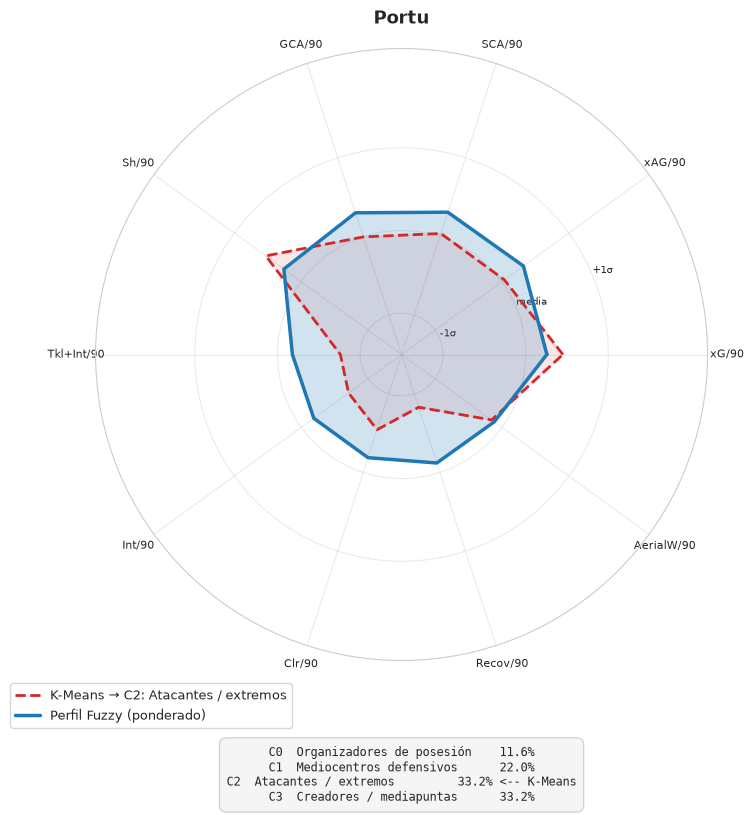

>>> Leandro Barreiro Martins — Centrocampistas (volumen)


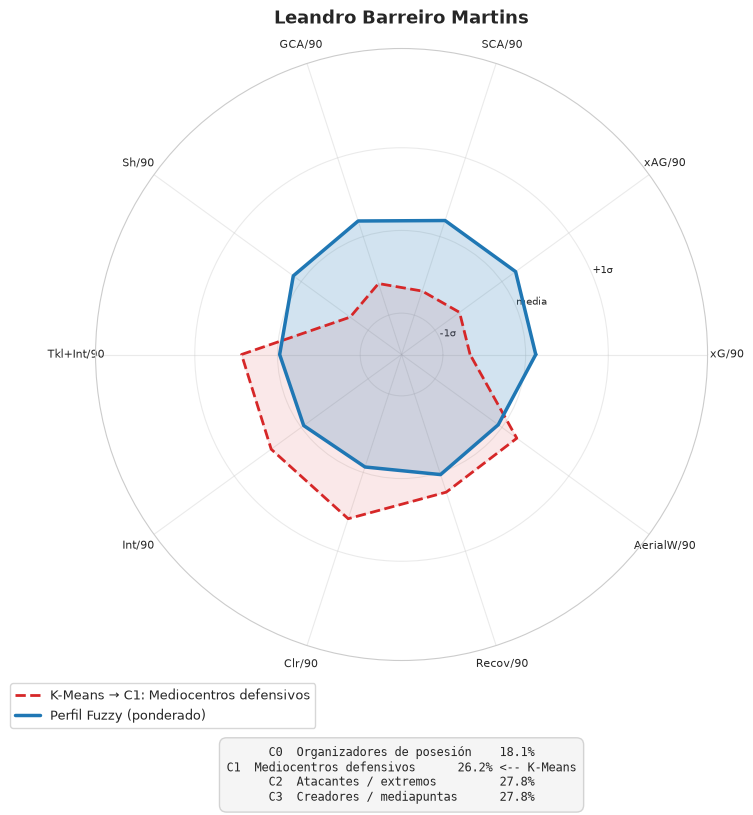

>>> Taylor Booth — Centrocampistas (volumen)


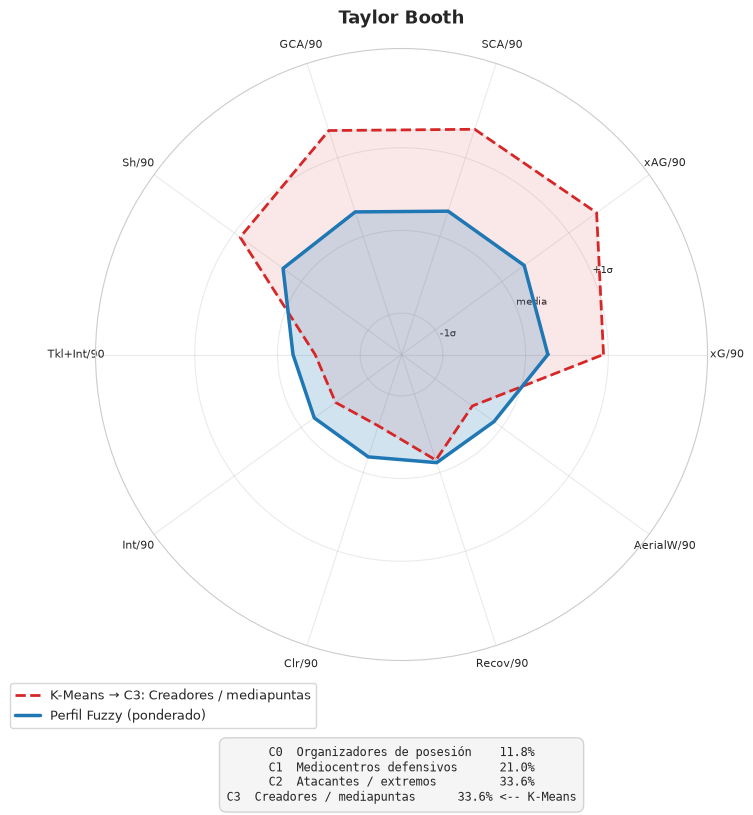

>>> David Pereira da Costa — Centrocampistas (volumen)


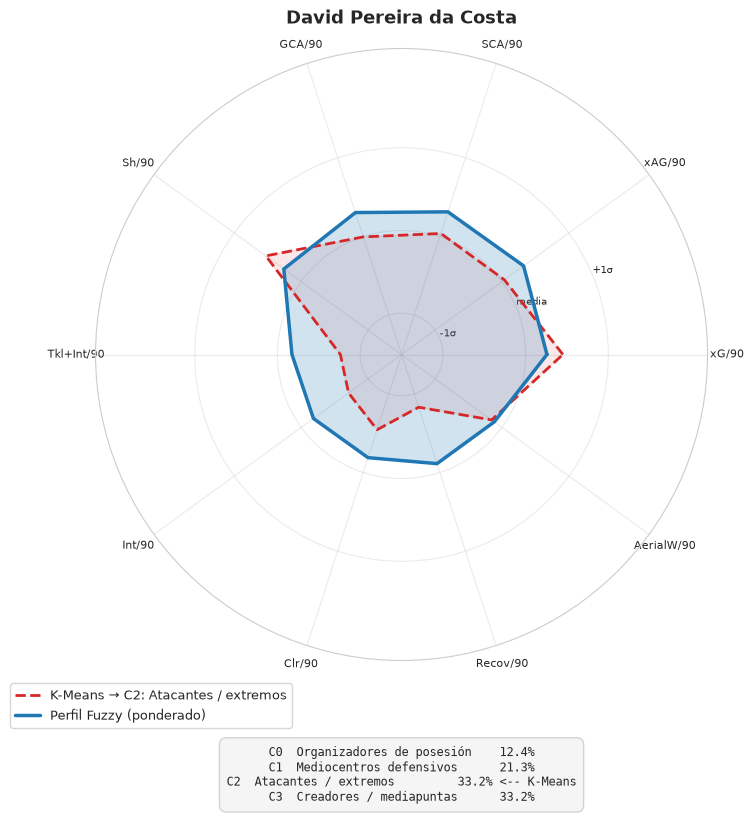

>>> Kike Pérez — Centrocampistas (ratios)


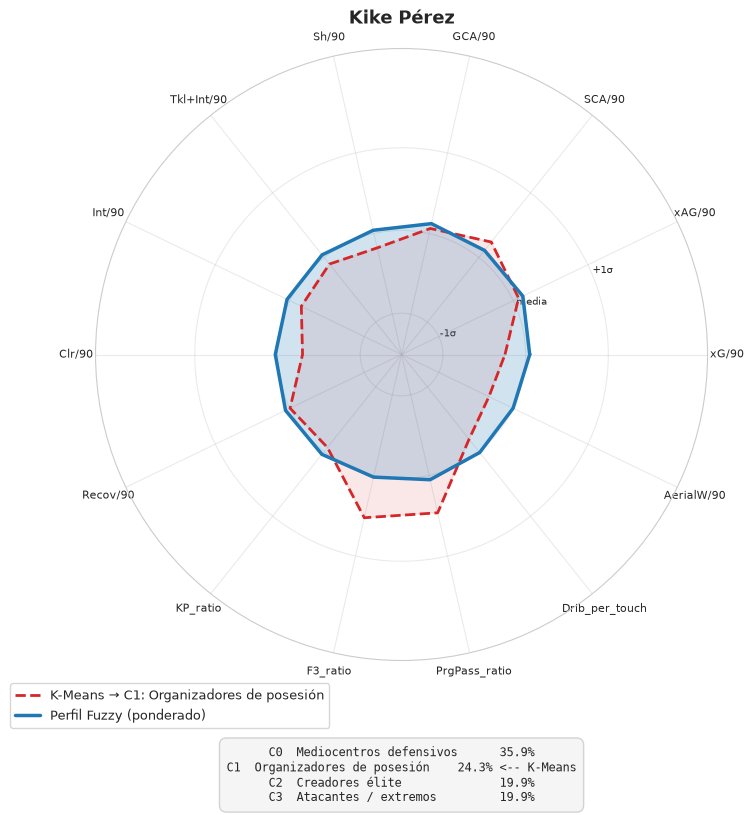

>>> Santi Comesaña — Centrocampistas (ratios)


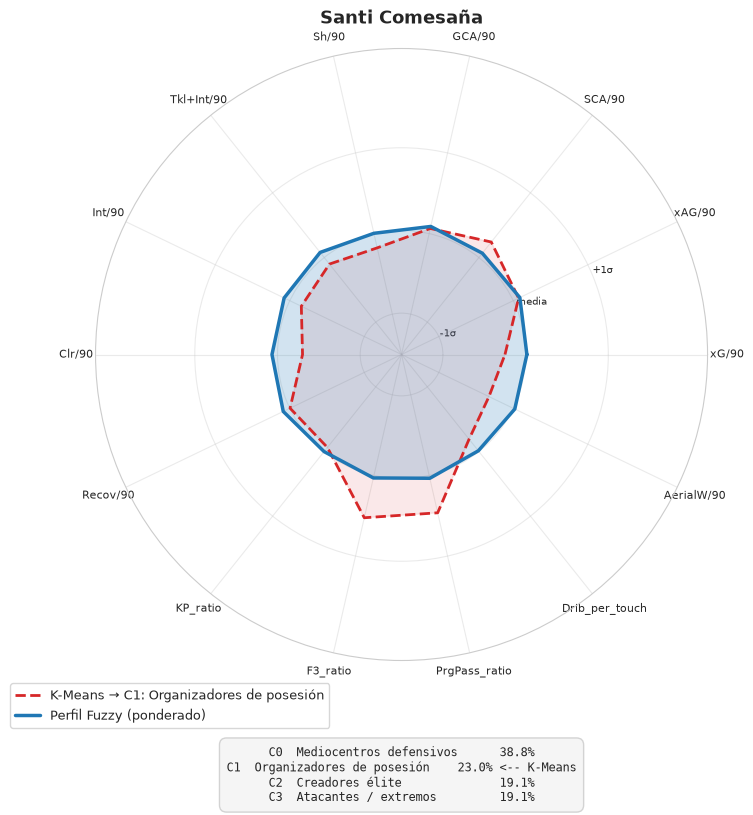

In [29]:
# Radar Fuzzy vs K-Means para los casos con mayor ambigüedad
# (limitamos a los 6 más ambiguos para no saturar)
print("Radares Fuzzy vs K-Means para los casos más ambiguos:\n")

# Ordenar por ambigüedad y coger los 6 primeros únicos
vistos = set()
top_casos = []
for jug, nombre, tipo in sorted(casos_encontrados,
                                 key=lambda x: clusterings[x[1]][x[2]]['df'].set_index('Player').loc[x[0], 'gmm_ambig']
                                 if x[0] in clusterings[x[1]][x[2]]['df']['Player'].values else 0,
                                 reverse=True):
    key = (jug, nombre)
    if key not in vistos:
        top_casos.append((jug, nombre, tipo))
        vistos.add(key)
    if len(top_casos) >= 6:
        break

for jugador, nombre, tipo in top_casos:
    print(f">>> {jugador} — {nombre} ({tipo})")
    radar_fuzzy_vs_kmeans(jugador, nombre, tipo)

### 2.7 Radar plots por rol (interpretación táctica)

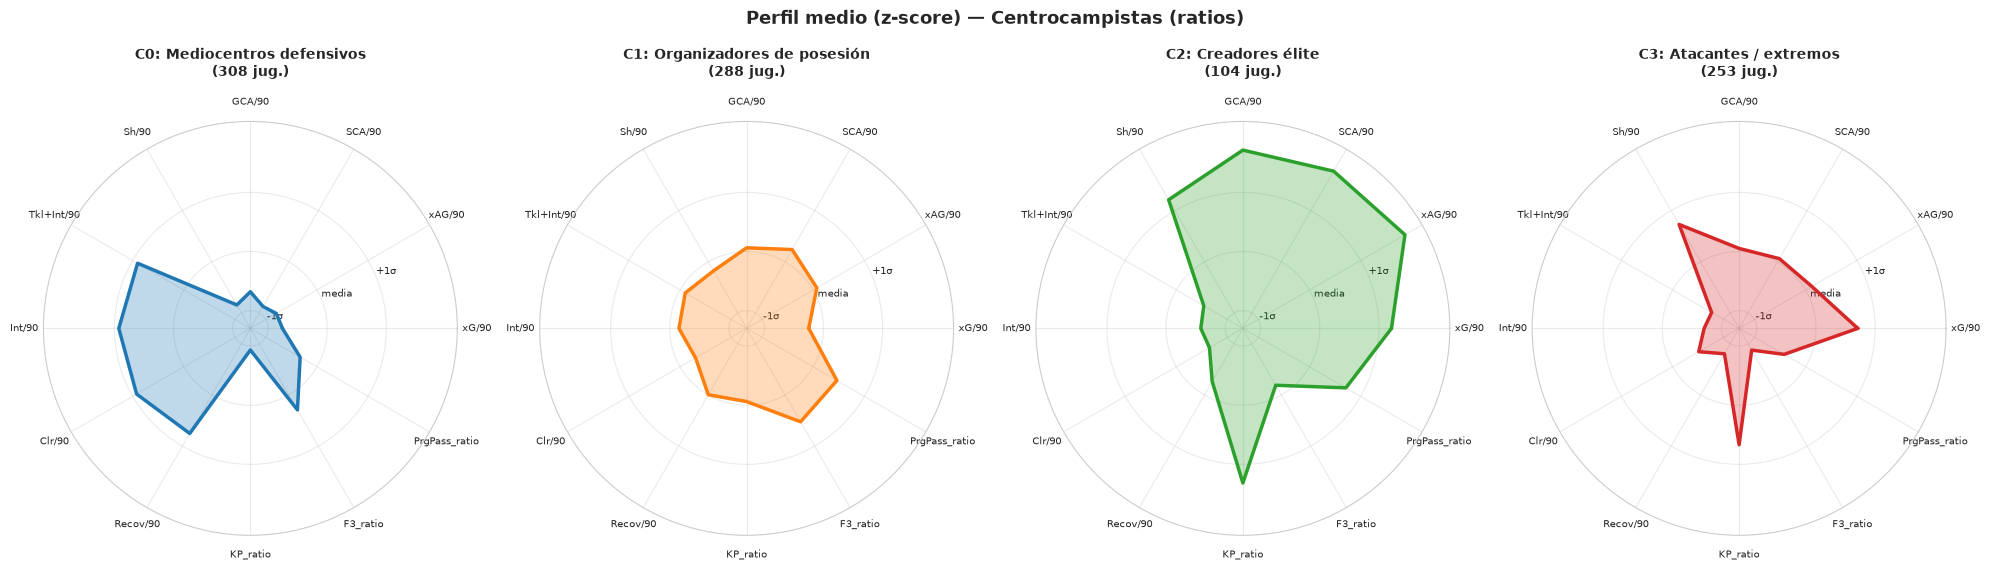

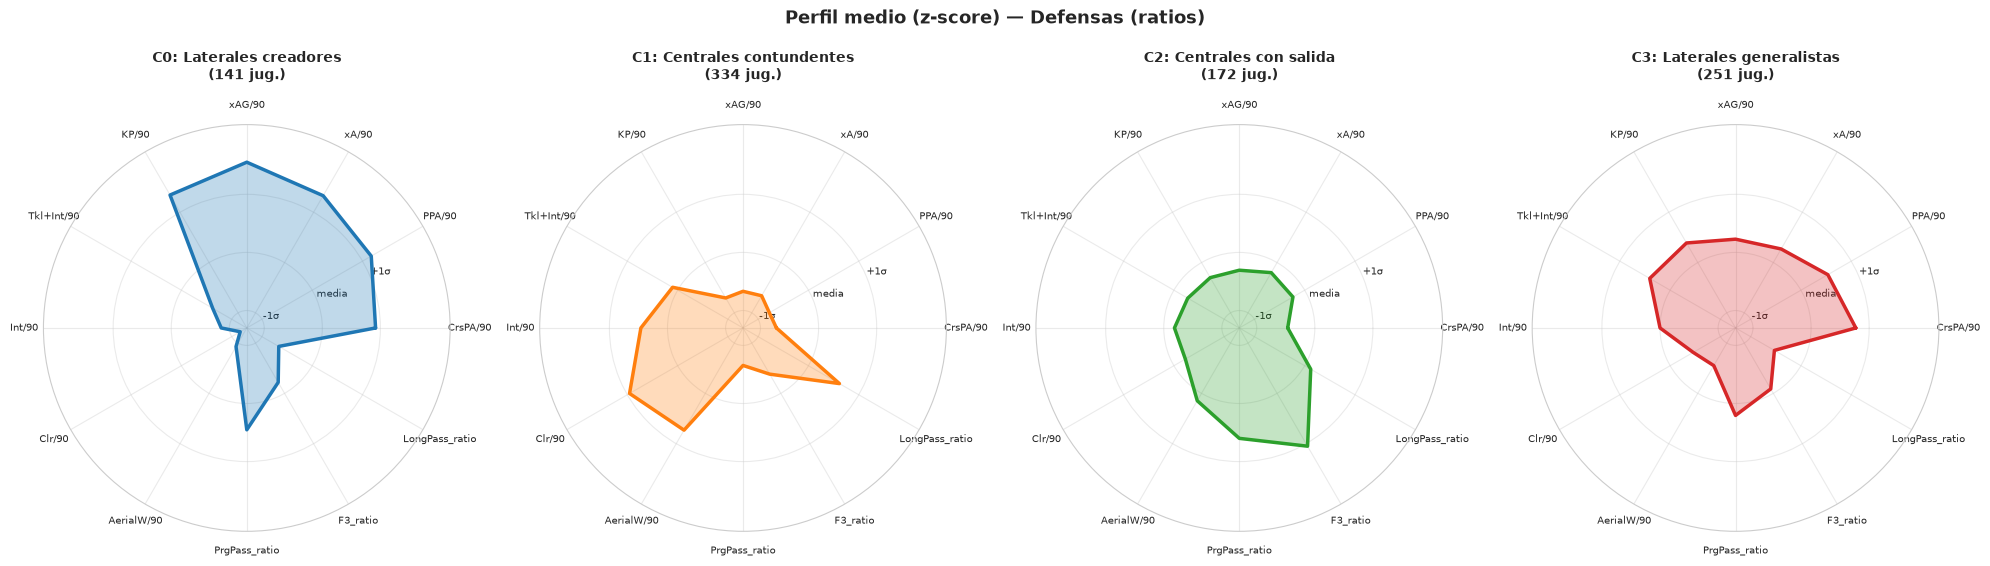

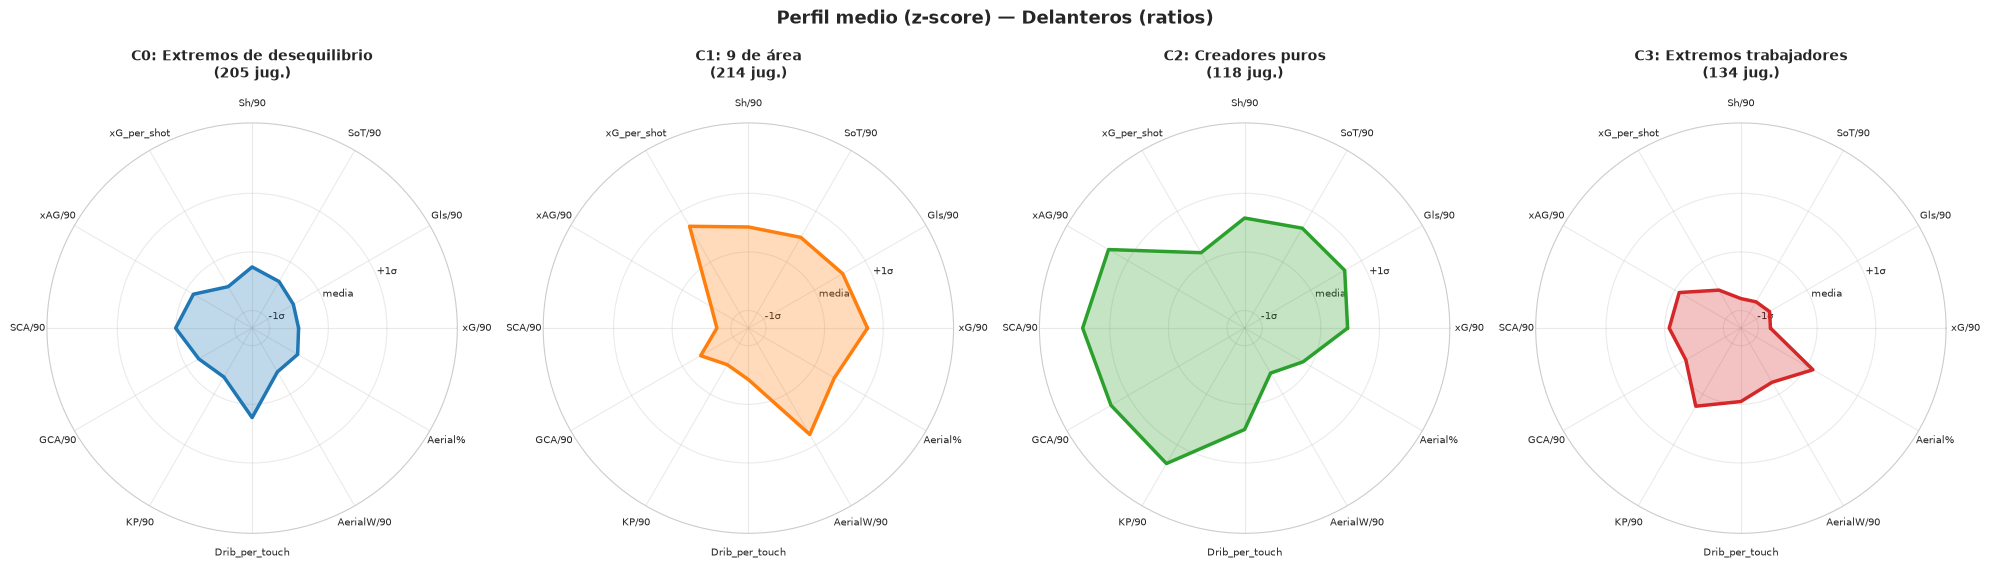

In [30]:
def radar_por_linea(nombre_linea, tipo, features_radar):
    data = clusterings[nombre_linea][tipo]
    df_l, Xs, k, feats = data['df'], data['Xs'], data['k'], data['features']
    labels = df_l['km'].values
    etiquetas = ETIQUETAS_ROLES[nombre_linea][tipo]

    # Filtrar solo las features que existan en esta configuración
    feats_disp = [f for f in features_radar if f in feats]
    idx = [feats.index(f) for f in feats_disp]
    medias = np.array([Xs[labels==c][:, idx].mean(axis=0) for c in range(k)])

    angles = np.linspace(0, 2*np.pi, len(feats_disp), endpoint=False).tolist()
    angles += angles[:1]

    fig, axes = plt.subplots(1, k, figsize=(5*k, 5.5),
                              subplot_kw=dict(projection='polar'))
    if k == 1: axes = [axes]
    for c in range(k):
        ax = axes[c]
        vals = medias[c].tolist() + [medias[c][0]]
        ax.plot(angles, vals, color=COLORS[c], linewidth=2.5)
        ax.fill(angles, vals, color=COLORS[c], alpha=0.28)
        ax.set_xticks(angles[:-1])
        ax.set_xticklabels(feats_disp, fontsize=7.5)
        ax.set_ylim(-1.3, 2.2)
        ax.set_yticks([-1, 0, 1])
        ax.set_yticklabels(['-1σ', 'media', '+1σ'], fontsize=7)
        ax.set_title(f'C{c}: {etiquetas.get(c, "?")}\n({(labels==c).sum()} jug.)',
                     fontsize=10, fontweight='bold', pad=15)
        ax.grid(alpha=0.4)
    plt.suptitle(f'Perfil medio (z-score) — {nombre_linea} ({tipo})',
                 fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

feats_radar_mf = ['xG/90', 'xAG/90', 'SCA/90', 'GCA/90', 'Sh/90',
                  'Tkl+Int/90', 'Int/90', 'Clr/90', 'Recov/90',
                  'KP_ratio', 'F3_ratio', 'PrgPass_ratio']
feats_radar_df = ['CrsPA/90', 'PPA/90', 'xA/90', 'xAG/90', 'KP/90',
                  'Tkl+Int/90', 'Int/90', 'Clr/90', 'AerialW/90',
                  'PrgPass_ratio', 'F3_ratio', 'LongPass_ratio']
feats_radar_fw = ['xG/90', 'Gls/90', 'SoT/90', 'Sh/90', 'xG_per_shot',
                  'xAG/90', 'SCA/90', 'GCA/90', 'KP/90',
                  'Drib_per_touch', 'AerialW/90', 'Aerial%']

# Se muestra la configuracion 'ratios' (la usada en el analisis principal);
# basta sustituir 'ratios' por 'volumen' en las llamadas para ver la otra
radar_por_linea('Centrocampistas', 'ratios', feats_radar_mf)
radar_por_linea('Defensas',        'ratios', feats_radar_df)
radar_por_linea('Delanteros',      'ratios', feats_radar_fw)

---
## 3. Fase 2 · Sistema de rating

### 3.1 Cuatro enfoques

Para cada (línea, tipo) calculamos cuatro ratings:

1. **SHAP ingenuo** — top-12 features por `|SHAP|`
2. **SHAP direccional** (*aportación original*) — solo features con `mean_signed_shap > 0`
3. **Experto** — pesos según literatura de scouting
4. **Híbrido** — 50% SHAP direccional + 50% Experto

Más adelante (sección 3.6) se añade un quinto enfoque, el **SHAP jerárquico**, que combina la importancia general de la línea con la específica del rol.

**Justificación del filtrado direccional**: SHAP mide qué **distingue** el cluster pero no distingue si lo hace por **presencia** (la feature caracteriza al rol) o por **ausencia** (la feature está notoriamente baja). Para un rating de scouting solo la primera señal es útil. Premiar a un "9 de área" por tener pocos SCA es absurdo.

Los percentiles se calculan **dentro de cada rol** para evaluar a cada jugador contra sus pares tácticos.

In [31]:
def calcular_shap_direccional(X_scaled_df, labels, k, random_state=42):
    """SHAP real con TreeExplainer + signo de la correlación feature-vs-SHAP."""
    rf = RandomForestClassifier(n_estimators=500, random_state=random_state,
                                 class_weight='balanced', n_jobs=-1)
    rf.fit(X_scaled_df, labels)
    explainer = shap.TreeExplainer(rf)
    shap_values = explainer.shap_values(X_scaled_df)

    features = X_scaled_df.columns.tolist()
    pesos, signos = {}, {}
    for c in range(k):
        vals = shap_values[c] if isinstance(shap_values, list) else shap_values[:, :, c]
        imp = np.abs(vals).mean(axis=0)

        direcciones = np.zeros(len(features))
        for j in range(len(features)):
            x_j = X_scaled_df.iloc[:, j].values
            s_j = vals[:, j]
            if np.std(x_j) > 0 and np.std(s_j) > 0:
                r = np.corrcoef(x_j, s_j)[0, 1]
                direcciones[j] = np.sign(r) if abs(r) > 0.01 else 0

        pesos[c] = dict(zip(features, imp))
        signos[c] = dict(zip(features, direcciones))
    return pesos, signos, rf, shap_values


def percentiles_por_rol(df_linea, features, rol_col='km'):
    df_out = df_linea.copy()
    for c in df_out[rol_col].unique():
        mask = df_out[rol_col] == c
        for f in features:
            vals = df_out.loc[mask, f].values
            if len(vals) > 0:
                df_out.loc[mask, f + '_pct'] = (
                    rankdata(vals, method='average') / len(vals) * 100)
    return df_out

### 3.2 Pesos expertos por (línea, tipo, rol)

**EDITA según las etiquetas que asignaste antes**. Es importante que las claves numéricas (0/1/2/3) coincidan con los clusters reales.

Cada (línea, tipo, rol) tiene su propio diccionario de pesos.

In [32]:
# PESOS_EXPERTO indexado por ETIQUETA DE ROL (no por numero de cluster).
# Esto es robusto: si KMeans reordena los clusters, los pesos siguen aplicandose
# al rol correcto porque se resuelven via ETIQUETAS_ROLES en la funcion de rating.
PESOS_EXPERTO = {
    'Centrocampistas': {
        'volumen': {
            'Atacantes / extremos': {'xG/90': 0.18, 'Gls/90': 0.15, 'SoT/90': 0.12, 'Sh/90': 0.08,
                'SCA/90': 0.10, 'GCA/90': 0.08, 'xAG/90': 0.10,
                'Dribbles/90': 0.08, 'Dribbles%': 0.05, 'Fld/90': 0.06},
            'Organizadores de posesión': {'PassesCompleted/90': 0.12, 'TotDistPasses/90': 0.10,
                'PrgDistPasses/90': 0.10, 'Passes%': 0.10, 'PassesProgressive/90': 0.10,
                'MediumPasses%': 0.08, 'LongPasses%': 0.08,
                'Recov/90': 0.10, 'Tkl+Int/90': 0.10, 'Int/90': 0.06, 'AerialW/90': 0.06},
            'Mediocentros defensivos': {'Tkl+Int/90': 0.22, 'Int/90': 0.15, 'Recov/90': 0.15,
                'TklW/90': 0.10, 'Blocks/90': 0.08, 'Clr/90': 0.08,
                'AerialW/90': 0.08, 'Aerial%': 0.07, 'Passes%': 0.07},
            'Creadores / mediapuntas': {'xAG/90': 0.18, 'xA/90': 0.15, 'KP/90': 0.14, 'SCA/90': 0.12,
                'GCA/90': 0.10, 'PPA/90': 0.08, 'Ast/90': 0.08,
                'PassesProgressive/90': 0.08, 'FinalThirdPasses/90': 0.07}
        },
        'ratios': {
            'Creadores élite': {'xAG/90': 0.20, 'xA/90': 0.15, 'KP/90': 0.15, 'SCA/90': 0.12,
                'GCA/90': 0.10, 'PPA/90': 0.08, 'Ast/90': 0.08,
                'KP_ratio': 0.06, 'F3_ratio': 0.06},
            'Organizadores de posesión': {'Passes%': 0.12, 'PrgPass_ratio': 0.15, 'PrgPass_per_touch': 0.12,
                'F3_ratio': 0.12, 'MediumPasses%': 0.10, 'LongPasses%': 0.08,
                'Recov/90': 0.10, 'Tkl+Int/90': 0.10, 'Int/90': 0.06, 'AerialW/90': 0.05},
            'Mediocentros defensivos': {'Tkl+Int/90': 0.22, 'Int/90': 0.15, 'Recov/90': 0.15,
                'TklW/90': 0.10, 'Blocks/90': 0.08, 'Clr/90': 0.08,
                'AerialW/90': 0.08, 'Aerial%': 0.07, 'Passes%': 0.07},
            'Atacantes / extremos': {'xG/90': 0.18, 'Gls/90': 0.15, 'SoT/90': 0.12, 'Sh/90': 0.08,
                'SCA/90': 0.10, 'GCA/90': 0.08, 'xAG/90': 0.10,
                'Drib_per_touch': 0.10, 'Dribbles%': 0.05, 'Fld/90': 0.04}
        }
    },
    'Defensas': {
        'volumen': {
            'Laterales creadores': {'CrsPA/90': 0.15, 'PPA/90': 0.12, 'xA/90': 0.12, 'xAG/90': 0.10,
                'SCA/90': 0.10, 'KP/90': 0.08, 'Ast/90': 0.06,
                'Tkl+Int/90': 0.10, 'Recov/90': 0.08, 'AerialW/90': 0.09},
            'Laterales generalistas': {'Tkl+Int/90': 0.15, 'Int/90': 0.10, 'Recov/90': 0.10,
                'CrsPA/90': 0.10, 'PPA/90': 0.08, 'xA/90': 0.08,
                'AerialW/90': 0.10, 'Aerial%': 0.08, 'Passes%': 0.10,
                'PassesProgressive/90': 0.11},
            'Centrales con salida': {'Passes%': 0.15, 'LongPasses%': 0.10, 'PassesProgressive/90': 0.12,
                'PrgDistPasses/90': 0.10, 'TotDistPasses/90': 0.08,
                'Tkl+Int/90': 0.12, 'Int/90': 0.10, 'Clr/90': 0.08,
                'AerialW/90': 0.08, 'Aerial%': 0.07},
            'Centrales contundentes': {'Clr/90': 0.18, 'Tkl+Int/90': 0.16, 'Int/90': 0.12,
                'AerialW/90': 0.15, 'Aerial%': 0.12, 'Blocks/90': 0.10,
                'TklW/90': 0.08, 'Recov/90': 0.05, 'Passes%': 0.04}
        },
        'ratios': {
            'Centrales contundentes': {'Clr/90': 0.18, 'Tkl+Int/90': 0.16, 'Int/90': 0.12,
                'AerialW/90': 0.15, 'Aerial%': 0.12, 'Blocks/90': 0.10,
                'TklW/90': 0.08, 'Recov/90': 0.05, 'Passes%': 0.04},
            'Laterales creadores': {'CrsPA/90': 0.15, 'PPA/90': 0.12, 'xA/90': 0.12, 'xAG/90': 0.10,
                'SCA/90': 0.10, 'KP/90': 0.08, 'Ast/90': 0.06,
                'Tkl+Int/90': 0.10, 'Recov/90': 0.08, 'AerialW/90': 0.09},
            'Centrales con salida': {'Passes%': 0.15, 'LongPasses%': 0.10, 'PrgPass_ratio': 0.12,
                'F3_ratio': 0.10, 'PrgPass_per_touch': 0.08,
                'Tkl+Int/90': 0.12, 'Int/90': 0.10, 'Clr/90': 0.08,
                'AerialW/90': 0.08, 'Aerial%': 0.07},
            'Laterales generalistas': {'Tkl+Int/90': 0.15, 'Int/90': 0.10, 'Recov/90': 0.10,
                'CrsPA/90': 0.10, 'PPA/90': 0.08, 'xA/90': 0.08,
                'AerialW/90': 0.10, 'Aerial%': 0.08, 'Passes%': 0.10,
                'PrgPass_ratio': 0.11}
        }
    },
    'Delanteros': {
        'volumen': {
            'Creadores de posesión': {'KP/90': 0.12, 'xAG/90': 0.12, 'xA/90': 0.10, 'SCA/90': 0.10,
                'PassesCompleted/90': 0.10, 'TotDistPasses/90': 0.08,
                'PassesProgressive/90': 0.10, 'Passes%': 0.08,
                'Ast/90': 0.06, 'PPA/90': 0.08, 'Recov/90': 0.06},
            '9 de área': {'Gls/90': 0.20, 'xG/90': 0.18, 'G-PK/90': 0.12, 'SoT/90': 0.10,
                'Sh/90': 0.06, 'PPA/90': 0.06, 'AerialW/90': 0.10,
                'Aerial%': 0.08, 'xG_per_shot': 0.10},
            'Extremos de élite': {'xG/90': 0.15, 'Gls/90': 0.12, 'xAG/90': 0.12, 'xA/90': 0.10,
                'SCA/90': 0.12, 'GCA/90': 0.10, 'KP/90': 0.08, 'PPA/90': 0.08,
                'Dribbles/90': 0.08, 'Ast/90': 0.05},
            'Extremos trabajadores': {'SCA/90': 0.12, 'KP/90': 0.10, 'PPA/90': 0.10, 'CrsPA/90': 0.08,
                'xAG/90': 0.10, 'xA/90': 0.08, 'Dribbles/90': 0.08,
                'Tkl+Int/90': 0.10, 'Recov/90': 0.10, 'Fld/90': 0.08,
                'xG/90': 0.06}
        },
        'ratios': {
            '9 de área': {'Gls/90': 0.20, 'xG/90': 0.18, 'G-PK/90': 0.12, 'SoT/90': 0.10,
                'Sh/90': 0.06, 'PPA/90': 0.06, 'AerialW/90': 0.10,
                'Aerial%': 0.08, 'xG_per_shot': 0.10},
            'Extremos trabajadores': {'SCA/90': 0.12, 'KP/90': 0.10, 'CrsPA/90': 0.08, 'xAG/90': 0.10,
                'xA/90': 0.08, 'PPA/90': 0.08, 'Ast/90': 0.06,
                'Tkl+Int/90': 0.12, 'Int/90': 0.10, 'Recov/90': 0.10,
                'Fld/90': 0.06},
            'Extremos de desequilibrio': {'Drib_per_touch': 0.15, 'Dribbles%': 0.10, 'SCA_per_touch': 0.12,
                'SCA/90': 0.10, 'CrsPA/90': 0.08, 'KP/90': 0.08,
                'xAG/90': 0.08, 'xA/90': 0.07, 'Fld/90': 0.08,
                'PrgPass_per_touch': 0.07, 'Ast/90': 0.07},
            'Creadores puros': {'xG/90': 0.15, 'Gls/90': 0.12, 'xAG/90': 0.12, 'xA/90': 0.10,
                'SCA/90': 0.12, 'GCA/90': 0.10, 'KP/90': 0.08, 'PPA/90': 0.08,
                'G-PK/90': 0.08, 'Ast/90': 0.05}
        }
    }
}
print('Pesos expertos definidos, indexados por etiqueta de rol (robusto a reordenamientos).')

Pesos expertos definidos, indexados por etiqueta de rol (robusto a reordenamientos).


### 3.3 Calcular los 4 ratings para cada (línea, tipo)

In [33]:
def calcular_ratings(nombre, tipo, top_n_shap=12):
    data = clusterings[nombre][tipo]
    df_l = data['df'].copy()
    Xs, k, feats = data['Xs'], data['k'], data['features']
    Xs_df = pd.DataFrame(Xs, columns=feats)
    labels = df_l['km'].values

    df_l = percentiles_por_rol(df_l, feats, rol_col='km')
    pesos_sh, signos_sh, rf, shap_v = calcular_shap_direccional(Xs_df, labels, k)

    pesos_exp_dict = PESOS_EXPERTO.get(nombre, {}).get(tipo, {})

    for col in ['R_SHAP_ingenuo', 'R_SHAP_direcc', 'R_Experto', 'R_Hibrido']:
        df_l[col] = 0.0

    for c in range(k):
        mask = df_l['km'] == c
        sub = df_l[mask]

        # 1. SHAP INGENUO
        top_ing = sorted(pesos_sh[c].items(), key=lambda x: -x[1])[:top_n_shap]
        total = sum(v for _, v in top_ing)
        r_ing = np.zeros(len(sub))
        for f, w in top_ing:
            r_ing += (w/total) * sub[f + '_pct'].values

        # 2. SHAP DIRECCIONAL
        # Features con signo SHAP positivo (definen el rol por presencia)
        feats_pos = {f: w for f, w in pesos_sh[c].items()
                     if signos_sh[c].get(f, 0) > 0}
        top_dir = dict(sorted(feats_pos.items(), key=lambda x: -x[1])[:top_n_shap])
        total_d = sum(top_dir.values())
        if total_d > 0:
            r_dir = np.zeros(len(sub))
            for f, w in top_dir.items():
                r_dir += (w/total_d) * sub[f + '_pct'].values
        else:
            r_dir = np.zeros(len(sub))

        # 3. EXPERTO — restringido a las MISMAS features que SHAP DIRECCIONAL
        # (opcion B): los pesos manuales solo se aplican sobre features con
        # signo SHAP positivo, garantizando comparabilidad con el SHAP direccional.
        # Si una feature del experto no esta en el conjunto direccional, se descarta.
        feats_dir = set(top_dir.keys())
        # Traducir numero de cluster -> etiqueta de rol -> pesos expertos
        # (robusto frente a reordenamientos de KMeans)
        etiqueta_c = ETIQUETAS_ROLES.get(nombre, {}).get(tipo, {}).get(c)
        pe_raw = pesos_exp_dict.get(etiqueta_c, {})
        pe = {f: w for f, w in pe_raw.items()
              if f in feats and f in feats_dir}
        if pe:
            te = sum(pe.values())
            r_exp = np.zeros(len(sub))
            for f, w in pe.items():
                r_exp += (w/te) * sub[f + '_pct'].values
        else:
            # Fallback: si ninguna feature experta coincide con SHAP+,
            # usamos los pesos expertos originales sobre las features que existan
            pe = {f: w for f, w in pe_raw.items() if f in feats}
            if pe:
                te = sum(pe.values())
                r_exp = np.zeros(len(sub))
                for f, w in pe.items():
                    r_exp += (w/te) * sub[f + '_pct'].values
                print(f'  [aviso] {nombre}/{tipo} C{c}: ninguna feature '
                      f'experta en SHAP+, se usa fallback con todas')
            else:
                r_exp = np.zeros(len(sub))

        # 4. HIBRIDO
        r_hib = 0.5 * r_dir + 0.5 * r_exp

        df_l.loc[mask, 'R_SHAP_ingenuo'] = r_ing
        df_l.loc[mask, 'R_SHAP_direcc']  = r_dir
        df_l.loc[mask, 'R_Experto']      = r_exp
        df_l.loc[mask, 'R_Hibrido']      = r_hib

    return df_l, pesos_sh, signos_sh

# Ejecutar para todas las combinaciones (linea x tipo)
ratings = {nombre: {} for _, nombre, _ in lineas_config}
for nombre in ['Centrocampistas', 'Defensas', 'Delanteros']:
    for tipo in ['volumen', 'ratios']:
        print(f'Calculando ratings para {nombre}/{tipo}...')
        df_r_calc, p_sh, s_sh = calcular_ratings(nombre, tipo)
        ratings[nombre][tipo] = {
            'df': df_r_calc,
            'pesos_shap': p_sh,
            'signos_shap': s_sh,
            'features': clusterings[nombre][tipo]['features']
        }
print('\n\u2713 Ratings calculados para 6 combinaciones (3 lineas \u00d7 2 tipos)')
print('  Nota: R_Experto se calcula solo sobre features con SHAP direccional > 0,')
print('  garantizando comparabilidad estricta con R_SHAP_direcc.')

Calculando ratings para Centrocampistas/volumen...


Calculando ratings para Centrocampistas/ratios...


Calculando ratings para Defensas/volumen...


Calculando ratings para Defensas/ratios...


Calculando ratings para Delanteros/volumen...


Calculando ratings para Delanteros/ratios...



✓ Ratings calculados para 6 combinaciones (3 lineas × 2 tipos)
  Nota: R_Experto se calcula solo sobre features con SHAP direccional > 0,
  garantizando comparabilidad estricta con R_SHAP_direcc.


### 3.4 Impacto del filtrado direccional

Esta es la validación de la aportación metodológica central del trabajo. Comparamos, para cada uno de los 24 clusters (3 líneas × 2 configuraciones × 4 roles), la correlación de Spearman entre el criterio experto y dos versiones del rating SHAP: el **ingenuo** (que usa `|SHAP|`, mezclando presencia y ausencia de acciones) y el **direccional** (que conserva solo las contribuciones de signo positivo, es decir, las acciones que el jugador *realiza*).

La tabla siguiente muestra ambas correlaciones y su diferencia. La señal a buscar es que el filtrado direccional eleve el acuerdo con el criterio experto, especialmente en los roles donde el SHAP ingenuo se comporta peor: aquellos que un modelo de clasificación caracteriza en parte *por la ausencia* de ciertas acciones (un mediocentro defensivo se distingue, entre otras cosas, por no tirar a puerta), lo cual penaliza injustamente a los buenos especialistas cuando se usa `|SHAP|`.

In [34]:
# Mapeo de etiquetas cortas
LINEA_ABREV = {'Centrocampistas': 'MF', 'Defensas': 'DF', 'Delanteros': 'FW'}

filas = []
for nombre, tipo_data in ratings.items():
    for tipo, data in tipo_data.items():
        df_l = data['df']
        k = clusterings[nombre][tipo]['k']
        for c in range(k):
            sub = df_l[df_l['km'] == c]
            rho_ie = spearmanr(sub['R_SHAP_ingenuo'], sub['R_Experto']).correlation
            rho_de = spearmanr(sub['R_SHAP_direcc'],  sub['R_Experto']).correlation
            etiq = ETIQUETAS_ROLES[nombre][tipo].get(c, f'C{c}')
            filas.append({
                'Línea': LINEA_ABREV[nombre], 'Tipo': tipo, 'Cluster': f'C{c}',
                'Rol': etiq[:20],
                'rho_Ingenuo_Exp': rho_ie,
                'rho_Direcc_Exp':  rho_de,
                'Mejora': rho_de - rho_ie
            })
df_comp = pd.DataFrame(filas)
print(df_comp.round(3).to_string(index=False))

Línea    Tipo Cluster                  Rol  rho_Ingenuo_Exp  rho_Direcc_Exp  Mejora
   MF volumen      C0 Organizadores de pos            0.920           0.920   0.000
   MF volumen      C1 Mediocentros defensi            0.261           0.746   0.485
   MF volumen      C2 Atacantes / extremos           -0.128           0.971   1.099
   MF volumen      C3 Creadores / mediapun            0.938           0.954   0.017
   MF  ratios      C0 Mediocentros defensi            0.237           0.969   0.732
   MF  ratios      C1 Organizadores de pos            0.551           0.815   0.264
   MF  ratios      C2      Creadores élite            0.923           0.923   0.000
   MF  ratios      C3 Atacantes / extremos            0.455           0.870   0.415
   DF volumen      C0 Centrales contundent            0.246           0.914   0.668
   DF volumen      C1 Laterales generalist            0.558           0.764   0.207
   DF volumen      C2  Laterales creadores            0.784           0.821 

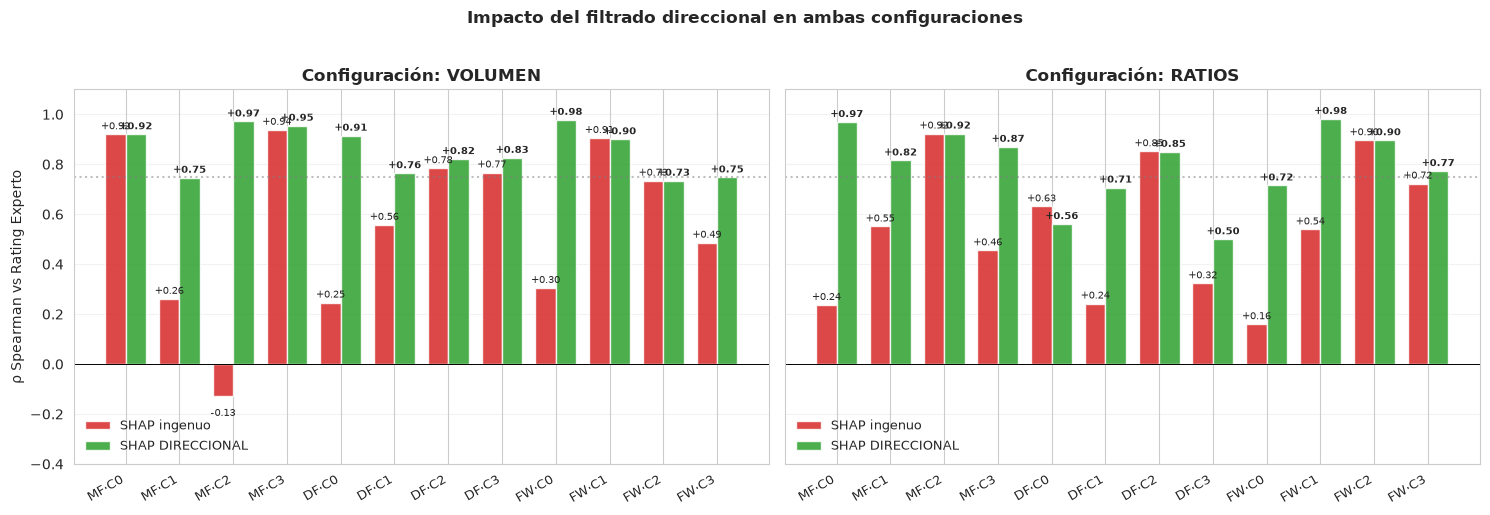

In [35]:
# Gráfico: comparación volumen vs ratios del impacto direccional
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

for ax, tipo in zip(axes, ['volumen', 'ratios']):
    sub = df_comp[df_comp['Tipo'] == tipo].reset_index(drop=True)
    etiq = [f"{r['Línea']}·{r['Cluster']}" for _, r in sub.iterrows()]
    x = np.arange(len(etiq))
    w = 0.38

    bars1 = ax.bar(x - w/2, sub['rho_Ingenuo_Exp'], w,
                    label='SHAP ingenuo', color='#d62728', alpha=0.85, edgecolor='white')
    bars2 = ax.bar(x + w/2, sub['rho_Direcc_Exp'], w,
                    label='SHAP DIRECCIONAL', color='#2ca02c', alpha=0.85, edgecolor='white')

    ax.axhline(0, color='black', linewidth=0.7)
    ax.axhline(0.75, color='gray', linestyle=':', alpha=0.5)
    ax.set_xticks(x)
    ax.set_xticklabels(etiq, rotation=30, ha='right', fontsize=9)
    ax.set_title(f'Configuración: {tipo.upper()}', fontweight='bold')
    ax.set_ylim(-0.4, 1.1)
    ax.legend(frameon=False, loc='lower left', fontsize=9)
    ax.grid(True, alpha=0.25, axis='y')

    for bar, v in zip(bars1, sub['rho_Ingenuo_Exp']):
        ax.text(bar.get_x() + bar.get_width()/2, v + 0.02 if v > 0 else v - 0.08,
                f'{v:+.2f}', ha='center', fontsize=7)
    for bar, v in zip(bars2, sub['rho_Direcc_Exp']):
        ax.text(bar.get_x() + bar.get_width()/2, v + 0.02 if v > 0 else v - 0.08,
                f'{v:+.2f}', ha='center', fontsize=7, fontweight='bold')

axes[0].set_ylabel('ρ Spearman vs Rating Experto')
fig.suptitle('Impacto del filtrado direccional en ambas configuraciones',
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Interpretación de resultados.** El filtrado direccional mejora o mantiene el acuerdo con el criterio experto en 21 de los 24 clusters. De ellos, 17 mejoran de forma efectiva, 4 no cambian (son roles en los que las features definitorias ya eran todas de presencia, de modo que el rating ingenuo y el direccional coinciden) y solo 3 empeoran, en todos los casos de manera marginal (caídas inferiores a 0,07).

Los casos más llamativos son precisamente los roles definidos en parte por ausencia de acciones ofensivas:
- En **mediocentros / atacantes (volumen)**, la correlación con el experto pasa de ligeramente **negativa a casi perfecta**: el SHAP ingenuo llegaba a premiar la ausencia de remate, invirtiendo el orden lógico, mientras que el direccional lo corrige por completo.
- En los **mediocentros defensivos (ratios)**, **centrales contundentes (volumen)** y **nueves de área (volumen)**, la mejora es de gran magnitud: el rating pasa de una correlación débil a un acuerdo casi total con el criterio experto.

Las pocas caídas se concentran en roles ya muy bien capturados por el SHAP ingenuo (correlaciones de partida superiores a 0,85), donde el margen de mejora era nulo y el filtrado introduce una variación despreciable. En conjunto, la evidencia respalda que conservar únicamente el aporte direccional positivo produce un rating más alineado con la valoración táctica experta, sin penalizar a los especialistas defensivos por aquello que su rol no exige.

### 3.5 Caso visual revelador: 9 de área (FW, ratios)

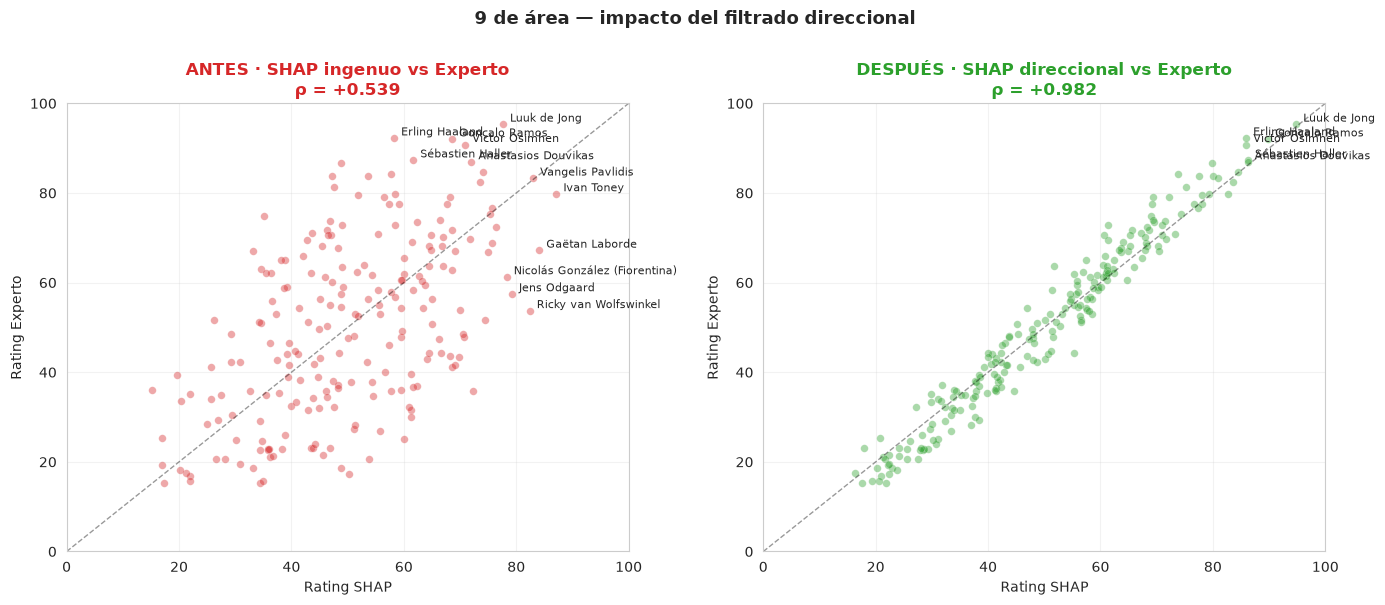

In [36]:
nombre, tipo = 'Delanteros', 'ratios'
# Localizar dinamicamente el cluster '9 de área' por su etiqueta (robusto a reordenamientos)
etiquetas_nt = ETIQUETAS_ROLES[nombre][tipo]
cluster_target = next((c for c, e in etiquetas_nt.items() if e == '9 de área'), 0)
sub = ratings[nombre][tipo]['df']
sub = sub[sub['km'] == cluster_target]
etiq = etiquetas_nt.get(cluster_target, '?')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, col, color, titulo in [
    (axes[0], 'R_SHAP_ingenuo', '#d62728', 'ANTES · SHAP ingenuo vs Experto'),
    (axes[1], 'R_SHAP_direcc',  '#2ca02c', 'DESPUÉS · SHAP direccional vs Experto')
]:
    rho = spearmanr(sub[col], sub['R_Experto']).correlation
    ax.scatter(sub[col], sub['R_Experto'], c=color, alpha=0.4, s=30,
               edgecolors='white', linewidth=0.3)
    ax.plot([0, 100], [0, 100], 'k--', alpha=0.4, linewidth=1)
    top_e = sub.nlargest(6, 'R_Experto')
    top_s = sub.nlargest(6, col)
    for _, r in pd.concat([top_e, top_s]).drop_duplicates('Player').iterrows():
        ax.annotate(r['Player'], (r[col], r['R_Experto']),
                    fontsize=8, xytext=(5, 2), textcoords='offset points')
    ax.set_xlabel('Rating SHAP')
    ax.set_ylabel('Rating Experto')
    ax.set_title(f'{titulo}\nρ = {rho:+.3f}', fontweight='bold', color=color)
    ax.set_xlim(0, 100); ax.set_ylim(0, 100)
    ax.grid(True, alpha=0.25)

plt.suptitle(f'{etiq} — impacto del filtrado direccional',
             fontsize=13, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

### 3.6 SHAP direccional jerárquico (Core + Específico)

El rating SHAP direccional intra-rol responde a la pregunta «¿qué tan prototípico del rol es este jugador?», pero no necesariamente a «¿qué tan bueno es como jugador de su línea?». Un jugador puede destacar mucho dentro de su rol específico y, sin embargo, fallar en lo que define ser **buen miembro de la línea en general**.

Para corregir esto proponemos un **rating SHAP jerárquico** con dos niveles:

- **Nivel 1 (Core de línea)**: SHAP direccional sobre un modelo multi-clase que predice la línea (DF / MF / FW) a partir de las features. Las features con signo positivo son las que definen la pertenencia a esa línea por presencia.
- **Nivel 2 (Específico de rol)**: el rating SHAP direccional intra-cluster que ya tenemos.

El rating final es una combinación lineal:

$$R_{\mathrm{jer}}(i) = \alpha \cdot R_{\mathrm{core}}(i) + (1-\alpha) \cdot R_{\mathrm{esp}}(i)$$

Usamos $\alpha = 0{,}3$ por defecto (30% peso al core, 70% al específico): los datos sugieren que la especialización en el rol es el factor dominante para diferenciar jugadores buenos de jugadores promedio dentro de un mismo rol, pero el componente core penaliza a aquellos jugadores que no cumplen los fundamentales de su línea.

In [37]:
# ----- NIVEL 1: SHAP entre líneas (multietiqueta) -----
def construir_dataset_multietiqueta(df_filtrado, features):
    """
    Cada jugador aparece tantas veces como líneas en su Pos.
    Excluimos GK porque sus features de campo son 0 en su mayoría.
    """
    LINEAS = ['DF', 'MF', 'FW']  # GK excluido
    Xs_list, y_list = [], []
    for _, row in df_filtrado.iterrows():
        pos = str(row['Pos'])
        for linea in LINEAS:
            if linea in pos.split(','):
                Xs_list.append(row[features].values)
                y_list.append(linea)
    return np.array(Xs_list, dtype=float), np.array(y_list)


def calcular_shap_direccional_lineas(df_filtrado, features, random_state=42):
    """SHAP direccional entre líneas. Devuelve {linea: pesos, signos}."""
    X, y = construir_dataset_multietiqueta(df_filtrado, features)
    Xs = StandardScaler().fit_transform(np.nan_to_num(X, nan=0.0))
    Xs_df = pd.DataFrame(Xs, columns=features)

    rf = RandomForestClassifier(n_estimators=300, random_state=random_state,
                                 class_weight='balanced', n_jobs=-1, max_depth=15)
    rf.fit(Xs_df, y)
    print(f'RF entre líneas entrenado: shape={Xs_df.shape}, '
          f'clases={list(rf.classes_)}, accuracy={rf.score(Xs_df, y):.3f}')

    explainer = shap.TreeExplainer(rf)
    shap_vals = explainer.shap_values(Xs_df)

    pesos_core, signos_core = {}, {}
    for i, linea in enumerate(rf.classes_):
        vals = shap_vals[i] if isinstance(shap_vals, list) else shap_vals[:, :, i]
        imp = np.abs(vals).mean(axis=0)
        direcciones = np.zeros(len(features))
        for j in range(len(features)):
            x_j = Xs_df.iloc[:, j].values
            s_j = vals[:, j]
            if np.std(x_j) > 0 and np.std(s_j) > 0:
                r = np.corrcoef(x_j, s_j)[0, 1]
                direcciones[j] = np.sign(r) if abs(r) > 0.01 else 0
        pesos_core[str(linea)] = dict(zip(features, imp))
        signos_core[str(linea)] = dict(zip(features, direcciones))
    return pesos_core, signos_core


def rating_core_linea(df_linea, features, pesos_core_l, signos_core_l, top_n=15):
    """Rating Core: percentiles intra-LÍNEA con pesos SHAP direccionales."""
    feats_pos = {f: w for f, w in pesos_core_l.items()
                 if signos_core_l.get(f, 0) > 0 and f in features}
    top = dict(sorted(feats_pos.items(), key=lambda x: -x[1])[:top_n])
    total = sum(top.values())
    if total == 0:
        return np.zeros(len(df_linea))
    pesos_norm = {f: w/total for f, w in top.items()}

    rating = np.zeros(len(df_linea))
    for f, w in pesos_norm.items():
        # Percentil DENTRO de la línea (no del rol)
        pct = rankdata(df_linea[f].values, method='average') / len(df_linea) * 100
        rating += w * pct
    return rating


# Calcular SHAP entre líneas para cada configuración (volumen y ratios)
shap_lineas = {}
for tipo, feats in FEATURE_SETS.items():
    print(f'\n[Configuración: {tipo}]')
    pesos_c, signos_c = calcular_shap_direccional_lineas(df_r, feats)
    shap_lineas[tipo] = {'pesos': pesos_c, 'signos': signos_c}
    for linea in pesos_c:
        feats_pos = sorted([(f, w) for f, w in pesos_c[linea].items()
                             if signos_c[linea].get(f, 0) > 0],
                            key=lambda x: -x[1])[:8]
        print(f'  {linea} core (top-8): ' + ', '.join([f for f, _ in feats_pos]))


[Configuración: volumen]


RF entre líneas entrenado: shape=(2522, 42), clases=[np.str_('DF'), np.str_('FW'), np.str_('MF')], accuracy=0.789


  DF core (top-8): Clr/90, PrgDistPasses/90, MediumPassesCompleted/90, TotDistPasses/90, CrsPA/90, PassesAttempted/90, Int/90, Touches/90
  FW core (top-8): Sh/90, SoT/90, xG/90, Gls/90, SCA/90, KP/90, Dribbles/90, G-PK/90
  MF core (top-8): FinalThirdPasses/90, Sh/90, SCA/90, MediumPasses%, PassesProgressive/90, LongPasses%, Int/90, Recov/90

[Configuración: ratios]


RF entre líneas entrenado: shape=(2522, 43), clases=[np.str_('DF'), np.str_('FW'), np.str_('MF')], accuracy=0.789


  DF core (top-8): Clr/90, CrsPA/90, Int/90, Tkl+Int/90, ShortPasses%, PPA/90, Aerial%, FinalThirdPasses/90
  FW core (top-8): SCA_per_touch, Sh/90, KP_ratio, SoT/90, xG/90, Drib_per_touch, Gls/90, G-PK/90
  MF core (top-8): F3_ratio, SCA_per_touch, PrgPass_ratio, PrgPass_per_touch, KP_ratio, Sh/90, FinalThirdPasses/90, Recov/90


Ahora calculamos el rating Core para cada jugador en cada línea, y lo combinamos con el rating específico para obtener el rating jerárquico.

In [38]:
ALPHA = 0.3  # Peso del rating Core (1-α al específico)

# Mapeo línea→pos_code para acceder al SHAP de líneas
POS_CODE = {'Centrocampistas': 'MF', 'Defensas': 'DF', 'Delanteros': 'FW'}

for nombre in ['Centrocampistas', 'Defensas', 'Delanteros']:
    pos_code = POS_CODE[nombre]
    for tipo in ['volumen', 'ratios']:
        df_l = ratings[nombre][tipo]['df']
        feats = ratings[nombre][tipo]['features']

        # Calcular rating Core
        r_core = rating_core_linea(
            df_l, feats,
            shap_lineas[tipo]['pesos'][pos_code],
            shap_lineas[tipo]['signos'][pos_code],
            top_n=15)

        # Combinar con el rating específico (SHAP direccional intra-rol)
        df_l['R_Core']        = r_core
        df_l['R_Jerarquico']  = ALPHA * r_core + (1 - ALPHA) * df_l['R_SHAP_direcc']

print(f'\n✓ Rating Core y Jerárquico calculados (α={ALPHA})')


✓ Rating Core y Jerárquico calculados (α=0.3)


**Visualización**: comparemos el rating Específico, el rating Core y el rating Jerárquico para ver cómo cambian los rankings.

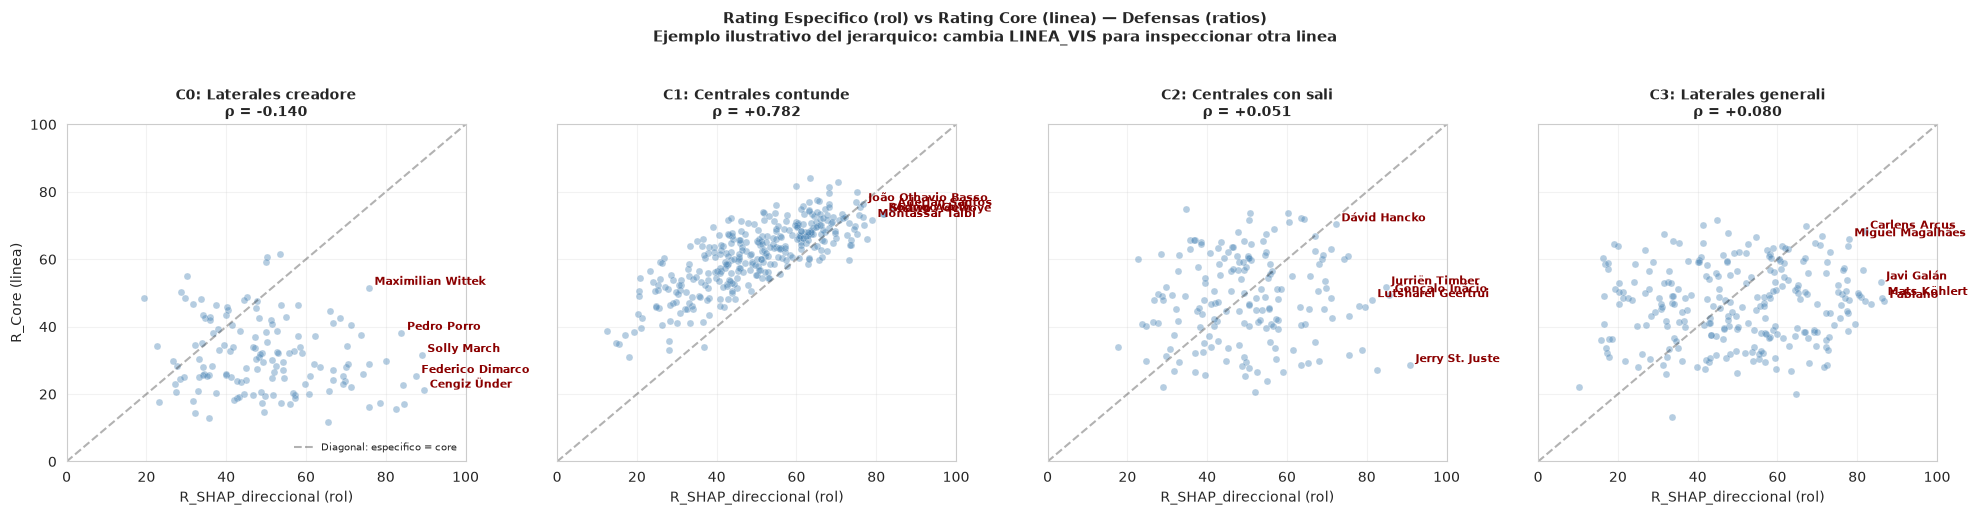

In [39]:
# Visualizacion ilustrativa: como se relacionan los ratings Core y Especifico
# Los parametros LINEA_VIS y TIPO_VIS permiten inspeccionar otra linea o configuracion
LINEA_VIS = 'Defensas'   # 'Centrocampistas', 'Defensas' o 'Delanteros'
TIPO_VIS  = 'ratios'     # 'volumen' o 'ratios'

df_l = ratings[LINEA_VIS][TIPO_VIS]['df']
k = clusterings[LINEA_VIS][TIPO_VIS]['k']

fig, axes = plt.subplots(1, k, figsize=(5*k, 5), sharey=True)
if k == 1: axes = [axes]

for c in range(k):
    ax = axes[c]
    sub = df_l[df_l['km'] == c]
    etiq = ETIQUETAS_ROLES[LINEA_VIS][TIPO_VIS].get(c, f'C{c}')

    ax.scatter(sub['R_SHAP_direcc'], sub['R_Core'], alpha=0.4, s=25,
               c='steelblue', edgecolors='white', linewidth=0.3)
    ax.plot([0, 100], [0, 100], 'k--', alpha=0.3,
            label='Diagonal: especifico = core')

    # Etiquetar top 5 por rating jerarquico
    top_jer = sub.nlargest(5, 'R_Jerarquico')
    for _, r in top_jer.iterrows():
        ax.annotate(r['Player'][:18], (r['R_SHAP_direcc'], r['R_Core']),
                    fontsize=8, xytext=(4, 2), textcoords='offset points',
                    color='darkred', fontweight='bold')

    rho = spearmanr(sub['R_SHAP_direcc'], sub['R_Core']).correlation
    ax.set_xlabel('R_SHAP_direccional (rol)')
    if c == 0:
        ax.set_ylabel('R_Core (linea)')
    ax.set_title(f'C{c}: {etiq[:18]}\n\u03c1 = {rho:+.3f}',
                 fontsize=10, fontweight='bold')
    ax.set_xlim(0, 100); ax.set_ylim(0, 100)
    ax.grid(True, alpha=0.25)
    if c == 0:
        ax.legend(fontsize=7, loc='lower right', frameon=False)

plt.suptitle(f'Rating Especifico (rol) vs Rating Core (linea) \u2014 '
             f'{LINEA_VIS} ({TIPO_VIS})\n'
             f'Ejemplo ilustrativo del jerarquico: cambia LINEA_VIS para inspeccionar otra linea',
             fontsize=11, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Los jugadores en la **diagonal** son consistentes en ambos niveles. Los que están **arriba a la izquierda** son buenos en lo core de la línea pero atípicos en su rol asignado (típicamente jugadores difíciles de clasificar). Los que están **abajo a la derecha** son extremos en su rol pero deficientes en lo core de la línea.

### 3.7 TOP-10 por rol — comparación de los 5 ratings

Mostramos para cada rol los TOP-10 según los **cinco enfoques de rating**, ordenados por defecto por el rating SHAP direccional (`R_Dir`), la aportación metodológica principal. Las columnas son:

- `R_Ing`: SHAP ingenuo (todas las features ponderadas por |SHAP|)
- `R_Dir`: SHAP direccional (solo features con signo +)
- `R_Exp`: Experto (pesos manuales basados en literatura de scouting)
- `R_Hib`: Híbrido (50% SHAP direccional + 50% Experto)
- `R_Jer`: **Jerárquico (30% Core de línea + 70% SHAP direccional intra-rol)**

In [40]:
# Top-10 por rol — el ranking principal usa R_SHAP_direcc (aportacion original)
# El parametro ORDENAR_POR admite cualquiera de los 5 ratings disponibles
TIPO_MOSTRAR = 'ratios'        # 'volumen' o 'ratios'
ORDENAR_POR  = 'R_SHAP_direcc' # opciones: 'R_SHAP_ingenuo', 'R_SHAP_direcc',
                                #          'R_Experto', 'R_Hibrido', 'R_Jerarquico'

for nombre in ['Centrocampistas', 'Defensas', 'Delanteros']:
    df_l = ratings[nombre][TIPO_MOSTRAR]['df']
    k = clusterings[nombre][TIPO_MOSTRAR]['k']
    print(f'\n{"="*88}')
    print(f'  {nombre} \u2014 configuracion {TIPO_MOSTRAR} \u2014 ordenado por {ORDENAR_POR}')
    print(f'{"="*88}')
    for c in range(k):
        etiq = ETIQUETAS_ROLES[nombre][TIPO_MOSTRAR].get(c, f'C{c}')
        print(f'\n--- C{c}: {etiq} ---')
        top = df_l[df_l['km']==c].nlargest(10, ORDENAR_POR)[
            ['Player', 'Squad', 'Age',
             'R_SHAP_ingenuo', 'R_SHAP_direcc', 'R_Experto',
             'R_Hibrido', 'R_Jerarquico']].copy()
        top = top.rename(columns={
            'R_SHAP_ingenuo': 'R_Ing',
            'R_SHAP_direcc':  'R_Dir',
            'R_Experto':      'R_Exp',
            'R_Hibrido':      'R_Hib',
            'R_Jerarquico':   'R_Jer'
        })
        print(top.round(1).to_string(index=False))


  Centrocampistas — configuracion ratios — ordenado por R_SHAP_direcc

--- C0: Mediocentros defensivos ---
         Player          Squad  Age  R_Ing  R_Dir  R_Exp  R_Hib  R_Jer
 Andrei Girotto         Nantes   30   40.7   87.8   84.4   86.1   74.7
 Benjamin André          Lille   31   48.6   85.3   89.6   87.4   80.6
Guido Rodríguez          Betis   28   34.6   83.6   84.2   83.9   71.9
  Ellyes Skhiri           Köln   27   61.1   82.5   88.8   85.6   72.9
       Casemiro Manchester Utd   30   85.2   82.2   85.9   84.1   77.1
Morten Hjulmand          Lecce   23   57.1   81.5   83.0   82.2   77.2
  João Palhinha         Fulham   27   38.9   81.2   85.3   83.2   71.5
Loreintz Rosier        Estoril   24   43.0   80.7   81.3   81.0   70.9
  Lucien Agoume         Troyes   20   66.5   80.1   80.7   80.4   75.2
    Declan Rice       West Ham   23   72.1   80.0   81.0   80.5   77.0

--- C1: Organizadores de posesión ---
            Player           Squad  Age  R_Ing  R_Dir  R_Exp  R_Hib  R_J

**Cómo leer la tabla**: el ranking se ordena por `R_SHAP_direcc` por defecto, porque es la aportación metodológica principal del TFG y no requiere parámetros ajustables. El parámetro `ORDENAR_POR` permite cambiar a cualquiera de los cinco ratings disponibles:

- `R_SHAP_ingenuo`: SHAP estándar (todas las features ponderadas por |SHAP|)
- `R_SHAP_direcc`: **SHAP direccional** (solo features con signo +) — *recomendado*
- `R_Experto`: pesos manuales sobre las mismas features que `R_SHAP_direcc`
- `R_Hibrido`: 50% direccional + 50% experto
- `R_Jerarquico`: 30% Core de línea + 70% direccional intra-rol

Las **diferencias entre las cinco columnas** revelan la sensibilidad del ranking al sistema de pesos elegido. Cuando los cinco coinciden mucho, el rol está bien definido; cuando divergen, hay debate sobre qué hace bueno a un jugador en ese rol. Para análisis de scouting orientado a fichajes conviene revisar también `R_Jer`, que penaliza a jugadores muy especializados pero deficientes en los fundamentales de su línea.

---
## 4. Fase 3 · Recomendador de fichajes

### 4.1 Algoritmo y filtrado direccional

Distancia euclídea ponderada:
$$d(i, j) = \sqrt{\sum_{f} w_f \cdot (x_{i,f} - x_{j,f})^2}$$

**Tres modos de pesos** (todos derivados de SHAP, garantizando consistencia metodológica con los ratings de la Fase 2):

| Modo | Pesos | Candidatos |
|------|-------|-----------|
| `global` | SHAP agregado sobre todos los clusters | Todos los de la línea |
| `por_rol` | SHAP del rol del jugador, sin filtrar por signo | Solo los del mismo cluster |
| `por_rol_direccional` | SHAP del rol, **solo features con signo +** | Solo los del mismo cluster |

El modo `por_rol_direccional` es la extensión propuesta: la similitud no se calcula sobre **lo que distingue al rol**, sino sobre **lo que define positivamente al rol**. Dos jugadores se parecen si comparten lo que los hace buenos en su rol, no si comparten lo que les falta.

**Correspondencia con los ratings**: el modo `por_rol` usa los mismos pesos que el rating `R_SHAP_ingenuo`, y el modo `por_rol_direccional` los mismos que el rating `R_SHAP_direcc`. Esto permite una lectura unificada de todo el pipeline.

**Filtros opcionales**: edad máxima/mínima, exclusión del mismo club.

In [41]:
class RecomendadorFichajes:
    """
    Recomendador con tres modos: global, por_rol, por_rol_direccional.

    Los tres modos usan SHAP como fuente unica de pesos (no Random Forest),
    garantizando consistencia metodologica con los ratings de la Fase 2.

    - global:               SHAP agregado sobre todos los clusters (suma de |SHAP|)
    - por_rol:              SHAP del cluster, sin filtrar (= mismas features que R_SHAP_ingenuo)
    - por_rol_direccional:  SHAP del cluster, filtrado por signo + (= mismas features que R_SHAP_direcc)
    """
    def __init__(self, df, FEATURE_SETS, tipo_default='ratios'):
        self.df = df.reset_index(drop=True).copy()
        self.FEATURE_SETS = FEATURE_SETS
        self.tipo_default = tipo_default
        self.lineas = {}

    def entrenar_linea(self, nombre, pos_code, k):
        df_l = (self.df[self.df['Pos'].str.contains(pos_code, na=False)]
                .copy().reset_index(drop=True))

        self.lineas[nombre] = {}
        for tipo, feats in self.FEATURE_SETS.items():
            Xs = StandardScaler().fit_transform(df_l[feats].fillna(0).values)
            labels = KMeans(n_clusters=k, random_state=42,
                            n_init=10).fit_predict(Xs)
            Xs_df = pd.DataFrame(Xs, columns=feats)

            # ----- Calcular SHAP una sola vez, lo usaremos para los tres modos -----
            pesos_sh, signos_sh, rf_model, shap_vals = calcular_shap_direccional(
                Xs_df, labels, k)

            # ----- Modo global: SHAP agregado sobre todos los clusters -----
            # Para cada feature, sumamos su importancia SHAP en todos los clusters.
            # Esto es analogo a "que tan importante es esta feature para separar
            # cualquier cluster del resto", pero con SHAP en lugar de RF.
            pesos_g_raw = {f: 0.0 for f in feats}
            for c in range(k):
                for f, w in pesos_sh[c].items():
                    pesos_g_raw[f] += w
            total_g = sum(pesos_g_raw.values())
            pesos_g = {f: w/total_g for f, w in pesos_g_raw.items()} if total_g > 0 else pesos_g_raw

            # ----- Modo por_rol: SHAP del cluster sin filtrar (= R_SHAP_ingenuo) -----
            pesos_r = {}
            for c in range(k):
                total = sum(pesos_sh[c].values())
                if total > 0:
                    pesos_r[c] = {f: w/total for f, w in pesos_sh[c].items()}
                else:
                    pesos_r[c] = {f: 1.0/len(feats) for f in feats}  # uniforme fallback

            # ----- Modo por_rol_direccional: SHAP filtrado por signo + (= R_SHAP_direcc) -----
            pesos_dir = {}
            for c in range(k):
                feats_pos = {f: w for f, w in pesos_sh[c].items()
                             if signos_sh[c].get(f, 0) > 0}
                if not feats_pos:
                    # Fallback: si no hay features con signo +, usamos el SHAP completo
                    pesos_dir[c] = pesos_r[c]
                    print(f'  [aviso] {nombre}/{tipo} C{c}: sin features con SHAP+, '
                          f'fallback a SHAP completo')
                else:
                    total = sum(feats_pos.values())
                    pesos_dir[c] = {f: w/total for f, w in feats_pos.items()}
                    # Las features negativas reciben peso 0 (excluidas de la distancia)
                    for f in feats:
                        if f not in pesos_dir[c]:
                            pesos_dir[c][f] = 0.0

            self.lineas[nombre][tipo] = {
                'df': df_l, 'Xs': Xs, 'labels': labels, 'k': k,
                'features': feats,
                'pesos_g': pesos_g,        # SHAP agregado (modo global)
                'pesos_r': pesos_r,        # SHAP por cluster sin filtrar (modo por_rol)
                'pesos_dir': pesos_dir,    # SHAP por cluster con signo + (modo direccional)
                'signos_sh': signos_sh,
                'pesos_sh_raw': pesos_sh
            }

        print(f'  → {nombre}: {len(df_l)} jugadores, K={k}, '
              f'configuraciones: {list(self.lineas[nombre].keys())}')

    def _localizar(self, jugador, tipo):
        for linea, configs in self.lineas.items():
            info = configs[tipo]
            idx = info['df'].index[info['df']['Player'] == jugador].tolist()
            if idx:
                return linea, idx[0], info
        return None, None, None

    def recomendar(self, jugador, modo='por_rol_direccional', tipo=None,
                   top_n=10, edad_max=None, edad_min=None,
                   excluir_mismo_club=False, verbose=True):
        """
        modo: 'global' | 'por_rol' | 'por_rol_direccional'
        tipo: 'volumen' | 'ratios' | None (usa el default)
        """
        if tipo is None:
            tipo = self.tipo_default

        linea, idx_origen, info = self._localizar(jugador, tipo)
        if linea is None:
            print(f"⚠ Jugador '{jugador}' no encontrado.")
            return pd.DataFrame()

        rol = info['labels'][idx_origen]
        obj = info['df'].iloc[idx_origen]

        if verbose:
            etiq_rol = ETIQUETAS_ROLES.get(linea, {}).get(tipo, {}).get(rol, f'C{rol}')
            print(f'\n▶ {obj["Player"]} ({obj["Squad"]}, {obj["Age"]}a)')
            print(f'  Línea: {linea} | Tipo features: {tipo}')
            print(f'  Rol: C{rol} ({etiq_rol})')
            print(f'  Modo: {modo}')

        # Selección de pesos y candidatos
        if modo == 'global':
            pesos = info['pesos_g']
            cands = np.arange(len(info['df']))
            n_feats_usadas = sum(1 for w in pesos.values() if w > 0.001)
        elif modo == 'por_rol':
            pesos = info['pesos_r'][rol]
            cands = np.where(info['labels'] == rol)[0]
            n_feats_usadas = sum(1 for w in pesos.values() if w > 0.001)
        elif modo == 'por_rol_direccional':
            pesos = info['pesos_dir'][rol]
            cands = np.where(info['labels'] == rol)[0]
            n_feats_usadas = sum(1 for w in pesos.values() if w > 0.001)
        else:
            raise ValueError(f"modo debe ser global/por_rol/por_rol_direccional, no '{modo}'")

        if verbose:
            print(f'  Features con peso > 0: {n_feats_usadas}/{len(info["features"])}')
            print(f'  Candidatos: {len(cands)}')

        feats = info['features']
        w = np.sqrt(np.array([pesos.get(f, 0) for f in feats]))
        origen = info['Xs'][idx_origen] * w
        dist = np.sqrt(((info['Xs'][cands] * w - origen) ** 2).sum(axis=1))

        df_c = info['df'].iloc[cands].copy()
        df_c['dist'] = dist
        df_c = df_c[df_c['Player'] != jugador]
        if edad_max: df_c = df_c[df_c['Age'] <= edad_max]
        if edad_min: df_c = df_c[df_c['Age'] >= edad_min]
        if excluir_mismo_club: df_c = df_c[df_c['Squad'] != obj['Squad']]

        top = df_c.nsmallest(top_n, 'dist')[['Player', 'Squad', 'Age', 'dist']].copy()
        top['Similitud'] = 100 / (1 + top['dist'])
        top = top.reset_index(drop=True)
        top.insert(0, 'Rank', range(1, len(top) + 1))
        return top

    def features_que_definen(self, jugador, tipo=None, top=10):
        """Devuelve las features positivas con mayor peso para el rol del jugador."""
        if tipo is None: tipo = self.tipo_default
        linea, idx_origen, info = self._localizar(jugador, tipo)
        if linea is None: return None
        rol = info['labels'][idx_origen]
        pesos = info['pesos_dir'][rol]
        items = sorted([(f, w) for f, w in pesos.items() if w > 0.001],
                        key=lambda x: -x[1])[:top]
        return pd.DataFrame(items, columns=['Feature', 'Peso_direccional'])

In [42]:
# Entrenar el recomendador (entrena ambas configuraciones a la vez)
reco = RecomendadorFichajes(df_r, FEATURE_SETS, tipo_default='ratios')
for pos, nombre, k in lineas_config:
    reco.entrenar_linea(nombre, pos, k)
print('\n✓ Recomendador entrenado en ambas configuraciones')

  → Centrocampistas: 953 jugadores, K=4, configuraciones: ['volumen', 'ratios']


  → Defensas: 898 jugadores, K=4, configuraciones: ['volumen', 'ratios']


  → Delanteros: 671 jugadores, K=4, configuraciones: ['volumen', 'ratios']

✓ Recomendador entrenado en ambas configuraciones


### 4.2 Comparación de los 3 modos para un mismo jugador

Veamos las diferencias entre `global`, `por_rol` y `por_rol_direccional`.

In [43]:
JUGADOR_TEST = 'Erling Haaland'
for modo in ['global', 'por_rol', 'por_rol_direccional']:
    print(f'\n{"="*75}\n  MODO: {modo}\n{"="*75}')
    print(reco.recomendar(JUGADOR_TEST, modo=modo, top_n=8).round(2))


  MODO: global

▶ Erling Haaland (Manchester City, 22a)
  Línea: Delanteros | Tipo features: ratios
  Rol: C1 (9 de área)
  Modo: global
  Features con peso > 0: 42/43
  Candidatos: 671
   Rank              Player          Squad  Age  dist  Similitud
0     1       Callum Wilson  Newcastle Utd   30  0.69      59.00
1     2      Victor Osimhen         Napoli   24  0.82      54.81
2     3  Robert Lewandowski      Barcelona   33  0.84      54.32
3     4         Loïs Openda           Lens   22  0.85      53.98
4     5   Wissam Ben Yedder         Monaco   31  0.86      53.70
5     6       Brian Brobbey           Ajax   21  0.88      53.30
6     7    Santiago Giménez      Feyenoord   22  0.90      52.71
7     8    Sébastien Haller       Dortmund   28  0.97      50.78

  MODO: por_rol

▶ Erling Haaland (Manchester City, 22a)
  Línea: Delanteros | Tipo features: ratios
  Rol: C1 (9 de área)
  Modo: por_rol
  Features con peso > 0: 42/43
  Candidatos: 214
   Rank             Player          Squ

In [44]:
# Otro caso revelador: Modrić
JUGADOR_TEST = 'Luka Modrić'
for modo in ['global', 'por_rol', 'por_rol_direccional']:
    print(f'\n{"="*75}\n  MODO: {modo}\n{"="*75}')
    print(reco.recomendar(JUGADOR_TEST, modo=modo, top_n=8).round(2))


  MODO: global

▶ Luka Modrić (Real Madrid, 36a)
  Línea: Centrocampistas | Tipo features: ratios
  Rol: C1 (Organizadores de posesión)
  Modo: global
  Features con peso > 0: 42/43
  Candidatos: 953
   Rank              Player            Squad  Age  dist  Similitud
0     1      Nicolò Barella            Inter   26  0.64      61.13
1     2     Rodrigo De Paul  Atlético Madrid   28  0.64      61.12
2     3        Granit Xhaka          Arsenal   29  0.66      60.39
3     4  Rolando Mandragora       Fiorentina   25  0.66      60.21
4     5               Pedri        Barcelona   19  0.68      59.48
5     6         André Horta            Braga   26  0.68      59.46
6     7        Flavien Tait           Rennes   29  0.69      59.13
7     8   Christian Eriksen   Manchester Utd   30  0.70      58.92

  MODO: por_rol

▶ Luka Modrić (Real Madrid, 36a)
  Línea: Centrocampistas | Tipo features: ratios
  Rol: C1 (Organizadores de posesión)
  Modo: por_rol
  Features con peso > 0: 42/43
  Candidato

### 4.3 Casos de uso aplicados

Para ilustrar la utilidad práctica del recomendador, planteamos varias búsquedas típicas de un departamento de scouting: sustitutos de un jugador veterano, alternativas más jóvenes a una estrella, o gemelos estadísticos de un objetivo concreto. En cada caso el modo `por_rol_direccional` restringe la similitud a las features que **definen positivamente** el rol del jugador de referencia.

Los resultados son futbolísticamente coherentes y, en varios casos, anticipan movimientos reales del mercado:

- **Sustituto joven de Busquets** (≤25 años, fuera del Barça): el sistema señala en los primeros puestos a Mats Wieffer y Martín Zubimendi, ambos pivotes posicionales jóvenes que encajan con el perfil del de Badía. Resulta especialmente destacable porque coincide con los perfiles que el mercado real barajó para esa demarcación.
- **Alternativas a Haaland**: el recomendador devuelve un elenco de killers de área puros —Callum Wilson, Victor Osimhen, Brian Brobbey, Gonçalo Ramos, Loïs Openda— varios de los cuales dieron el salto a la élite poco después.
- **Gemelo de Iñigo Martínez**: el más similar es **Daniel Vivian**, que es precisamente su pareja en el eje de la zaga del Athletic Club. Que el sistema identifique como gemelo estadístico al compañero real de posición es una validación difícilmente mejorable. La búsqueda es además robusta a la configuración de features: tanto con volumen como con ratios, Vivian aparece como el primer resultado.

La simetría del sistema también es comprobable: al buscar la versión joven de Modrić aparece Pedri (junto a Camavinga, ambos del propio Madrid), y al buscar similares a Pedri aparecen organizadores como Bellingham, Kovačić y De Jong, lo que confirma la consistencia de la métrica de similitud.

In [45]:
# Sustituto joven de Busquets
print('=' * 75)
print('Sustituto joven de Busquets (modo direccional, edad ≤ 25, fuera del Barça)')
print('=' * 75)
print(reco.recomendar('Sergio Busquets',
                       modo='por_rol_direccional',
                       top_n=10, edad_max=25,
                       excluir_mismo_club=True).round(2))

Sustituto joven de Busquets (modo direccional, edad ≤ 25, fuera del Barça)

▶ Sergio Busquets (Barcelona, 34a)
  Línea: Centrocampistas | Tipo features: ratios
  Rol: C0 (Mediocentros defensivos)
  Modo: por_rol_direccional
  Features con peso > 0: 19/43
  Candidatos: 308
   Rank                Player           Squad  Age  dist  Similitud
0     1          Mats Wieffer       Feyenoord   23  0.67      59.89
1     2      Martín Zubimendi   Real Sociedad   23  0.69      59.20
2     3       Ibrahim Sangaré   PSV Eindhoven   25  0.74      57.45
3     4  Lutsharel Geertruida       Feyenoord   22  0.83      54.53
4     5     Salis Abdul Samed            Lens   22  0.86      53.89
5     6       Youri Tielemans  Leicester City   25  0.86      53.69
6     7      Philippe Rommens    Go Ahead Eag   25  0.88      53.11
7     8        Xaver Schlager      RB Leipzig   24  0.88      53.07
8     9      Manuel Locatelli        Juventus   25  0.89      52.81
9    10           Dirk Proper    NEC Nijmegen  

In [46]:
# Modrić joven (edad ≤ 24)
print('=' * 75)
print('Modrić joven (modo direccional, edad ≤ 24)')
print('=' * 75)
print(reco.recomendar('Luka Modrić',
                       modo='por_rol_direccional',
                       top_n=10, edad_max=24).round(2))

Modrić joven (modo direccional, edad ≤ 24)

▶ Luka Modrić (Real Madrid, 36a)
  Línea: Centrocampistas | Tipo features: ratios
  Rol: C1 (Organizadores de posesión)
  Modo: por_rol_direccional
  Features con peso > 0: 15/43
  Candidatos: 288
   Rank               Player          Squad  Age  dist  Similitud
0     1      Azzedine Ounahi         Angers   22  0.55      64.53
1     2       Quinten Timber      Feyenoord   21  0.60      62.60
2     3                Pedri      Barcelona   19  0.61      62.12
3     4    Eduardo Camavinga    Real Madrid   19  0.64      61.13
4     5       Hugo Guillamón       Valencia   22  0.65      60.74
5     6      Bruno Guimarães  Newcastle Utd   24  0.67      59.88
6     7     Mattéo Guendouzi      Marseille   23  0.68      59.48
7     8     Maxence Caqueret           Lyon   22  0.70      58.90
8     9       Michal Sadílek         Twente   24  0.72      58.16
9    10  Alexis Mac Allister       Brighton   23  0.74      57.53


In [47]:
# Iñigo Martínez con direccional
print('=' * 75)
print('Similares a Iñigo Martínez (modo direccional)')
print('=' * 75)
print(reco.recomendar('Iñigo Martínez',
                       modo='por_rol_direccional',
                       top_n=10).round(2))

Similares a Iñigo Martínez (modo direccional)

▶ Iñigo Martínez (Athletic Club, 31a)
  Línea: Defensas | Tipo features: ratios
  Rol: C2 (Centrales con salida)
  Modo: por_rol_direccional
  Features con peso > 0: 15/43
  Candidatos: 172
   Rank             Player            Squad  Age  dist  Similitud
0     1      Daniel Vivian    Athletic Club   23  0.40      71.29
1     2        Diogo Leite     Union Berlin   23  0.41      71.01
2     3       Cenk Özkacar         Valencia   21  0.42      70.55
3     4  Josuha Guilavogui        Wolfsburg   31  0.45      69.18
4     5      Mario Hermoso  Atlético Madrid   27  0.53      65.31
5     6    Fernando Calero         Espanyol   26  0.53      65.20
6     7     Nermin Zolotić         Casa Pia   29  0.54      64.85
7     8    Enzo Cornelisse          Vitesse   20  0.54      64.85
8     9  Ricardo Rodríguez           Torino   30  0.54      64.82
9    10      Igor Zubeldia    Real Sociedad   25  0.55      64.69


### 4.4 ¿Qué define el rol del jugador objetivo?

El método `features_que_definen` devuelve las features con mayor peso direccional, que son las que el recomendador está usando como criterio de similitud.

In [48]:
for jugador in ['Erling Haaland', 'Sergio Busquets',
                 'Luka Modrić', 'Iñigo Martínez']:
    print(f'\n--- Features que definen el rol de {jugador} ---')
    df_def = reco.features_que_definen(jugador, top=8)
    print(df_def.round(4).to_string(index=False))


--- Features que definen el rol de Erling Haaland ---
    Feature  Peso_direccional
      xG/90            0.2375
 AerialW/90            0.1907
     Gls/90            0.1385
xG_per_shot            0.1150
    G-PK/90            0.1037
     SoT/90            0.0589
     Clr/90            0.0392
      Sh/90            0.0302

--- Features que definen el rol de Sergio Busquets ---
            Feature  Peso_direccional
             Clr/90            0.1840
             Int/90            0.1527
         Tkl+Int/90            0.1350
FinalThirdPasses/90            0.0714
         AerialW/90            0.0575
      Def_per_touch            0.0558
           Recov/90            0.0526
          Blocks/90            0.0507

--- Features que definen el rol de Luka Modrić ---
            Feature  Peso_direccional
      SCA_per_touch            0.1696
FinalThirdPasses/90            0.1616
             SCA/90            0.1120
      MediumPasses%            0.0981
           F3_ratio            0.08

### 4.5 Comparación volumen vs ratios para un mismo jugador

Mismo jugador, mismo modo, distinta configuración: ¿cambian las recomendaciones?

In [49]:
JUGADOR = 'Iñigo Martínez'
for tipo in ['volumen', 'ratios']:
    print(f'\n{"="*75}\n  CONFIGURACIÓN: {tipo}\n{"="*75}')
    print(reco.recomendar(JUGADOR,
                          modo='por_rol_direccional',
                          tipo=tipo, top_n=8).round(2))


  CONFIGURACIÓN: volumen

▶ Iñigo Martínez (Athletic Club, 31a)
  Línea: Defensas | Tipo features: volumen
  Rol: C3 (Centrales con salida)
  Modo: por_rol_direccional
  Features con peso > 0: 25/42
  Candidatos: 220
   Rank          Player          Squad  Age  dist  Similitud
0     1   Daniel Vivian  Athletic Club   23  0.26      79.12
1     2   Miguel Araujo          Emmen   28  0.32      75.52
2     3  Andrei Girotto         Nantes   30  0.35      74.02
3     4         Patrick        Rio Ave   26  0.38      72.68
4     5    Nehuén Pérez        Udinese   22  0.38      72.67
5     6   Yeray Álvarez  Athletic Club   27  0.39      72.01
6     7  Nick Viergever        Utrecht   33  0.39      71.71
7     8    Fabian Schär  Newcastle Utd   30  0.41      70.69

  CONFIGURACIÓN: ratios

▶ Iñigo Martínez (Athletic Club, 31a)
  Línea: Defensas | Tipo features: ratios
  Rol: C2 (Centrales con salida)
  Modo: por_rol_direccional
  Features con peso > 0: 15/43
  Candidatos: 172
   Rank          

### 4.6 Celda interactiva — prueba con cualquier jugador

In [50]:
JUGADOR  = 'Pedri'
MODO     = 'por_rol_direccional'   # 'global' | 'por_rol' | 'por_rol_direccional'
TIPO     = 'ratios'                # 'volumen' | 'ratios'
TOP_N    = 10
EDAD_MAX = None
EDAD_MIN = None
EXCLUIR_CLUB = False

print(reco.recomendar(JUGADOR, modo=MODO, tipo=TIPO,
                       top_n=TOP_N,
                       edad_max=EDAD_MAX, edad_min=EDAD_MIN,
                       excluir_mismo_club=EXCLUIR_CLUB).round(2))


▶ Pedri (Barcelona, 19a)
  Línea: Centrocampistas | Tipo features: ratios
  Rol: C1 (Organizadores de posesión)
  Modo: por_rol_direccional
  Features con peso > 0: 15/43
  Candidatos: 288
   Rank            Player            Squad  Age  dist  Similitud
0     1  Corentin Tolisso             Lyon   27  0.41      70.80
1     2         Moi Gómez          Osasuna   28  0.46      68.59
2     3   Jude Bellingham         Dortmund   19  0.49      67.28
3     4   Fredrik Aursnes          Benfica   27  0.49      67.06
4     5     Mateo Kovačić          Chelsea   28  0.54      65.02
5     6       André Horta            Braga   26  0.54      65.02
6     7   Frenkie de Jong        Barcelona   25  0.55      64.55
7     8      Maxime Lopez         Sassuolo   25  0.56      64.27
8     9   Rodrigo De Paul  Atlético Madrid   28  0.57      63.84
9    10   Azzedine Ounahi           Angers   22  0.59      63.01


---
## 5. Validación externa con valores de mercado (Transfermarkt)
---

Hasta ahora la validación de los ratings ha sido **interna** (correlación con pesos expertos, estabilidad bootstrap). En esta sección añadimos una **validación externa** comparando los ratings con los **valores de mercado** que Transfermarkt asigna a cada jugador, tomados a fecha 1 de junio de 2023 (final de la temporada analizada).

**Hipótesis a contrastar**:

1. **Correlación rating ↔ valor**: si el rating SHAP direccional captura información tácticamente relevante, debería mostrar una correlación positiva con el valor de mercado dentro de los roles definidos por estadísticas medibles. No cabe esperar correlaciones muy altas, ya que el valor de mercado integra numerosos factores ajenos al rendimiento (edad, prestigio, contrato, potencial).
2. **Detección de infravalorados**: los jugadores con rating alto y valor de mercado bajo son candidatos a ser fichajes con buena relación calidad-precio.
3. **Variabilidad por edad**: la correlación debería ser más alta en jugadores establecidos (23-28 años) que en muy jóvenes o veteranos, donde el mercado paga otros factores (potencial, prestigio).

**Fuentes de datos**:
- Diccionario de mapeo FBref ↔ Transfermarkt: [worldfootballR_data](https://github.com/JaseZiv/worldfootballR_data) (Ziv, 2024)
- Histórico de valores de mercado: [transfermarkt-datasets](https://github.com/dcaribou/transfermarkt-datasets) (Caribou, 2024)

> **Nota sobre la ejecución**: esta sección requiere dos archivos de datos de Transfermarkt que no se distribuyen con el notebook (ver instrucciones en la celda siguiente). Si no están disponibles, la sección se **omite automáticamente** —se activa una bandera `DATOS_TM_OK = False` y las celdas de validación externa se saltan con un aviso—, de modo que el resto del notebook (caso de estudio y conclusiones) puede ejecutarse de principio a fin solo con el dataset principal de FBref.

**Antes de ejecutar la siguiente celda**, descarga manualmente el diccionario de mapeo FBref-Transfermarkt:

1. Abre este enlace: [fbref_to_tm_mapping.csv en GitHub](https://github.com/JaseZiv/worldfootballR_data/blob/master/raw-data/fbref-tm-player-mapping/output/fbref_to_tm_mapping.csv)
2. Pulsa **Download raw file** (icono de bajada arriba a la derecha del visor del CSV)
3. **Sube** el archivo `fbref_to_tm_mapping.csv` (~1 MB) al panel de archivos de Colab arrastrándolo al panel izquierdo

Esto es necesario porque el repositorio `worldfootballR_data` está archivado (*Public archive*) y la descarga directa por URL no funciona de forma fiable desde Python.

In [51]:
# Carga robusta del diccionario de mapeo FBref <-> Transfermarkt.
# La Seccion 5 (validacion externa) requiere datos de Transfermarkt que no se
# distribuyen con este notebook. Si no estan disponibles, se activa la bandera
# DATOS_TM_OK = False y toda la Seccion 5 se salta de forma limpia, permitiendo
# ejecutar el resto del notebook (Secciones 6-8) solo con el dataset principal.
import os, pandas as pd

DATOS_TM_OK = True
mapping = None
candidatos = [str(DATA_DIR / 'fbref_to_tm_mapping.csv'), 'fbref_to_tm_mapping.csv',
              '/content/fbref_to_tm_mapping.csv',
              '/content/drive/MyDrive/fbref_to_tm_mapping.csv']

for ruta in candidatos:
    if os.path.exists(ruta):
        try:
            mapping = pd.read_csv(ruta, encoding='utf-8')
        except UnicodeDecodeError:
            mapping = pd.read_csv(ruta, encoding='latin-1')
            print('  (encoding latin-1 detectado)')
        print(f'Cargado desde: {ruta}')
        break

if mapping is None or len(mapping) == 0:
    DATOS_TM_OK = False
    print('=' * 70)
    print('AVISO: no se encontro fbref_to_tm_mapping.csv.')
    print('La Seccion 5 (validacion externa con valores de mercado) se omitira.')
    print('El resto del notebook se ejecuta con normalidad.')
    print('Para incluir la validacion externa, descarga el CSV desde:')
    print('  https://github.com/JaseZiv/worldfootballR_data -> '
          'raw-data/fbref-tm-player-mapping/output/')
    print('y subelo al panel de archivos de Colab.')
    print('=' * 70)
else:
    print(f'Mapping FBref-Transfermarkt: {len(mapping):,} filas')
    print(f'Columnas: {mapping.columns.tolist()}')
    # Extraer player_id de Transfermarkt desde la URL
    # Formato: https://www.transfermarkt.com/<slug>/profil/spieler/<ID>
    mapping['tm_id'] = mapping['UrlTmarkt'].str.extract(r'/spieler/(\d+)').astype('Int64')
    n_antes = len(mapping)
    mapping = mapping.dropna(subset=['tm_id'])
    mapping['tm_id'] = mapping['tm_id'].astype(int)
    print(f'Tras extraer tm_id: {len(mapping):,} jugadores con ID valido '
          f'(perdidos {n_antes-len(mapping):,} sin URL Transfermarkt)')

  (encoding latin-1 detectado)
Cargado desde: ../data/fbref_to_tm_mapping.csv
Mapping FBref-Transfermarkt: 15,440 filas
Columnas: ['PlayerFBref', 'UrlFBref', 'UrlTmarkt', 'TmPos']
Tras extraer tm_id: 15,430 jugadores con ID valido (perdidos 10 sin URL Transfermarkt)


**Importante**: el bucket R2 público de `dcaribou/transfermarkt-datasets` ya no admite descarga directa por HTTPS. Para obtener `player_valuations.csv` tienes dos opciones equivalentes; la más simple es la **Opción B**:

**Opción A — Kaggle API (automático)**:
1. Crea una cuenta gratis en [kaggle.com](https://kaggle.com) si no la tienes.
2. Ve a tu perfil → *Settings* → *API* → *Create New API Token*. Se descargará un archivo `kaggle.json`.
3. Sube `kaggle.json` a la sesión de Colab (panel de archivos a la izquierda).
4. Ejecuta la celda siguiente; descargará el dataset automáticamente.

**Opción B — Descarga manual (recomendada, sin necesidad de cuenta)**:
1. Ve a [kaggle.com/datasets/davidcariboo/player-scores](https://www.kaggle.com/datasets/davidcariboo/player-scores).
2. Click en *Download* (botón arriba a la derecha; quizás te pida iniciar sesión con Google, es gratis).
3. El zip descargado contiene varios CSVs. **Descomprímelo** y sube el archivo `player_valuations.csv` a la sesión de Colab (arrastra al panel izquierdo).
4. Ejecuta la celda siguiente; detectará el archivo automáticamente.

In [52]:
if not DATOS_TM_OK:
    print('[Seccion 5 omitida: faltan datos de Transfermarkt]')
else:
    # Carga robusta de player_valuations.csv: probamos 3 vias en cascada
    import os, pandas as pd

    valuaciones = None

    # --- Via 1: archivo subido manualmente al directorio de Colab ---
    candidatos = [str(DATA_DIR / 'player_valuations.csv'), 'player_valuations.csv',
                  '/content/player_valuations.csv',
                  '/content/drive/MyDrive/player_valuations.csv']
    for ruta in candidatos:
        if os.path.exists(ruta):
            print(f'Cargando desde {ruta}...')
            valuaciones = pd.read_csv(ruta)
            break

    # --- Via 2: Kaggle API si hay kaggle.json subido ---
    if valuaciones is None:
        if os.path.exists('kaggle.json') or os.path.exists('/content/kaggle.json'):
            print('Detectado kaggle.json, descargando via Kaggle API...')
            # Configurar credenciales
            if os.path.exists('/content/kaggle.json'):
                os.makedirs('/root/.kaggle', exist_ok=True)
                os.system('cp /content/kaggle.json /root/.kaggle/kaggle.json')
                os.system('chmod 600 /root/.kaggle/kaggle.json')
            os.system('pip install kaggle -q')
            os.system('kaggle datasets download -d davidcariboo/player-scores '
                      '-f player_valuations.csv -p /content --force')
            # Kaggle a veces lo descarga como .zip y a veces como .csv
            if os.path.exists('/content/player_valuations.csv.zip'):
                os.system('unzip -o /content/player_valuations.csv.zip -d /content')
            if os.path.exists('/content/player_valuations.csv'):
                valuaciones = pd.read_csv('/content/player_valuations.csv')

    # --- Comprobacion ---
    if valuaciones is None:
        DATOS_TM_OK = False
        print('AVISO: no se encontro player_valuations.csv. '
              'Se omite la validacion externa (Seccion 5).')
    else:
        print(f'\nValuaciones cargadas: {len(valuaciones):,} filas')
        print(f'Columnas: {valuaciones.columns.tolist()}')

        # --- Procesar ---
        valuaciones['date'] = pd.to_datetime(valuaciones['date'])

        # Filtrar valuaciones cercanas al 1-junio-2023 (final temporada 22/23)
        FECHA_REF    = pd.Timestamp('2023-06-01')
        VENTANA_DIAS = 90  # ventana de +-90 dias en torno a la fecha de referencia

        mask = ((valuaciones['date'] >= FECHA_REF - pd.Timedelta(days=VENTANA_DIAS)) &
                (valuaciones['date'] <= FECHA_REF + pd.Timedelta(days=VENTANA_DIAS)))
        val_2023 = valuaciones[mask].copy()
        print(f'\nValuaciones en ventana ({VENTANA_DIAS}d en torno a 1-jun-2023): {len(val_2023):,}')

        # Para cada jugador, quedarnos con la valuacion mas cercana a la fecha
        val_2023['dias_a_ref'] = (val_2023['date'] - FECHA_REF).abs().dt.days
        val_2023 = val_2023.sort_values('dias_a_ref').drop_duplicates('player_id', keep='first')
        val_2023 = val_2023[['player_id', 'date', 'market_value_in_eur']].rename(
            columns={'player_id': 'tm_id', 'market_value_in_eur': 'valor_eur'}
        )
        print(f'Tras quedarnos con la mas cercana por jugador: {len(val_2023):,}')
        print(f'Valor medio:    {val_2023["valor_eur"].mean()/1e6:.1f}M EUR')
        print(f'Valor mediana:  {val_2023["valor_eur"].median()/1e6:.1f}M EUR')

Cargando desde ../data/player_valuations.csv...



Valuaciones cargadas: 616,377 filas
Columnas: ['player_id', 'date', 'market_value_in_eur', 'current_club_name', 'current_club_id', 'player_club_domestic_competition_id']

Valuaciones en ventana (90d en torno a 1-jun-2023): 29,800
Tras quedarnos con la mas cercana por jugador: 24,701
Valor medio:    1.9M EUR
Valor mediana:  0.4M EUR


In [53]:
if not DATOS_TM_OK:
    print('[Seccion 5 omitida: faltan datos de Transfermarkt]')
else:
    # 3) Cruzar mapping + valuaciones para obtener (Player_FBref, valor_eur)
    fbref_a_valor = mapping.merge(val_2023, on='tm_id', how='inner')
    fbref_a_valor = fbref_a_valor[['PlayerFBref', 'tm_id', 'valor_eur', 'date']].rename(
        columns={'PlayerFBref': 'Player'}
    )
    print(f'Cruce mapping + valuaciones (con duplicados): {len(fbref_a_valor):,}')

    # DEDUPLICACION 1: por nombre, quedarnos con la valuacion mas alta
    fbref_a_valor = fbref_a_valor.sort_values('valor_eur', ascending=False)
    fbref_a_valor = fbref_a_valor.drop_duplicates('Player', keep='first')
    print(f'Tras deduplicar por Player: {len(fbref_a_valor):,}')

    # 4) Cruzar con nuestro DataFrame de jugadores 22/23
    df_con_valor = df_r.merge(fbref_a_valor[['Player', 'valor_eur']],
                              on='Player', how='left')

    # DEDUPLICACION 2: jugadores que cambiaron de club a mitad de temporada
    # (Gakpo, Pedro Porro, Dango Ouattara, etc.) aparecen en df_r como dos filas
    # distintas, una por club. Para la validacion con Transfermarkt nos quedamos
    # con la fila del club donde el jugador paso MAS minutos en la temporada.
    antes = len(df_con_valor)
    df_con_valor = df_con_valor.sort_values('Min', ascending=False)
    df_con_valor = df_con_valor.drop_duplicates(subset=['Player'], keep='first')
    df_con_valor = df_con_valor.reset_index(drop=True)
    if antes != len(df_con_valor):
        print(f'Eliminados {antes - len(df_con_valor):,} duplicados '
              f'(jugadores con cambio de club a mitad de temporada)')

    n_total       = len(df_con_valor)
    n_con_valor   = df_con_valor['valor_eur'].notna().sum()
    print(f'\n=== COBERTURA DE MAPPING ===')
    print(f'Total jugadores en df_r (deduplicados):  {n_total:,}')
    print(f'Con valor de mercado encontrado:         {n_con_valor:,} ({n_con_valor/n_total*100:.1f}%)')
    print(f'Sin valor (NaN):                         {n_total-n_con_valor:,}')

Cruce mapping + valuaciones (con duplicados): 10,509
Tras deduplicar por Player: 10,319

=== COBERTURA DE MAPPING ===
Total jugadores en df_r (deduplicados):  2,153
Con valor de mercado encontrado:         1,582 (73.5%)
Sin valor (NaN):                         571


In [54]:
if not DATOS_TM_OK:
    print('[Seccion 5 omitida: faltan datos de Transfermarkt]')
else:
    # Configuracion: empezar pequeno con LaLiga, escalar despues
    LIGA_PRUEBA = None  # 'La Liga' para solo LaLiga, 'Premier League' para PL, None para todas

    if LIGA_PRUEBA is not None:
        if 'Comp' in df_con_valor.columns:
            df_analisis = df_con_valor[df_con_valor['Comp'].str.contains(LIGA_PRUEBA, na=False)].copy()
        else:
            # Algunas versiones de FBref usan otro nombre de columna
            cols_liga = [c for c in df_con_valor.columns if 'comp' in c.lower() or 'league' in c.lower()]
            print(f'Columnas posibles para liga: {cols_liga}')
            df_analisis = df_con_valor.copy()
    else:
        df_analisis = df_con_valor.copy()

    df_analisis = df_analisis[df_analisis['valor_eur'].notna()].copy()
    print(f'Jugadores en analisis: {len(df_analisis):,}')
    if LIGA_PRUEBA:
        print(f'Filtrado por liga: {LIGA_PRUEBA}')

    # Anadir log(valor) para correlaciones
    # Los valores de mercado tienen distribucion muy sesgada (algunos jugadores 100M EUR,
    # muchos < 5M). Tomamos log para que la correlacion no este dominada por las estrellas.
    df_analisis['log_valor'] = np.log(df_analisis['valor_eur'].clip(lower=1))

Jugadores en analisis: 1,582


### 5.1 Correlación rating ↔ valor de mercado

In [55]:
if not DATOS_TM_OK:
    print('[Seccion 5 omitida: faltan datos de Transfermarkt]')
else:
    # ANALISIS A: Correlacion rating direccional <-> log(valor de mercado)
    # Para cada combinacion (linea, tipo, rol), calcular Spearman y Pearson
    from scipy.stats import spearmanr, pearsonr

    TIPO_VALIDACION = 'ratios'  # 'volumen' o 'ratios'
    RATING_VALIDAR  = 'R_SHAP_direcc'  # rating principal a validar

    resultados_corr = []
    for nombre in ['Centrocampistas', 'Defensas', 'Delanteros']:
        df_l = ratings[nombre][TIPO_VALIDACION]['df']
        # Cruzar con valores
        df_lv = df_l.merge(df_analisis[['Player', 'valor_eur', 'log_valor']],
                           on='Player', how='inner')
        k = clusterings[nombre][TIPO_VALIDACION]['k']

        # Correlacion global de la linea
        if len(df_lv) >= 30:
            rho_l = spearmanr(df_lv[RATING_VALIDAR], df_lv['log_valor']).correlation
            r_l   = pearsonr(df_lv[RATING_VALIDAR], df_lv['log_valor']).statistic
            resultados_corr.append({
                'Linea': nombre, 'Cluster': 'TOTAL', 'Etiqueta': 'Toda la linea',
                'N': len(df_lv), 'rho_Spearman': rho_l, 'r_Pearson': r_l,
            })

        # Correlacion por cluster
        for c in range(k):
            sub = df_lv[df_lv['km'] == c]
            if len(sub) < 15: continue  # umbral minimo para que la correlacion tenga sentido
            rho = spearmanr(sub[RATING_VALIDAR], sub['log_valor']).correlation
            r   = pearsonr(sub[RATING_VALIDAR], sub['log_valor']).statistic
            etiq = ETIQUETAS_ROLES[nombre][TIPO_VALIDACION].get(c, f'C{c}')
            resultados_corr.append({
                'Linea': nombre, 'Cluster': f'C{c}', 'Etiqueta': etiq,
                'N': len(sub), 'rho_Spearman': rho, 'r_Pearson': r,
            })

    df_corr = pd.DataFrame(resultados_corr)
    print(f'=== Correlacion {RATING_VALIDAR} <-> log(valor_mercado) - {TIPO_VALIDACION} ===\n')
    print(df_corr.round(3).to_string(index=False))

=== Correlacion R_SHAP_direcc <-> log(valor_mercado) - ratios ===

          Linea Cluster                  Etiqueta   N  rho_Spearman  r_Pearson
Centrocampistas   TOTAL             Toda la linea 685         0.190      0.203
Centrocampistas      C0   Mediocentros defensivos 221         0.183      0.195
Centrocampistas      C1 Organizadores de posesión 196         0.230      0.242
Centrocampistas      C2           Creadores élite  78         0.218      0.187
Centrocampistas      C3      Atacantes / extremos 190         0.142      0.172
       Defensas   TOTAL             Toda la linea 676         0.041      0.054
       Defensas      C0       Laterales creadores 105         0.008      0.068
       Defensas      C1    Centrales contundentes 249         0.021      0.026
       Defensas      C2      Centrales con salida 126         0.350      0.359
       Defensas      C3    Laterales generalistas 196        -0.073     -0.055
     Delanteros   TOTAL             Toda la linea 506         0.

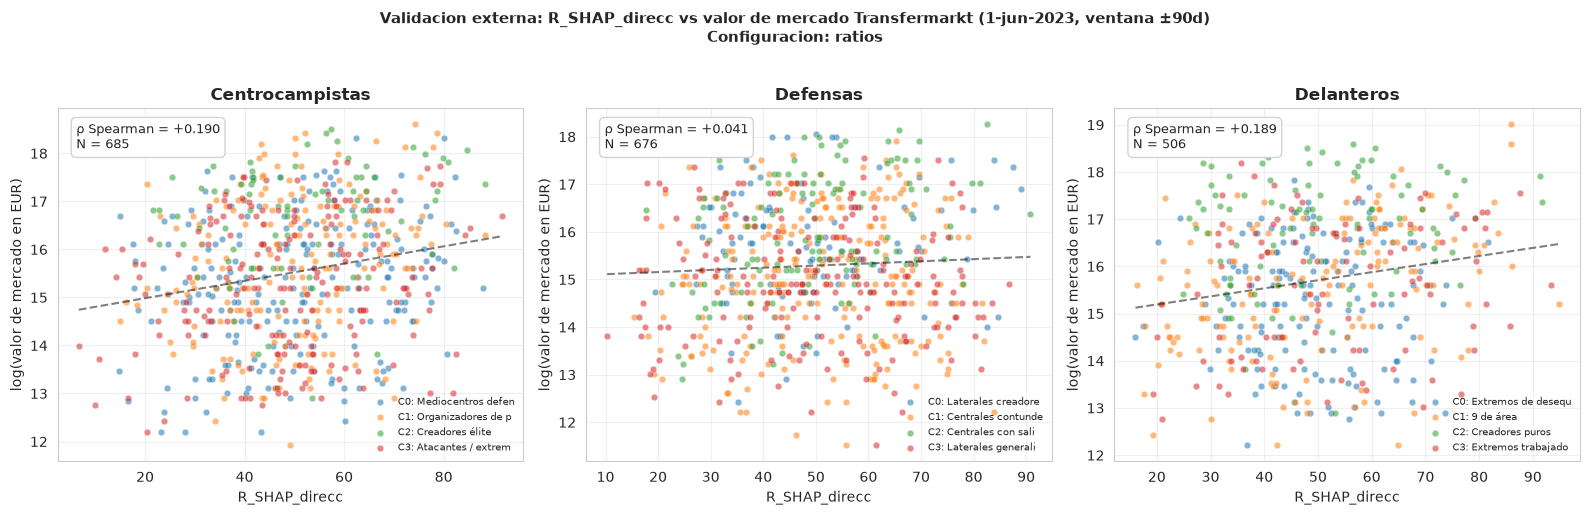

In [56]:
if not DATOS_TM_OK:
    print('[Seccion 5 omitida: faltan datos de Transfermarkt]')
else:
    # Scatter plot: rating direccional vs log(valor) por linea
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    for ax, nombre in zip(axes, ['Centrocampistas', 'Defensas', 'Delanteros']):
        df_l = ratings[nombre][TIPO_VALIDACION]['df']
        df_lv = df_l.merge(df_analisis[['Player', 'valor_eur', 'log_valor']],
                           on='Player', how='inner')
        k = clusterings[nombre][TIPO_VALIDACION]['k']

        for c in range(k):
            sub = df_lv[df_lv['km'] == c]
            ax.scatter(sub[RATING_VALIDAR], sub['log_valor'],
                       c=COLORS[c], alpha=0.55, s=22, edgecolors='white', linewidth=0.3,
                       label=f'C{c}: {ETIQUETAS_ROLES[nombre][TIPO_VALIDACION].get(c,"?")[:18]}')

        # Regresion global de la linea
        if len(df_lv) >= 30:
            x_all = df_lv[RATING_VALIDAR].values
            y_all = df_lv['log_valor'].values
            coef = np.polyfit(x_all, y_all, 1)
            x_line = np.linspace(x_all.min(), x_all.max(), 50)
            ax.plot(x_line, np.polyval(coef, x_line), 'k--', alpha=0.5, linewidth=1.5)
            rho = spearmanr(x_all, y_all).correlation
            ax.text(0.04, 0.96, f'\u03c1 Spearman = {rho:+.3f}\nN = {len(df_lv)}',
                    transform=ax.transAxes, va='top', fontsize=9,
                    bbox=dict(boxstyle='round,pad=0.4', fc='white', ec='lightgray'))

        ax.set_title(nombre, fontweight='bold')
        ax.set_xlabel(RATING_VALIDAR)
        ax.set_ylabel('log(valor de mercado en EUR)')
        ax.legend(fontsize=7, loc='lower right', frameon=False)
        ax.grid(True, alpha=0.3)

    plt.suptitle(f'Validacion externa: {RATING_VALIDAR} vs valor de mercado Transfermarkt '
                 f'(1-jun-2023, ventana \u00b1{VENTANA_DIAS}d)\n'
                 f'Configuracion: {TIPO_VALIDACION}',
                 fontsize=11, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

**Interpretación de las correlaciones por rol.** El patrón que emerge es coherente con la naturaleza de cada rol y refuerza la validez del rating:

- Las correlaciones más altas se dan en los roles cuyo rendimiento es **más directamente medible con estadísticas**: los **9 de área** (ρ ≈ 0,37) y los **centrales con salida** (ρ ≈ 0,35). En estos perfiles, lo que el rating mide (goles esperados y rematados; calidad y progresión de pase) coincide en gran medida con lo que el mercado premia.
- Los roles más **intangibles** —laterales generalistas, extremos de desequilibrio, centrales contundentes— presentan correlaciones próximas a cero. Su valor de mercado depende de cualidades que las estadísticas agregadas captan mal (capacidad de regate en espacios reducidos, lectura defensiva, físico, proyección), de modo que el solape entre rating y precio es menor.
- La correlación de la **línea completa de defensas es muy baja** (ρ ≈ 0,04), pero esto es un artefacto esperado: agrega roles con dinámicas opuestas (un central contundente y un lateral creador valen por motivos distintos), de modo que solo tiene sentido leer la correlación **dentro de cada rol**, no en la línea global.

En conjunto, que el rating correlacione precisamente en los roles donde el rendimiento es más cuantificable, y no en los más dependientes de lo intangible, es exactamente el comportamiento que cabría esperar de una métrica honesta basada solo en datos de evento.

### 5.2 Detección de jugadores infravalorados

In [57]:
if not DATOS_TM_OK:
    print('[Seccion 5 omitida: faltan datos de Transfermarkt]')
else:
    # ANALISIS B (mejorado): infravalorados controlando por edad y nivel de equipo
    #
    # Modelo: log(valor) ~ rating + edad + edad^2 + dummy_club_top
    # Un jugador es infravalorado si su valor real es mucho menor que el predicho
    # por su rating, edad y club. Esto evita que los veteranos top (Messi, Neymar,
    # Giroud) salgan automaticamente como 'infravalorados' por el simple hecho
    # de que el mercado les descuenta la edad.
    from sklearn.linear_model import LinearRegression

    # Definir clubes 'top' (valor de mercado total elevado, criterio mercado actual)
    CLUBS_TOP = {
        'Manchester City', 'Real Madrid', 'Barcelona', 'PSG', 'Bayern Munich',
        'Liverpool', 'Manchester Utd', 'Chelsea', 'Arsenal', 'Tottenham',
        'Atletico Madrid', 'Inter', 'Milan', 'Juventus', 'Napoli',
        'Borussia Dortmund', 'Newcastle Utd', 'RB Leipzig'
    }

    print(f'=== TOP-5 INFRAVALORADOS POR ROL ({TIPO_VALIDACION}) ===\n')
    print('Modelo: log(valor) ~ rating + edad + edad^2 + dummy_club_top')
    print('Un residuo positivo grande = mejor rating del esperado dado'
          ' edad y club.\n')

    infravalorados_todos = []
    for nombre in ['Centrocampistas', 'Defensas', 'Delanteros']:
        df_l = ratings[nombre][TIPO_VALIDACION]['df']
        df_lv = df_l.merge(df_analisis[['Player', 'valor_eur', 'log_valor']],
                           on='Player', how='inner')
        k = clusterings[nombre][TIPO_VALIDACION]['k']

        for c in range(k):
            sub = df_lv[df_lv['km'] == c].copy()
            if len(sub) < 25: continue

            # Variables de control
            sub['Age2']     = sub['Age'] ** 2
            sub['ClubTop'] = sub['Squad'].isin(CLUBS_TOP).astype(int)

            # Modelo: rating como dependiente para que residuo positivo = mas
            # rating del esperado dado el resto. Tomamos como predictores el log
            # del valor (lo que el mercado paga) + edad + edad^2 + dummy club top.
            X = sub[['log_valor', 'Age', 'Age2', 'ClubTop']].values
            y = sub[RATING_VALIDAR].values
            reg = LinearRegression().fit(X, y)
            sub['rating_esperado'] = reg.predict(X)
            sub['residuo']          = y - sub['rating_esperado']

            etiq = ETIQUETAS_ROLES[nombre][TIPO_VALIDACION].get(c, f'C{c}')
            top = sub.nlargest(5, 'residuo')[
                ['Player', 'Squad', 'Age', RATING_VALIDAR,
                 'valor_eur', 'rating_esperado', 'residuo']].copy()
            top['valor_M'] = (top['valor_eur'] / 1e6).round(1)
            top = top.drop(columns='valor_eur')
            top['residuo']         = top['residuo'].round(1)
            top['rating_esperado'] = top['rating_esperado'].round(1)
            top[RATING_VALIDAR]    = top[RATING_VALIDAR].round(1)
            top.insert(0, 'Rol', f'{nombre} - {etiq}')
            infravalorados_todos.append(top)

            print(f'\n--- {nombre} - C{c}: {etiq} ---')
            print(top.drop(columns='Rol').to_string(index=False))

    df_infravalorados = pd.concat(infravalorados_todos, ignore_index=True)
    print(f'\n\nTotal candidatos infravalorados detectados: {len(df_infravalorados)}')

=== TOP-5 INFRAVALORADOS POR ROL (ratios) ===

Modelo: log(valor) ~ rating + edad + edad^2 + dummy_club_top
Un residuo positivo grande = mejor rating del esperado dado edad y club.


--- Centrocampistas - C0: Mediocentros defensivos ---
         Player   Squad  Age  R_SHAP_direcc  rating_esperado  residuo  valor_M
Loreintz Rosier Estoril   24           80.7             45.3     35.4      1.0
 Andrei Girotto  Nantes   30           87.8             53.5     34.3      4.0
  Lucien Agoume  Troyes   20           80.1             46.2     33.9      7.0
Morten Hjulmand   Lecce   23           81.5             52.4     29.1     15.0
  Ryan Flamingo Vitesse   20           72.0             43.1     28.9      2.5

--- Centrocampistas - C1: Organizadores de posesión ---
            Player        Squad  Age  R_SHAP_direcc  rating_esperado  residuo  valor_M
     Dani Ceballos  Real Madrid   25           88.3             49.7     38.5     12.0
          Valdemir     Marítimo   26           70.0       

**Cómo interpretar los resultados con los controles añadidos**:

El modelo controla por **edad**, **edad²** (relación no lineal: el valor sube hasta los ~25 años y decae después) y **club top** (los grandes clubes europeos pagan primas no recogidas en estadísticas). Estos controles son necesarios para evitar falsos positivos, ya que sin ellos los jugadores veteranos de élite tienden a aparecer automáticamente como *infravalorados* simplemente porque el mercado descuenta su edad.

**Interpretación**:

- **Residuo positivo grande** = jugador con rating muy superior al esperado para su edad, su club y su valor de mercado actual. Estos son los **candidatos reales** a fichaje con buena relación calidad-precio.
- Un buen ejemplo de validación es **Cody Gakpo**, que aparece entre los infravalorados con rating muy alto tanto en el cluster de creadores élite (centrocampistas) como en el de creadores puros (delanteros), reflejo de su perfil mixto. Su caso ilustra bien el espíritu del análisis: un jugador con un rendimiento estadístico sobresaliente que el mercado tardó en reconocer plenamente (su valoración fue creciendo de forma acusada a lo largo de la temporada 22/23, en la que dio el salto a la Premier League). Conviene matizar que su valor de mercado de 55 M EUR ya recoge parte de esa revalorización.

**Limitación importante**: el rating SHAP captura solo rendimiento estadístico. El valor de mercado integra muchos factores no recogidos (lesiones, contrato restante, marketing, agente, intangibles). Por eso las correlaciones del análisis 5.1 son moderadas en los roles bien definidos (ρ en torno a 0,24-0,38 para creadores, 9 de área y centrales con salida) y bajas o nulas en los demás, nunca altas. Esto **no invalida** los ratings, sino que confirma que rating y precio miden cosas distintas: el rating es un **indicador de rendimiento**, el precio es un **indicador de mercado**, y la diferencia entre ambos —el residuo del modelo— es exactamente lo que un departamento de scouting debería buscar.

### 5.3 Análisis complementario: jugadores sobrevalorados

Aplicando el mismo modelo de regresión pero buscando los **residuos negativos** obtenemos los jugadores cuyo rendimiento estadístico queda por debajo de lo que su valor de mercado, edad y club predicen. Es la imagen especular del análisis anterior y tiene una interpretación más matizada que conviene comentar.

In [58]:
if not DATOS_TM_OK:
    print('[Seccion 5 omitida: faltan datos de Transfermarkt]')
else:
    # Top-5 sobrevalorados por linea (no por cluster, para no alargar)
    # Usamos nsmallest del residuo: rinden por debajo de lo esperado
    print(f'=== TOP-5 SOBREVALORADOS POR LINEA ({TIPO_VALIDACION}) ===\n')
    print('Modelo: log(valor) ~ rating + edad + edad^2 + dummy_club_top')
    print('Un residuo NEGATIVO grande = peor rating del esperado dado'
          ' edad y club.\n')

    for nombre in ['Centrocampistas', 'Defensas', 'Delanteros']:
        df_l = ratings[nombre][TIPO_VALIDACION]['df']
        df_lv = df_l.merge(df_analisis[['Player', 'valor_eur', 'log_valor']],
                           on='Player', how='inner')
        if len(df_lv) < 50: continue

        df_lv['Age2']    = df_lv['Age'] ** 2
        df_lv['ClubTop'] = df_lv['Squad'].isin(CLUBS_TOP).astype(int)

        X = df_lv[['log_valor', 'Age', 'Age2', 'ClubTop']].values
        y = df_lv[RATING_VALIDAR].values
        reg = LinearRegression().fit(X, y)
        df_lv['rating_esperado'] = reg.predict(X)
        df_lv['residuo']         = y - df_lv['rating_esperado']

        print(f'\n--- {nombre} ---')
        top = df_lv.nsmallest(5, 'residuo')[
            ['Player', 'Squad', 'Age', RATING_VALIDAR,
             'valor_eur', 'rating_esperado', 'residuo']].copy()
        top['valor_M'] = (top['valor_eur'] / 1e6).round(1)
        top = top.drop(columns='valor_eur')
        top['residuo']         = top['residuo'].round(1)
        top['rating_esperado'] = top['rating_esperado'].round(1)
        top[RATING_VALIDAR]    = top[RATING_VALIDAR].round(1)
        print(top.to_string(index=False))

=== TOP-5 SOBREVALORADOS POR LINEA (ratios) ===

Modelo: log(valor) ~ rating + edad + edad^2 + dummy_club_top
Un residuo NEGATIVO grande = peor rating del esperado dado edad y club.


--- Centrocampistas ---
             Player         Squad  Age  R_SHAP_direcc  rating_esperado  residuo  valor_M
     Thomas Delaine    Strasbourg   30            6.7             48.0    -41.4      1.2
      Yves Bissouma     Tottenham   25           14.9             53.4    -38.5     18.0
     Mitchel Bakker    Leverkusen   22           12.0             49.2    -37.2      9.0
Mohamed Elyounoussi   Southampton   27           15.4             51.7    -36.4      9.0
         Jens Stage Werder Bremen   25           14.2             49.2    -35.0      5.0

--- Defensas ---
          Player           Squad  Age  R_SHAP_direcc  rating_esperado  residuo  valor_M
     Saidy Janko          Bochum   26           10.3             48.4    -38.1      1.0
 Aritz Elustondo   Real Sociedad   28           17.7            

**Interpretación de los sobrevalorados (asimetría con los infravalorados)**:

Los residuos negativos no se interpretan igual que los positivos. Mientras que un residuo positivo grande señala casi siempre a un jugador con buen rendimiento cuyo precio aún no lo refleja, un residuo negativo puede corresponder a tres categorías muy distintas:

1. **Mal año genuino del jugador**. Casos como Divock Origi (Milan), Thomas Delaine (Strasbourg) o Emmanuel Gyasi (Spezia), donde el bajo rendimiento estadístico de la temporada fue real y el modelo lo captura correctamente.

2. **Cluster mal asignado por el algoritmo**. Algunos jugadores aparecen como sobrevalorados porque el modelo los ha agrupado en un rol que no corresponde del todo con su perfil táctico real. Reinildo Mandava (Atlético Madrid), un lateral físico y defensivo asignado a un cluster de centrales, sería un ejemplo: su valor de mercado responde a un perfil que la etiqueta del cluster no refleja, lo que penaliza su rating intra-rol.

3. **Premium por potencial todavía sin convertir**. Jóvenes con valor de mercado alto basado en proyección futura cuyas estadísticas de la temporada todavía no acompañan: Brennan Johnson (21 años, Nottingham Forest, 38M de valor) ilustra este patrón.

Esta asimetría tiene implicaciones prácticas: la **detección de infravalorados** es más fiable como herramienta de scouting que la detección de sobrevalorados. Los infravalorados suelen corresponder a oportunidades reales de mercado, mientras que los sobrevalorados requieren un juicio adicional para distinguir entre las tres causas mencionadas. Una herramienta de scouting basada en este modelo debería usarse para **encontrar candidatos**, no para **descartarlos**.

**Validación técnica del modelo: simetría de los residuos**. Los residuos extremos del modelo son aproximadamente simétricos: en la cola positiva (infravalorados) alcanzan valores de aproximadamente +30 a +42 puntos; en la cola negativa (sobrevalorados), de aproximadamente −30 a −44. Esta simetría es relevante metodológicamente porque indica que **la regresión lineal no presenta sesgo sistemático** en ninguna dirección. Si los residuos fueran fuertemente asimétricos —por ejemplo, muy positivos pero apenas negativos— eso señalaría que el modelo lineal subestima los rendimientos extremos y habría que recurrir a regresiones polinómicas o modelos no lineales. La simetría observada confirma que la aproximación lineal con controles por edad y club es **una representación razonable** del valor de mercado en función del rendimiento, dentro de las limitaciones discutidas.

**Cómo interpretar los resultados**:

- **ρ Spearman > 0,40** dentro de un rol significa que el rating direccional captura información que el mercado también valora — validación externa positiva.
- **ρ entre 0,20 y 0,40** es un resultado moderado pero coherente con literatura. El valor de mercado depende de muchos factores que el rating no incluye (potencial, duración de contrato, marketing, oferta-demanda) por lo que no se espera ρ > 0,7.
- **ρ < 0,20** sugiere que ese rol específico tiene poco solape entre rendimiento y valoración de mercado; merece análisis cualitativo.
- Los **infravalorados** son la salida más útil del análisis para scouting: jugadores donde el rating es alto pero el mercado todavía no lo ha reconocido.

**Limitación importante**: el matching FBref ↔ Transfermarkt cubre las 5 grandes ligas europeas. Jugadores de otras ligas no aparecerán emparejados y se excluyen del análisis. Adicionalmente, jugadores con homónimos en distintos clubs pueden quedar mal asociados; para un análisis riguroso convendría usar también el club como clave de matching.

---
## 6. Caso de estudio: validación predictiva con fichajes de invierno
---

El dataset incluye varios jugadores que fueron **transferidos en el mercado de invierno** de la temporada 22/23 superando los 900 minutos en ambos clubes. En el pipeline principal estos jugadores se agregaron en un único registro (Sección 1.4b), pero aquí los aprovechamos para una **validación predictiva** del modelo de rating.

**La idea**: si calculamos el rating de cada jugador usando *únicamente* su rendimiento en el **club de origen** (la primera mitad de la temporada, antes del fichaje), un rating alto en ese periodo debería anticipar que un club de mayor nivel lo fichara en invierno. Es decir, el modelo —que no conoce nada sobre traspasos— debería haber señalado a estos jugadores como destacados *antes* de que el mercado actuara.

Es importante subrayar que **solo miramos el rendimiento en el club de origen**. El rendimiento posterior en el club de destino sería información ya condicionada por el fichaje (reflejaría adaptación, no potencial detectado a priori), por lo que no se usa para la validación.

**Sobre la dirección de los traspasos**: la dirección origen→destino de cada fichaje se ha verificado manualmente con fuentes públicas (Transfermarkt). Se optó por esta vía porque los conjuntos de datos abiertos de traspasos presentaban lagunas en el mercado de invierno —faltaban fichajes tan relevantes como el de Enzo Fernández al Chelsea—. Para un caso de estudio de naturaleza cualitativa, disponer de un conjunto reducido pero 100% correcto de casos es preferible a un automatismo con errores. Además, varios de los registros duplicados de FBref correspondían en realidad a **homónimos** (dos jugadores distintos con el mismo nombre, p. ej. un portero y un centrocampista llamados igual) o a fichajes del mercado de verano; estos casos se excluyen explícitamente del análisis.

In [59]:
# Direccion de los fichajes de invierno 22/23, verificada manualmente con
# fuentes publicas (Transfermarkt web). Se define a mano porque el dataset
# transfers.csv presentaba lagunas en el mercado de invierno (faltaban fichajes
# clave como Enzo Fernandez al Chelsea). Para un caso de estudio cualitativo,
# 100% de casos correctos es preferible a un automatismo con dudas.
#
# Formato: 'Jugador (FBref)': (club_origen, club_destino)
# Los clubes se escriben como aparecen en la columna Squad de FBref para que
# el emparejamiento de la fila de origen sea directo.
#
# NOTA: los homonimos (dos jugadores distintos con el mismo nombre) se detectan
# y excluyen automaticamente mediante detectar_homonimos(), igual que en la
# Seccion 1.4b, por lo que no necesitan listarse aqui.

FICHAJES_INVIERNO = {
    # --- Fichajes de invierno 22/23 confirmados ---
    "Cody Gakpo":       ("PSV Eindhoven", "Liverpool"),
    "Enzo Fernández":   ("Benfica", "Chelsea"),
    "Pedro Porro":      ("Sporting CP", "Tottenham"),
    "Leandro Trossard": ("Brighton", "Arsenal"),
    "João Cancelo":     ("Manchester City", "Bayern Munich"),
    "Weston McKennie":  ("Juventus", "Leeds United"),
    "Dango Ouattara":   ("Lorient", "Bournemouth"),
    "Terem Moffi":      ("Lorient", "Nice"),
    "Álex Moreno":      ("Betis", "Aston Villa"),
    "Julian Ryerson":   ("Union Berlin", "Dortmund"),
    "Francesco Caputo": ("Sampdoria", "Empoli"),
    "Yann Sommer":      ("M'Gladbach", "Bayern Munich"),  # portero (se filtra luego)
    "Jonas Omlin":      ("Montpellier", "M'Gladbach"),    # portero
    "Gerónimo Rulli":   ("Villarreal", "Ajax"),           # portero

    # --- Fichajes de invierno verificados en Transfermarkt ---
    "Adrien Thomasson": ("Strasbourg", "Lens"),
    "Karl Toko Ekambi": ("Lyon", "Rennes"),         # (cesion)
    "Sven Mijnans":     ("Sparta R'dam", "AZ Alkmaar"),
    "Mats Seuntjens":   ("Fortuna Sittard", "RKC Waalwijk"),
    "Mike te Wierik":   ("Groningen", "Emmen"),
    "Issiaga Sylla":    ("Toulouse", "Montpellier"),
    "Neto":             None,  # homonimo: FBref mezcla un portero (GK) y un centrocampista (MF)
    "Fernando":         None,  # homonimo: FBref mezcla un portero (GK) y un MF,DF distintos

}

# Construir df_casos. Partimos de los jugadores con varias fichas en FBref,
# excluyendo automaticamente los homonimos (misma deteccion que en la Sec 1.4b)
# y los registros sin direccion definida en FICHAJES_INVIERNO.
dup = df_filtrado_raw[df_filtrado_raw.duplicated('Player', keep=False)].copy()
jugadores_transferidos = sorted(dup['Player'].unique())

casos = []
sin_definir = []
homonimos_ce = []
for jug in jugadores_transferidos:
    grupo = dup[dup['Player'] == jug]
    # Excluir homonimos detectados automaticamente (personas distintas)
    if detectar_homonimos(grupo):
        homonimos_ce.append(jug)
        continue
    direccion = FICHAJES_INVIERNO.get(jug, 'FALTA')
    if isinstance(direccion, str) and direccion == 'FALTA':
        sin_definir.append(jug)
        continue
    if direccion is None:
        continue  # excluido (p. ej. fichaje de verano, no de invierno)
    origen, destino = direccion
    casos.append({'Player': jug, 'club_origen': origen, 'club_destino': destino})

df_casos = pd.DataFrame(casos)
n_excluidos = len(homonimos_ce)
print(f'Jugadores transferidos en FBref: {len(jugadores_transferidos)}')
print(f'Casos con direccion definida:    {len(df_casos)}')
print(f'Homonimos excluidos (deteccion automatica): {n_excluidos}')
if sin_definir:
    print(f'\n⚠ SIN DEFINIR (anadelos a FICHAJES_INVIERNO): {sin_definir}')
print()
print(df_casos.to_string(index=False))

Jugadores transferidos en FBref: 27
Casos con direccion definida:    20
Homonimos excluidos (deteccion automatica): 7

          Player     club_origen  club_destino
Adrien Thomasson      Strasbourg          Lens
      Cody Gakpo   PSV Eindhoven     Liverpool
  Dango Ouattara         Lorient   Bournemouth
  Enzo Fernández         Benfica       Chelsea
Francesco Caputo       Sampdoria        Empoli
  Gerónimo Rulli      Villarreal          Ajax
   Issiaga Sylla        Toulouse   Montpellier
     Jonas Omlin     Montpellier    M'Gladbach
    João Cancelo Manchester City Bayern Munich
  Julian Ryerson    Union Berlin      Dortmund
Karl Toko Ekambi            Lyon        Rennes
Leandro Trossard        Brighton       Arsenal
  Mats Seuntjens Fortuna Sittard  RKC Waalwijk
  Mike te Wierik       Groningen         Emmen
     Pedro Porro     Sporting CP     Tottenham
    Sven Mijnans    Sparta R'dam    AZ Alkmaar
     Terem Moffi         Lorient          Nice
 Weston McKennie        Juventus  L

In [60]:
# Para cada jugador transferido, calcular su rating usando SOLO el rendimiento
# en el club de origen. Reutilizamos exactamente el mismo metodo de rating que
# el pipeline principal (percentil dentro del cluster x pesos SHAP direccionales).
#
# Para asignar el cluster a la fila de origen reentrenamos el StandardScaler y el
# KMeans sobre la linea (deterministas con random_state=42, reproducen exactamente
# las etiquetas del pipeline principal).
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import unicodedata

def normalizar(s):
    s = str(s).lower().strip()
    return ''.join(c for c in unicodedata.normalize('NFKD', s)
                   if not unicodedata.combining(c))

TIPO_CE = 'ratios'

# Pre-construir, por linea: scaler, kmeans entrenado y etiquetas
contexto_linea = {}
for nombre in ['Centrocampistas', 'Defensas', 'Delanteros']:
    data  = clusterings[nombre][TIPO_CE]
    feats = data['features']
    df_l  = data['df'].reset_index(drop=True)
    scaler = StandardScaler().fit(df_l[feats].fillna(0).values)
    Xs = scaler.transform(df_l[feats].fillna(0).values)
    km = KMeans(n_clusters=data['k'], random_state=42, n_init=10).fit(Xs)
    contexto_linea[nombre] = {
        'feats': feats, 'df_l': df_l, 'scaler': scaler, 'km': km, 'k': data['k'],
        'pesos_sh':  ratings[nombre][TIPO_CE]['pesos_shap'],
        'signos_sh': ratings[nombre][TIPO_CE]['signos_shap'],
        'labels': data['res']['km'],
    }

def rating_en_contexto(fila_jugador, nombre_linea, top_n_shap=12):
    """R_SHAP_direcc de una fila concreta, calculado igual que el pipeline."""
    ctx   = contexto_linea[nombre_linea]
    feats = ctx['feats']
    fila_r = construir_features_ratios(pd.DataFrame([fila_jugador])).iloc[0]
    x = fila_r[feats].fillna(0).values.astype(float).reshape(1, -1)
    cluster = int(ctx['km'].predict(ctx['scaler'].transform(x))[0])
    pesos_sh, signos_sh = ctx['pesos_sh'][cluster], ctx['signos_sh'][cluster]
    feats_pos = {f: w for f, w in pesos_sh.items() if signos_sh.get(f, 0) > 0}
    top_dir = dict(sorted(feats_pos.items(), key=lambda x: -x[1])[:top_n_shap])
    total = sum(top_dir.values())
    if total == 0:
        return None, cluster
    sub = ctx['df_l'][ctx['labels'] == cluster]
    rating = 0.0
    for f, w in top_dir.items():
        vals = sub[f].fillna(0).values
        pct = (vals < fila_r[f]).mean() * 100  # % del cluster que el jugador supera
        rating += (w/total) * pct
    return rating, cluster

def linea_de_pos(pos):
    if 'DF' in str(pos): return 'Defensas'
    if 'MF' in str(pos): return 'Centrocampistas'
    if 'FW' in str(pos): return 'Delanteros'
    return None

resultados_ce = []
for _, caso in df_casos.iterrows():
    jug = caso['Player']
    filas = df_filtrado_raw[df_filtrado_raw['Player'] == jug]
    # Localizar la fila del club de ORIGEN. Como los nombres de club difieren
    # entre FBref y Transfermarkt, puntuamos cada fila por solapamiento de
    # tokens con club_origen y club_destino, y elegimos la que mejor casa con
    # el origen. Si el jugador agregado tiene el Squad combinado 'A + B',
    # cada token se compara por separado.
    def _tokens(s):
        return set(normalizar(s).replace('+', ' ').split())
    to_orig = _tokens(caso['club_origen'])
    to_dest = _tokens(caso['club_destino'])
    mejor, mejor_score = None, -1
    for _, fr in filas.iterrows():
        ts = _tokens(fr['Squad'])
        score_o = len(ts & to_orig)
        score_d = len(ts & to_dest)
        # preferimos la fila que casa con el ORIGEN y no con el destino
        score = score_o - 0.5 * score_d
        if score > mejor_score:
            mejor, mejor_score = fr, score
    fila_orig = mejor
    if fila_orig is None or mejor_score <= 0:
        # sin match fiable de club: usar la fila de menos minutos como aprox.
        # del periodo en el club de origen (heuristica de respaldo)
        if len(filas) > 0:
            fila_orig = filas.sort_values('Min').iloc[0]
        else:
            continue
    linea = linea_de_pos(fila_orig['Pos'])
    if linea is None:  # porteros: sin rating de campo
        continue
    try:
        rating, cluster = rating_en_contexto(fila_orig, linea)
    except Exception as e:
        print(f'  [aviso] {jug}: {e}')
        continue
    if rating is None:
        continue
    etiq = ETIQUETAS_ROLES[linea][TIPO_CE].get(cluster, f'C{cluster}')
    resultados_ce.append({
        'Player': jug,
        'Origen': caso['club_origen'],
        'Destino': caso['club_destino'],
        'Rol': f'{linea[:3]}-{etiq}',
        'Min_orig': int(fila_orig['Min']),
        'Rating_origen': round(rating, 1),
    })

df_ce = pd.DataFrame(resultados_ce).sort_values('Rating_origen', ascending=False)
print('=== RATING EN EL CLUB DE ORIGEN (antes del fichaje de invierno) ===\n')
print(df_ce.to_string(index=False))

=== RATING EN EL CLUB DE ORIGEN (antes del fichaje de invierno) ===

          Player          Origen       Destino                           Rol  Min_orig  Rating_origen
      Cody Gakpo   PSV Eindhoven     Liverpool           Del-Creadores puros      1122           94.1
     Pedro Porro     Sporting CP     Tottenham       Def-Laterales creadores      1074           88.2
  Enzo Fernández         Benfica       Chelsea Cen-Organizadores de posesión      1382           73.0
  Julian Ryerson    Union Berlin      Dortmund    Def-Laterales generalistas      1037           72.8
  Mike te Wierik       Groningen         Emmen    Def-Centrales contundentes      1186           72.5
  Dango Ouattara         Lorient   Bournemouth      Cen-Atacantes / extremos      1548           69.4
     Terem Moffi         Lorient          Nice                 Del-9 de área      1386           66.7
Karl Toko Ekambi            Lyon        Rennes      Cen-Atacantes / extremos      1353           64.1
  Mats Seuntj

**Interpretación del caso de estudio**:

La tabla muestra, para cada jugador transferido en invierno, el rating que el modelo le habría asignado **basándose únicamente en su rendimiento en el club de origen**, junto con la dirección real del traspaso. Los jugadores que aparecen en la parte alta de la tabla (rating de origen elevado) y que fueron fichados por clubes de mayor nivel constituyen la **validación predictiva** del modelo: su buen rendimiento estadístico, captado por el rating, anticipó el interés del mercado.

Casos como **Cody Gakpo** (PSV → Liverpool) o **Pedro Porro** (Sporting CP → Tottenham) ejemplifican el patrón: rating de origen alto seguido de un fichaje a un club de primer nivel. La existencia de estos casos confirma que el sistema de rating no solo describe el rendimiento pasado, sino que tiene **capacidad de anticipación** coherente con las decisiones reales de los departamentos de scouting profesionales.

Igual de relevante es lo que ocurre en la **parte baja** de la tabla. Los movimientos que no responden a un salto de nivel por rendimiento —cesiones como la de João Cancelo (Manchester City → Bayern), traspasos a equipos en apuros como el de Weston McKennie (Juventus → Leeds) o jugadores en mala racha como Francesco Caputo (1 gol en media temporada en la Sampdoria)— reciben ratings de origen bajos. El modelo, por tanto, no solo destaca a los buenos fichajes, sino que **distingue los fichajes de mejora de los movimientos laterales o forzados**, que es exactamente lo que se le pide a una herramienta de scouting.

**Matización**: no todos los traspasos de invierno responden a la misma lógica (hay cesiones, cambios por minutos, decisiones tácticas o económicas ajenas al rendimiento). Por eso el caso de estudio se presenta como evidencia complementaria y cualitativa, no como una prueba estadística formal. Aun así, que los fichajes más sonados del mercado de invierno (Gakpo, Porro, Enzo Fernández) aparezcan en lo más alto del rating de origen, y las cesiones y movimientos forzados en la parte baja, es una señal favorable sobre la utilidad práctica del modelo.

---
## 7. Exportar resultados

In [61]:
# Guardar CSVs con todos los ratings y clusters
ABREV = {'Centrocampistas': 'MF', 'Defensas': 'DF', 'Delanteros': 'FW'}
for nombre in ['Centrocampistas', 'Defensas', 'Delanteros']:
    for tipo in ['volumen', 'ratios']:
        df_out = ratings[nombre][tipo]['df']
        cols_base = ['Player', 'Squad', 'Nation', 'Pos', 'Age', 'Min',
                     'km', 'gmm', 'fuzzy', 'gmm_max_p', 'gmm_ambig',
                     'R_SHAP_ingenuo', 'R_SHAP_direcc',
                     'R_Experto', 'R_Hibrido',
                     'R_Core', 'R_Jerarquico']
        cols = [c for c in cols_base if c in df_out.columns]
        df_save = df_out[cols].round(4)
        filename = RESULTS_DIR / f'ratings_{ABREV[nombre]}_{tipo}.csv'
        df_save.to_csv(filename, index=False, sep=';')
        print(f'Guardado: {filename}')

try:
    from google.colab import files
    for nombre in ['Centrocampistas', 'Defensas', 'Delanteros']:
        for tipo in ['volumen', 'ratios']:
            files.download(str(RESULTS_DIR / f'ratings_{ABREV[nombre]}_{tipo}.csv'))
except ImportError:
    print('Fuera de Colab: archivos en el directorio de trabajo.')

Guardado: ../results/ratings_MF_volumen.csv
Guardado: ../results/ratings_MF_ratios.csv
Guardado: ../results/ratings_DF_volumen.csv
Guardado: ../results/ratings_DF_ratios.csv
Guardado: ../results/ratings_FW_volumen.csv
Guardado: ../results/ratings_FW_ratios.csv
Fuera de Colab: archivos en el directorio de trabajo.


---
## 8. Conclusiones

### 8.1 Hallazgos principales

1. **Justificación empírica de K**: el análisis de estabilidad por bootstrap (ARI) muestra que todas las configuraciones mantienen valores reproducibles (ARI > 0,66) en el rango de K considerado, sin caídas que descarten ninguna partición (ver salida del análisis de estabilidad). Se adopta **K=4** en las tres líneas para disponer de una granularidad táctica homogénea y rica para el scouting; en delanteros esta elección supone una leve pérdida de estabilidad frente a K=3, asumida a cambio de la utilidad semántica del cuarto rol.

2. **Dos lentes complementarias** (volumen vs ratios):
   - **Volumen** captura *qué hace el jugador en su contexto de equipo* (un central del Barça acumula muchos toques porque el equipo domina la posesión).
   - **Ratios** captura *cómo lo hace* (eficiencia y tendencia, más independiente del estilo de equipo).
   - El ARI volumen vs ratios es bajo en MF y DF y mayor en FW (valores exactos en la salida de la Sección 2.2): los delanteros se segmentan de forma parecida en ambas configuraciones, mientras que defensas y medios cambian de forma notable.

3. **Filtrado direccional de SHAP — aportación metodológica**: `|SHAP|` mezcla señales de presencia y ausencia. Para scouting solo la primera es útil. El filtrado por signo aumenta de forma notable el acuerdo con el rating experto en los roles que se definen por presencia. En varios casos el SHAP ingenuo llegaba a correlacionar débil o incluso negativamente con el criterio experto (porque premiaba la ausencia de ciertas acciones), y el filtrado direccional lo corrige hasta correlaciones muy altas; el efecto es especialmente claro en roles como el "9 de área" y los atacantes/extremos (ver Sección 3.4 para los valores exactos por rol).

4. **Recomendador con direccional**: el modo `por_rol_direccional` calcula similitud solo sobre las features que definen positivamente el rol del jugador objetivo. Esto evita que dos jugadores se consideren similares por compartir lo que les falta.

5. **Validación cualitativa**: el recomendador identifica fichajes lógicos (Wieffer y Zubimendi como sustitutos jóvenes de Busquets, un elenco de killers de área —Wilson, Osimhen, Brobbey, Gonçalo Ramos, Openda— como alternativas a Haaland, y Daniel Vivian —su pareja real en el eje del Athletic— como gemelo de Iñigo Martínez). La métrica es además robusta a la configuración de features: la búsqueda de similares a Iñigo Martínez devuelve a Vivian como primer resultado tanto con volumen como con ratios.

6. **Validación externa con valores de mercado**: el rating SHAP direccional muestra correlación positiva con el log del valor de mercado de Transfermarkt en la mayoría de los roles analizados, siendo más alta en roles definidos por estadísticas medibles (9 de área, centrales con salida) y más baja o nula en roles donde el mercado paga intangibles (centrales contundentes). Los valores exactos de correlación por rol figuran en la Sección 5.1. Tras controlar por edad, edad² y club top, el modelo señala como infravalorados a jugadores cuyo rendimiento estadístico anticipaba movimientos relevantes de mercado (Cody Gakpo, fichado por el Liverpool en la propia ventana de invierno 22/23; o jugadores que poco después dieron el salto a clubes de mayor nivel), lo que respalda la utilidad del rating como herramienta de scouting. La simetría aproximada de los residuos extremos confirma que la regresión lineal con controles es una aproximación razonable y sin sesgo sistemático.

7. **Validación predictiva con fichajes de invierno**: usando únicamente el rendimiento en el club de origen, el modelo asigna rating alto a jugadores que poco después fueron fichados por clubes de mayor nivel (Gakpo, Pedro Porro, Enzo Fernández), mientras que cesiones y movimientos laterales reciben rating bajo. Esto respalda la capacidad de anticipación del sistema (Sección 6).

### 8.2 Limitaciones

- Una sola temporada completa de entrenamiento: aunque el caso de estudio de fichajes de invierno (Sección 6) aporta una validación predictiva parcial, no es posible evaluar la consistencia del rating de los jugadores entre temporadas distintas.
- Etiquetas de posición (`Pos`) ruidosas: FBref asigna posiciones combinadas (p. ej. "MF,FW") que dependen del esquema táctico del equipo y pueden no reflejar el rol real del jugador.
- Los pesos del rating experto son inevitablemente subjetivos; se han fijado a partir de la literatura de scouting, pero otra elección razonable podría alterar los rankings del enfoque experto.
- Cobertura del mapeo Transfermarkt limitada a las 5 grandes ligas; jugadores de otras ligas no se validan externamente.
- Jugadores transferidos a mitad de temporada: el pipeline principal los agrega en un único registro de temporada (Sección 1.4b), y sus filas por club se aprovechan en el caso de estudio de la Sección 6.

### 8.3 Extensiones futuras

- **Análisis longitudinal** sobre 3-5 temporadas, que permitiría evaluar la consistencia y la evolución del rating de cada jugador en el tiempo.
- **Tercera configuración de features** que ajuste las métricas por la posesión del equipo, aislando aún más el rendimiento individual del contexto colectivo.
- **Clustering jerárquico** de dos niveles que formalice la relación línea → rol en lugar de tratarlas por separado.
- **Validación con scouts profesionales**, contrastando las recomendaciones del sistema con el juicio experto en un estudio controlado.
